## Frozen poverty-definition decision
The investigator confirmed retaining the poverty definition used by the frozen development pipeline. Its original source-year construction issue is documented in `../docs/11_explicacion_y_sensibilidad.md`. It was not corrected or isolated in this evaluation, and no poverty-correction branch is pursued in this closure. The held-out results remain conditional on the trained predictor definition; no new model is selected from these results.

## Evaluation contract
Models were retained in development before this evaluation: **b** = SHAP readmission, stratified by treatment setting and discharge for violation of facility rules; **e** = SHAP mortality, stratified by treatment setting and physical comorbidity; **d** = Full mortality without the collinear indicator, stratified by setting and discharge. No interaction or functional-form selection is reopened here.
The holdout was separated before imputation, ML tuning and SHAP discovery in the rebuilt pipeline. Development preprocessing was completed before internal CV: independence within internal CV is therefore not claimed. Holdout outcomes enter evaluation only.
```{mermaid}
flowchart TD
  A[00: partition before imputation] --> B[01-03 and 06-08: development discovery and decisions]
  B --> C[Freeze b, e and Full mortality d]
  C --> D[Fit once per development imputation]
  D --> E[09: predict every held-out person]
  E --> F[Net risk plus named readmission CIF branches]
  F --> G[Patient bootstrap; models stay fixed]
  D --> H[10 and 11: frozen additional-cohort evaluation]
```
Historical controls run before accepting new results. The manuscript is read only. A change at its reported rounding is flagged, not silently reconciled by changing the selected model.

In [1]:
#| label: eval-config-and-environment
#| message: false
.t0 <- proc.time()
# Resolve every input and output through the one project configuration.
project_root <- normalizePath(getwd(), winslash="/", mustWork=TRUE)
while(!file.exists(file.path(project_root,"config.yml"))) {
  parent <- dirname(project_root)
  if(identical(parent,project_root)) stop("Run this notebook from the configured project.")
  project_root <- parent
}
config <- yaml::read_yaml(file.path(project_root,"config.yml"))
resolve_path <- function(x) if(grepl("^([A-Za-z]:|/)",x)) x else file.path(project_root,x)
.libPaths(c(vapply(config$runtime$r_libraries,resolve_path,character(1)),.libPaths()))
Sys.setenv(OMP_NUM_THREADS="1",OPENBLAS_NUM_THREADS="1",MKL_NUM_THREADS="1",VECLIB_MAXIMUM_THREADS="1")
stopifnot(nzchar(Sys.setlocale("LC_CTYPE",if(.Platform$OS.type=="windows")"English_United States.utf8" else "C.UTF-8")))
settings <- config$heldout_evaluation
RNGkind("Mersenne-Twister","Inversion","Rejection")
set.seed(settings$seed)
future::plan(future::sequential)
options(future.globals.maxSize=12*1024^3,parallelly.makeNodePSOCK.setup_strategy="sequential",parallelly.makeNodePSOCK.connectTimeout=600)
stopifnot(settings$workers<=6L,settings$bootstrap_replicates==1000L)
HORIZONS <- as.numeric(settings$horizons_months)
EVAL_TIMES <- sort(unique(c(3,HORIZONS)))
GRID <- sort(unique(c(0,seq(0, max(HORIZONS),by=settings$ibs_grid_step_months),EVAL_TIMES)))
SEED <- as.integer(settings$seed)
B <- as.integer(settings$bootstrap_replicates)
written_files <- character()
output_file <- function(group,name) file.path(resolve_path(config$paths[[group]]),name)
for(p in config$paths) dir.create(resolve_path(p),recursive=TRUE,showWarnings=FALSE)
show_table <- function(data, caption) {
  widget <- htmltools::browsable(htmltools::tags$div(class = "article2-table", role = "region", tabindex = 0, `aria-label` = caption, style = "max-height:420px;overflow:auto;max-width:100%;border:1px solid #ddd;padding:0.4rem;margin-bottom:0.8rem;", htmltools::HTML(knitr::kable(data, format = "html", caption = caption, row.names = FALSE, digits = 4, escape = TRUE))))
  IRdisplay::display_html(as.character(widget))
  invisible(widget)
}
cache_object <- function(key,compute,signature=analysis_signature) {
  directory <- resolve_path(config$paths$objects)
  old <- list.files(directory,pattern=paste0("^",key,"_[0-9-]+_",signature,"[.]rds$"),full.names=TRUE)
  if(length(old)>1L) stop("Ambiguous cache: ",key)
  path <- if(length(old)) old else file.path(directory,paste0(key,"_",Sys.Date(),"_",signature,".rds"))
  if(file.exists(path)) {
    saved <- readRDS(path)
    stopifnot(identical(saved$signature,signature))
    value <- saved$value
    message("Reused ",basename(path))
  } else {
    value <- compute()
    saveRDS(list(signature=signature,created_at=format(Sys.time(),"%Y-%m-%dT%H:%M:%S%z"),value=value),path,compress=FALSE)
    message("Saved ",basename(path))
  }
  written_files <<- unique(c(written_files,path))
  value
}
write_table <- function(x,stem) {
  path <- output_file("tables",paste0(stem,"_",Sys.Date(),"_",analysis_signature,".csv"))
  utils::write.csv(as.data.frame(x),path,row.names=FALSE,na="")
  written_files <<- unique(c(written_files,path))
  path
}
show_table(data.frame(notebook="09_prediction23_converted_mod.ipynb",language=R.version.string,environment="r-main / ir",activation="Select ir; libraries from config before launch",workers=settings$workers,threads=1L),"Verified runtime contract")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))

notebook,language,environment,activation,workers,threads
09_prediction23_converted_mod.ipynb,R version 4.4.1 (2024-06-14 ucrt),r-main / ir,Select ir; libraries from config before launch,6,1


Elapsed: 0.005 minutes


In [2]:
#| label: eval-original-formula-functions
#| message: false
.t0 <- proc.time()
Surv <- survival::Surv
strata <- survival::strata
Hist <- prodlim::Hist
to01 <- function(x) {
    if (is.logical(x)) {
        return(as.integer(x))
    }
    if (is.factor(x)) {
        x <- as.character(x)
    }
    x_num <- suppressWarnings(as.numeric(x))
    vals <- x_num[!is.na(x_num)]
    if (length(vals) == 0L) {
        stop("event column has no non-missing values.")
    }
    if (all(vals %in% c(0, 1))) {
        return(as.integer(x_num))
    }
    if (all(vals %in% c(1, 2))) {
        return(as.integer(x_num - 1L))
    }
    stop("event column must be binary 0/1 (or 1/2).")
}
ibs_ipcw_train <- function(df_train, df_test, surv_mat, times, time_col, event_col, eps = 1e-08, g_min = 0.05) {
    ev_train <- to01(df_train[[event_col]])
    sf_cens <- survival::survfit(survival::Surv(df_train[[time_col]], 1 - ev_train) ~ 1)
    safe_times <- sf_cens$time[sf_cens$surv >= g_min]
    tau_ipcw <- if (length(safe_times)) 
        max(safe_times)
    else max(times)
    train_time_max <- max(df_train[[time_col]], na.rm = TRUE)
    keep <- times <= tau_ipcw & times <= train_time_max
    if (sum(keep) < 2L) {
        return(NA_real_)
    }
    times_use <- times[keep]
    surv_use <- surv_mat[, keep, drop = FALSE]
    G_at <- function(tt) {
        requested_times <- pmax(as.numeric(tt), 0)
        unique_times <- sort(unique(requested_times))
        g_unique <- as.numeric(summary(sf_cens, times = unique_times, extend = TRUE)$surv)
        if (length(g_unique) != length(unique_times)) {
            stop("Censoring-survival lookup returned an unexpected length.")
        }
        lookup_index <- match(requested_times, unique_times)
        if (anyNA(lookup_index)) {
            stop("Censoring-survival lookup could not restore request order.")
        }
        pmax(g_unique[lookup_index], g_min)
    }
    Tt <- as.numeric(df_test[[time_col]])
    Dt <- to01(df_test[[event_col]])
    bs_t <- vapply(seq_along(times_use), function(j) {
        t0 <- times_use[j]
        S0 <- surv_use[, j]
        Y0 <- as.numeric(Tt > t0)
        w <- ifelse(Tt <= t0 & Dt == 1L, 1/G_at(pmax(Tt - eps, 0)), ifelse(Tt > t0, 1/G_at(t0), 0))
        mean(w * (Y0 - S0)^2, na.rm = TRUE)
    }, numeric(1))
    denom <- max(times_use) - min(times_use)
    if (!is.finite(denom) || denom <= 0) {
        return(NA_real_)
    }
    as.numeric(sum(diff(times_use) * (head(bs_t, -1L) + tail(bs_t, -1L))/2)/denom)
}
.dual_cox_normalize_call_name <- function(fun_expr) {
    txt <- paste(deparse(fun_expr, width.cutoff = 500L), collapse = "")
    txt <- gsub("`", "", txt, fixed = TRUE)
    sub("^.*::+", "", txt)
}
.dual_cox_rewrite_strata_calls <- function(expr) {
    if (!is.call(expr)) {
        return(expr)
    }
    node_name <- .dual_cox_normalize_call_name(expr[[1L]])
    if (node_name %in% c("strat", "strata")) {
        expr[[1L]] <- str2lang("survival::strata")
    }
    for (i in seq_along(expr)) {
        expr[[i]] <- .dual_cox_rewrite_strata_calls(expr[[i]])
    }
    expr
}
.dual_cox_collect_explicit_factor_vars <- function(expr) {
    vars <- character(0)
    walk <- function(node) {
        if (!is.call(node)) {
            return(invisible(NULL))
        }
        node_name <- .dual_cox_normalize_call_name(node[[1L]])
        if (node_name %in% c("factor", "as.factor")) {
            factor_vars <- unique(all.vars(node[[2L]]))
            if (length(factor_vars) != 1L) {
                stop("Explicit categorical coercion must reference exactly one column in term '", paste(deparse(node, width.cutoff = 500L), collapse = ""), "'.", call. = FALSE)
            }
            vars <<- c(vars, factor_vars)
        }
        if (length(node) >= 2L) {
            for (i in 2L:length(node)) {
                walk(node[[i]])
            }
        }
        invisible(NULL)
    }
    walk(expr)
    unique(vars)
}
.dual_cox_collect_observed_levels <- function(x) {
    raw <- as.character(x)
    sort(unique(raw[!is.na(x)]), method = "radix")
}
.dual_cox_format_level_sets <- function(level_sets) {
    paste(vapply(seq_along(level_sets), function(i) {
        sprintf("imputation %d: [%s]", i, paste(level_sets[[i]], collapse = ", "))
    }, character(1)), collapse = "; ")
}
.dual_cox_sanitize_level_name <- function(var, level) {
    paste0(var, "__", make.names(as.character(level)))
}
.dual_cox_build_level_mapping <- function(var, raw_levels) {
    sanitized <- vapply(raw_levels, function(level) .dual_cox_sanitize_level_name(var, level), character(1))
    sanitized <- make.unique(sanitized, sep = "__dup")
    stats::setNames(sanitized, raw_levels)
}
.dual_cox_prepare_model_split <- function(train, test, categorical_formula_vars) {
    train_out <- train
    test_out <- test
    for (var in categorical_formula_vars) {
        if (!var %in% names(train_out)) {
            next
        }
        train_raw <- train_out[[var]]
        test_raw <- test_out[[var]]
        train_chr <- as.character(train_raw)
        test_chr <- as.character(test_raw)
        train_levels <- .dual_cox_collect_observed_levels(train_raw)
        if (length(train_levels) == 0L) {
            next
        }
        unseen <- !is.na(test_raw) & !(test_chr %in% train_levels)
        if (any(unseen)) {
            return(list(train = train_out, test = test_out, error = paste0("unseen_factor_level:", var)))
        }
        mapping <- .dual_cox_build_level_mapping(var, train_levels)
        train_sanitized <- rep(NA_character_, length(train_chr))
        test_sanitized <- rep(NA_character_, length(test_chr))
        train_non_missing <- !is.na(train_raw)
        test_non_missing <- !is.na(test_raw)
        train_sanitized[train_non_missing] <- unname(mapping[train_chr[train_non_missing]])
        test_sanitized[test_non_missing] <- unname(mapping[test_chr[test_non_missing]])
        train_out[[var]] <- factor(train_sanitized, levels = unname(mapping))
        test_out[[var]] <- factor(test_sanitized, levels = unname(mapping))
    }
    list(train = train_out, test = test_out, error = "")
}
.dual_cox_expr_label <- function(expr) {
    paste(deparse(expr, width.cutoff = 500L), collapse = "")
}
.dual_cox_collect_strata_term_labels <- function(expr) {
    labels <- character(0)
    walk <- function(node) {
        if (!is.call(node)) {
            return(invisible(NULL))
        }
        node_name <- .dual_cox_normalize_call_name(node[[1L]])
        if (node_name %in% c("strat", "strata")) {
            labels <<- c(labels, .dual_cox_expr_label(node))
        }
        if (length(node) >= 2L) {
            for (i in 2L:length(node)) {
                walk(node[[i]])
            }
        }
        invisible(NULL)
    }
    walk(expr)
    unique(labels)
}
.dual_cox_extract_strata_args <- function(term_expr, term_label) {
    expr <- .dual_cox_rewrite_strata_calls(term_expr)
    if (!is.call(expr) || .dual_cox_normalize_call_name(expr[[1L]]) != "strata") {
        stop("Invalid strata term label: ", term_label, call. = FALSE)
    }
    if (length(expr) < 2L) {
        stop("Strata term has no arguments: ", term_label, call. = FALSE)
    }
    as.list(expr)[-1L]
}
.dual_cox_coerce_rowwise_value <- function(value, n_rows, term_label, arg_index) {
    if (is.data.frame(value)) {
        if (ncol(value) != 1L) {
            stop("Strata term '", term_label, "' argument ", arg_index, " produced a data frame with ", ncol(value), " columns; expected one row-wise value per row.", call. = FALSE)
        }
        value <- value[[1L]]
    }
    else if (is.matrix(value) || is.array(value)) {
        if (length(dim(value)) != 2L || dim(value)[2L] != 1L) {
            stop("Strata term '", term_label, "' argument ", arg_index, " produced a matrix/array with incompatible dimensions.", call. = FALSE)
        }
        value <- value[, 1L, drop = TRUE]
    }
    if (is.list(value) && !is.object(value)) {
        if (length(value) != n_rows) {
            stop("Strata term '", term_label, "' argument ", arg_index, " produced length ", length(value), " but expected ", n_rows, ".", call. = FALSE)
        }
        out <- vapply(value, function(x) paste(as.character(x), collapse = ","), character(1))
    }
    else {
        if (length(value) != n_rows) {
            stop("Strata term '", term_label, "' argument ", arg_index, " produced length ", length(value), " but expected ", n_rows, ".", call. = FALSE)
        }
        out <- as.character(value)
    }
    if (length(out) != n_rows) {
        stop("Strata term '", term_label, "' argument ", arg_index, " did not coerce to one value per row.", call. = FALSE)
    }
    out
}
.dual_cox_make_strata_signature_safe <- function(data, strata_term_labels, formula_env, na_token = ".__NA__.") {
    if (length(strata_term_labels) == 0L) {
        return(rep.int(".__no_strata__", nrow(data)))
    }
    n_rows <- nrow(data)
    sig_parts <- lapply(strata_term_labels, function(term_label) {
        term_expr <- str2lang(term_label)
        arg_exprs <- .dual_cox_extract_strata_args(term_expr, term_label)
        arg_keys <- lapply(seq_along(arg_exprs), function(arg_index) {
            arg_expr <- arg_exprs[[arg_index]]
            value <- tryCatch(eval(arg_expr, envir = data, enclos = formula_env), error = function(e) {
                stop("Failed to evaluate strata term '", term_label, "' argument ", arg_index, ": ", conditionMessage(e), call. = FALSE)
            })
            out <- .dual_cox_coerce_rowwise_value(value, n_rows, term_label, arg_index)
            out[is.na(out)] <- na_token
            out
        })
        if (length(arg_keys) == 1L) {
            arg_keys[[1L]]
        }
        else {
            do.call(paste, c(arg_keys, sep = "\f"))
        }
    })
    out <- do.call(paste, c(sig_parts, sep = "\r"))
    if (length(out) != n_rows) {
        stop("Safe strata signature construction did not return one value per row.", call. = FALSE)
    }
    out
}
.dual_cox_prepare_formula_metadata <- function(formula, df_list_raw) {
    if (!inherits(formula, "formula")) {
        formula <- stats::as.formula(formula, env = parent.frame())
    }
    rhs_expr <- formula[[length(formula)]]
    rhs_vars <- unique(all.vars(rhs_expr))
    model_formula <- formula
    class(model_formula) <- class(formula)
    .f_parent <- environment(formula)
    if (is.null(.f_parent)) 
        .f_parent <- globalenv()
    .f_env <- new.env(parent = .f_parent)
    .f_env$strata <- survival::strata
    .f_env$Surv <- survival::Surv
    environment(model_formula) <- .f_env
    strata_term_labels <- .dual_cox_collect_strata_term_labels(rhs_expr)
    explicit_factor_vars <- .dual_cox_collect_explicit_factor_vars(rhs_expr)
    character_factor_vars <- rhs_vars[vapply(rhs_vars, function(var) {
        any(vapply(df_list_raw, function(d) is.factor(d[[var]]) || is.character(d[[var]]), logical(1)))
    }, logical(1))]
    categorical_formula_vars <- unique(c(explicit_factor_vars, character_factor_vars))
    if (length(categorical_formula_vars) > 0L) {
        mismatches <- character(0)
        for (var in categorical_formula_vars) {
            level_sets <- lapply(df_list_raw, function(d) .dual_cox_collect_observed_levels(d[[var]]))
            ref_levels <- level_sets[[1L]]
            same_levels <- vapply(level_sets[-1L], identical, logical(1), ref_levels)
            if (!all(same_levels)) {
                mismatches <- c(mismatches, paste0(var, " -> ", .dual_cox_format_level_sets(level_sets)))
            }
        }
        if (length(mismatches) > 0L) {
            stop(paste0("Categorical formula variables have inconsistent observed levels across imputations. ", paste(mismatches, collapse = " | ")), call. = FALSE)
        }
    }
    list(original_formula = formula, model_formula = model_formula, rhs_vars = rhs_vars, categorical_formula_vars = categorical_formula_vars, strata_term_labels = strata_term_labels, formula_text = paste(deparse(formula, width.cutoff = 500L), collapse = " "))
}
.dual_cox_matrixify <- function(x, nrow_expected, ncol_expected) {
    out <- x
    if (is.null(dim(out))) {
        out <- matrix(out, nrow = nrow_expected, ncol = ncol_expected, byrow = TRUE)
    }
    else {
        out <- as.matrix(out)
    }
    if (!identical(dim(out), c(nrow_expected, ncol_expected))) {
        stop("Prediction matrix dimensions do not match expectations.", call. = FALSE)
    }
    out
}
.dual_cox_metric_summary <- function(x) {
    x <- x[is.finite(x)]
    if (length(x) == 0L) {
        return(c(mean = NA_real_, sd = NA_real_, q025 = NA_real_, q975 = NA_real_, n = 0))
    }
    c(mean = mean(x), sd = stats::sd(x), q025 = stats::quantile(x, probs = 0.025, na.rm = TRUE, names = FALSE), q975 = stats::quantile(x, probs = 0.975, na.rm = TRUE, names = FALSE), n = length(x))
}
.dual_cox_summarize_metrics <- function(metrics_df) {
    if (!nrow(metrics_df)) {
        return(data.frame(Risk = character(0), Metric = character(0), Time = character(0), mean = numeric(0), sd = numeric(0), q025 = numeric(0), q975 = numeric(0), n = integer(0), stringsAsFactors = FALSE))
    }
    grouping <- split(metrics_df, list(metrics_df$Risk, metrics_df$Metric, metrics_df$Time), drop = TRUE)
    rows <- lapply(grouping, function(df) {
        stats_vec <- .dual_cox_metric_summary(df$Value)
        data.frame(Risk = df$Risk[1L], Metric = df$Metric[1L], Time = df$Time[1L], mean = unname(stats_vec["mean"]), sd = unname(stats_vec["sd"]), q025 = unname(stats_vec["q025"]), q975 = unname(stats_vec["q975"]), n = as.integer(unname(stats_vec["n"])), stringsAsFactors = FALSE)
    })
    out <- do.call(rbind, rows)
    time_num <- suppressWarnings(as.numeric(out$Time))
    out <- out[order(out$Risk, out$Metric, is.na(time_num), time_num, out$Time), , drop = FALSE]
    rownames(out) <- NULL
    out
}
.dual_cox_safe_concordance <- function(time, event, lp, ymax = NULL) {
    ok <- is.finite(time) & is.finite(event) & is.finite(lp)
    if (sum(ok) < 2L) {
        return(NA_real_)
    }
    surv_formula <- survival::Surv(time[ok], event[ok]) ~ lp[ok]
    tryCatch({
        fit <- if (is.null(ymax)) {
            survival::concordance(surv_formula, timewt = "n/G2", reverse = TRUE)
        }
        else {
            survival::concordance(surv_formula, timewt = "n/G2", ymax = ymax, reverse = TRUE)
        }
        fit$concordance
    }, error = function(e) NA_real_)
}
.dual_cox_safe_concordance_coherent <- function(time, event, lp, ymax = NULL, strata = NULL) {
    ok <- is.finite(time) & is.finite(event) & is.finite(lp)
    if (!is.null(strata)) {
        ok <- ok & !is.na(strata)
    }
    if (sum(ok) < 2L) {
        return(NA_real_)
    }
    cdat <- data.frame(time_ = as.numeric(time[ok]), event_ = as.numeric(event[ok]), score_ = as.numeric(lp[ok]))
    if (is.null(strata)) {
        surv_formula <- survival::Surv(time_, event_) ~ score_
    }
    else {
        cdat$stratum_ <- strata[ok]
        f_env <- new.env(parent = parent.frame())
        f_env$strata <- survival::strata
        f_env$Surv <- survival::Surv
        surv_formula <- stats::as.formula("Surv(time_, event_) ~ score_ + strata(stratum_)", env = f_env)
    }
    tryCatch({
        args <- list(object = surv_formula, data = cdat, timewt = "n/G2", reverse = TRUE)
        if (!is.null(ymax)) {
            args$ymax <- ymax
        }
        fit <- do.call(survival::concordance, args)
        cval <- fit$concordance
        if (length(cval) != 1L) {
            cnt <- fit$count
            if (is.matrix(cnt)) {
                cnt <- colSums(cnt)
            }
            cval <- (cnt[["concordant"]] + 0.5 * cnt[["tied.x"]])/(cnt[["concordant"]] + cnt[["discordant"]] + cnt[["tied.x"]])
        }
        as.numeric(cval)
    }, error = function(e) NA_real_)
}
.dual_cox_prepare_fold_data <- function(df_train_raw, df_test_raw, meta, min_test_rows) {
    prepared <- .dual_cox_prepare_model_split(train = df_train_raw, test = df_test_raw, categorical_formula_vars = meta$categorical_formula_vars)
    if (nzchar(prepared$error)) {
        return(list(train = prepared$train, test = prepared$test, error = prepared$error, dropped = 0L))
    }
    df_train <- prepared$train
    df_test <- prepared$test
    dropped <- 0L
    if (length(meta$strata_term_labels) > 0L) {
        train_strata <- .dual_cox_make_strata_signature_safe(data = df_train, strata_term_labels = meta$strata_term_labels, formula_env = environment(meta$model_formula))
        test_strata <- .dual_cox_make_strata_signature_safe(data = df_test, strata_term_labels = meta$strata_term_labels, formula_env = environment(meta$model_formula))
        train_keys <- unique(train_strata)
        keep <- test_strata %in% train_keys
        dropped <- sum(!keep)
        if (!any(keep)) {
            return(list(train = df_train, test = df_test, error = "all_test_rows_unseen_strata", dropped = dropped))
        }
        if (dropped > 0L) {
            df_test <- df_test[keep, , drop = FALSE]
        }
    }
    if (nrow(df_test) < min_test_rows) {
        return(list(train = df_train, test = df_test, error = "too_few_test_rows_after_filter", dropped = dropped))
    }
    list(train = df_train, test = df_test, error = "", dropped = dropped)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))

Elapsed: 0.009 minutes


In [3]:
#| label: eval-original-calibration-functions
#| message: false
.t0 <- proc.time()
# Literal original metric definitions; only external-source fallbacks are removed.
.vhm_run_stats <- function(x, probs = c(0.025, 0.975)) {
    x <- x[is.finite(x)]
    if (!length(x)) 
        return(c(mean = NA, sd = NA, p025 = NA, p975 = NA, min = NA, max = NA, n = 0))
    c(mean = mean(x), sd = stats::sd(x), p025 = unname(stats::quantile(x, probs[1], na.rm = TRUE, type = 8)), p975 = unname(stats::quantile(x, probs[2], na.rm = TRUE, type = 8)), min = min(x), max = max(x), n = length(x))
}
.vhm_deciles <- function(pred, g = 10L) {
    cuts <- unique(stats::quantile(pred, probs = seq(0, 1, length.out = g + 1L), na.rm = TRUE, names = FALSE, type = 8))
    cuts <- cuts[-c(1L, length(cuts))]
    if (length(cuts)) 
        findInterval(pred, cuts, all.inside = TRUE) + 1L
    else rep(1L, length(pred))
}
.vhm_state_position <- function(pstate_obj, states, target) {
    cn <- if (is.null(dim(pstate_obj))) 
        names(pstate_obj)
    else colnames(pstate_obj)
    if (!is.null(cn)) {
        idx <- match(target, cn)
        if (!is.na(idx)) 
            return(idx)
    }
    idx <- match(target, states)
    if (is.na(idx)) 
        stop("state '", target, "' not found")
    ncols <- if (is.null(dim(pstate_obj))) 
        length(pstate_obj)
    else ncol(pstate_obj)
    if (ncols == length(states) + 1L) 
        return(idx + 1L)
    idx
}
.vhm_aj_cif <- function(ftime, fstatus, horizon) {
    sf <- factor(fstatus, levels = 0:2, labels = c("censor", "readmit", "death"))
    fit <- survival::survfit(survival::Surv(ftime, sf) ~ 1,se.fit=FALSE)
    s <- summary(fit, times = horizon, extend = TRUE)
    if (!length(s$pstate)) 
        return(0)
    pos <- .vhm_state_position(s$pstate, fit$states, "readmit")
    val <- if (is.null(dim(s$pstate))) 
        s$pstate[pos]
    else s$pstate[1, pos]
    min(max(as.numeric(val), 0), 1)
}
.vhm_km_risk <- function(time, event, horizon) {
    fit <- survival::survfit(survival::Surv(time, event) ~ 1,se.fit=FALSE)
    s <- summary(fit, times = horizon, extend = TRUE)$surv
    if (length(s)) 
        1 - s[[1L]]
    else NA_real_
}
.vhm_ici_loess <- function(pred, obs_individual, span = 0.75) {
    valid <- is.finite(pred) & is.finite(obs_individual)
    if (sum(valid) < 10L) 
        return(NA_real_)
    lo <- tryCatch(stats::loess(obs_individual[valid] ~ pred[valid], span = span, control = stats::loess.control(surface = "interpolate",statistics="none")), error = function(e) NULL)
    if (is.null(lo)) 
        return(NA_real_)
    mean(abs(stats::fitted(lo) - pred[valid]), na.rm = TRUE)
}
.vhm_first_event <- function(df, rt = "readmit_time_from_disch_m", re = "readmit_event", dt = "death_time_from_disch_m", de = "death_event") {
    tr <- as.numeric(df[[rt]])
    td <- as.numeric(df[[dt]])
    er <- to01(df[[re]])
    ed <- to01(df[[de]])
    ftime <- pmin(tr, td)
    r1 <- !is.na(er) & er == 1L & is.finite(ftime) & abs(tr - ftime) <= 1e-08
    d1 <- !is.na(ed) & ed == 1L & is.finite(ftime) & abs(td - ftime) <= 1e-08
    fstatus <- rep(0L, length(ftime))
    fstatus[r1 & !d1] <- 1L
    fstatus[d1 & !r1] <- 2L
    fstatus[r1 & d1] <- 2L
    data.frame(.ftime = ftime, .fstatus = fstatus)
}
.vhm_calibrate_one <- function(pred, horizon, observed_overall, observed_by_bin_fun, g = 10L, min_bin_n = 20L, span = 0.75) {
    bins <- .vhm_deciles(pred, g)
    ub <- sort(unique(bins))
    rows <- lapply(ub, function(b) {
        idx <- which(bins == b)
        if (length(idx) < min_bin_n) 
            return(NULL)
        data.frame(bin = b, mean_predicted = mean(pred[idx], na.rm = TRUE), observed = observed_by_bin_fun(idx), n_patients = length(idx))
    })
    curve <- do.call(rbind, Filter(Negate(is.null), rows))
    if (is.null(curve) || !nrow(curve)) {
        return(list(metrics = data.frame(time_months = horizon, ici = NA, ece = NA, eo_ratio = NA, mean_predicted = mean(pred, na.rm = TRUE), observed = observed_overall, n_bins = 0L), curve = NULL))
    }
    obs_lookup <- stats::setNames(curve$observed, as.character(curve$bin))
    obs_indiv <- as.numeric(obs_lookup[as.character(bins)])
    ece <- stats::weighted.mean(abs(curve$mean_predicted - curve$observed), w = curve$n_patients, na.rm = TRUE)
    ici <- .vhm_ici_loess(pred, obs_indiv, span)
    mp <- mean(pred, na.rm = TRUE)
    eo <- if (is.finite(observed_overall) && observed_overall > 0) 
        mp/observed_overall
    else NA_real_
    list(metrics = data.frame(time_months = horizon, ici = ici, ece = ece, eo_ratio = eo, mean_predicted = mp, observed = observed_overall, n_bins = nrow(curve)), curve = data.frame(time_months = horizon, bin = curve$bin, mean_predicted = curve$mean_predicted, observed = curve$observed, n_patients = curve$n_patients))
}
.vhm_pool <- function(metrics_all, curves_all, n_imp) {
    ms <- do.call(rbind, metrics_all)
    pooled <- do.call(rbind, lapply(sort(unique(ms$time_months)), function(tt) {
        z <- ms[ms$time_months == tt, , drop = FALSE]
        ic <- .vhm_run_stats(z$ici)
        ec <- .vhm_run_stats(z$ece)
        eo <- .vhm_run_stats(z$eo_ratio)
        mp <- .vhm_run_stats(z$mean_predicted)
        ob <- .vhm_run_stats(z$observed)
        data.frame(time_months = tt, ici_mean = ic["mean"], ici_sd = ic["sd"], ici_p025 = ic["p025"], ici_p975 = ic["p975"], ece_mean = ec["mean"], ece_sd = ec["sd"], eo_mean = eo["mean"], eo_sd = eo["sd"], mean_pred = mp["mean"], observed = ob["mean"], n_imp = n_imp, row.names = NULL)
    }))
    curves_df <- do.call(rbind, curves_all)
    cal_curves <- NULL
    if (!is.null(curves_df) && nrow(curves_df)) {
        key <- paste(curves_df$time_months, curves_df$bin, sep = "___")
        cal_curves <- do.call(rbind, lapply(split(curves_df, key), function(z) {
            mp <- .vhm_run_stats(z$mean_predicted)
            ob <- .vhm_run_stats(z$observed)
            data.frame(time_months = z$time_months[1], bin = z$bin[1], mean_predicted = mp["mean"], observed = ob["mean"], observed_sd = ob["sd"], observed_lower = ob["p025"], observed_upper = ob["p975"], n_patients = sum(z$n_patients), n_reps = nrow(z), row.names = NULL)
        }))
        cal_curves <- cal_curves[order(cal_curves$time_months, cal_curves$mean_predicted), ]
        rownames(cal_curves) <- NULL
    }
    list(pooled_summary = pooled, calibration_curves = cal_curves, flat = ms)
}
.holdout_build_cif_cache <- function(formula_readmit, formula_death, train_list, val_list, eval_times, verbose = TRUE) {
    stopifnot(length(train_list) == length(val_list))
    n_imp <- length(train_list)
    by_imp <- vector("list", n_imp)
    if (verbose) 
        cat(sprintf("Building joint CIF cache: %d imputations\n", n_imp))
    .cif_rhs <- function(f) {
        txt <- paste(deparse(stats::formula(stats::delete.response(stats::terms(f))), width.cutoff = 500L), collapse = " ")
        txt <- gsub("strat\\(", "strata(", txt)
        sub("^~\\s*", "", txt)
    }
    f1 <- stats::as.formula(paste("prodlim::Hist(.ftime, .fstatus) ~", .cif_rhs(formula_readmit)))
    f2 <- stats::as.formula(paste("prodlim::Hist(.ftime, .fstatus) ~", .cif_rhs(formula_death)))
    for (i in seq_len(n_imp)) {
        tr <- as.data.frame(train_list[[i]])
        te <- as.data.frame(val_list[[i]])
        fe <- .vhm_first_event(tr)
        tr$.ftime <- fe$.ftime
        tr$.fstatus <- fe$.fstatus
        fit <- riskRegression::CSC(list(f1, f2), data = tr)
        pred <- riskRegression::predictRisk(fit, newdata = te, times = eval_times, cause = 1)
        pred <- as.matrix(pred)
        stopifnot(nrow(pred) == nrow(te), ncol(pred) == length(eval_times), all(is.finite(pred)))
        by_imp[[i]] <- pmin(pmax(pred, 0), 1)
        if (verbose) 
            cat(".")
    }
    if (verbose) 
        cat("\n")
    list(eval_times = as.numeric(eval_times), by_imp = by_imp)
}
.holdout_inject_readmission_cif <- function(results_boot, cif_cache) {
    out <- results_boot
    rp <- out$raw_predictions
    stopifnot(length(rp) == length(cif_cache$by_imp))
    for (k in seq_along(rp)) {
        item <- rp[[k]]
        imp <- as.integer(item$imp_idx)
        block <- item$readmission
        stopifnot(is.null(block$error), isTRUE(all.equal(as.numeric(item$eval_times), cif_cache$eval_times)), nrow(as.matrix(block$surv_val_matrix)) == nrow(cif_cache$by_imp[[imp]]))
        rp[[k]]$readmission$surv_val_matrix <- 1 - cif_cache$by_imp[[imp]]
    }
    out$raw_predictions <- rp
    out$metrics <- NULL
    out$summary <- NULL
    out$config$readmission_prediction <- "joint CIF via CSC (injected, see holdout_cif_cache.R)"
    out
}
.holdout_cr_first_event <- function(r_yval, d_yval) {
    rt <- as.numeric(r_yval$time)
    re <- as.integer(r_yval$event)
    dt <- as.numeric(d_yval$time)
    de <- as.integer(d_yval$event)
    ftime <- pmin(rt, dt)
    r_first <- !is.na(re) & re == 1L & is.finite(ftime) & abs(rt - ftime) <= 1e-08
    d_first <- !is.na(de) & de == 1L & is.finite(ftime) & abs(dt - ftime) <= 1e-08
    fstatus <- rep(0L, length(ftime))
    fstatus[r_first & !d_first] <- 1L
    fstatus[d_first & !r_first] <- 2L
    fstatus[r_first & d_first] <- 2L
    list(.ftime = ftime, .fstatus = fstatus)
}
.holdout_calibrate_readmit_from_raw <- function(results_boot, times = c(6, 12, 36, 60), observed = c("aalen-johansen", "km"), g = 10L, min_bin_n = 20L, span = 0.75, verbose = TRUE) {
    observed <- match.arg(observed)
    rp <- results_boot$raw_predictions
    metrics_all <- list()
    curves_all <- list()
    for (item in rp) {
        r <- item$readmission
        d <- item$death
        stopifnot(is.null(r$error), is.null(d$error))
        et <- as.numeric(item$eval_times)
        cols <- match(times, et)
        stopifnot(all(!is.na(cols)))
        pred_mat <- 1 - as.matrix(r$surv_val_matrix)[, cols, drop = FALSE]
        if (identical(observed, "aalen-johansen")) {
            fe <- .holdout_cr_first_event(r$y_val, d$y_val)
            obs_overall_fun <- function(h) .vhm_aj_cif(fe$.ftime, fe$.fstatus, h)
            obs_by_bin_fun <- function(h, idx) .vhm_aj_cif(fe$.ftime[idx], fe$.fstatus[idx], h)
        }
        else {
            rt <- as.numeric(r$y_val$time)
            re <- to01(r$y_val$event)
            obs_overall_fun <- function(h) .vhm_km_risk(rt, re, h)
            obs_by_bin_fun <- function(h, idx) .vhm_km_risk(rt[idx], re[idx], h)
        }
        for (j in seq_along(times)) {
            h <- times[j]
            pv <- pred_mat[, j]
            res <- .vhm_calibrate_one(pv, h, obs_overall_fun(h), observed_by_bin_fun = function(idx) obs_by_bin_fun(h, idx), g = g, min_bin_n = min_bin_n, span = span)
            res$metrics$imp <- item$imp_idx %||% NA_integer_
            metrics_all[[length(metrics_all) + 1L]] <- res$metrics
            if (!is.null(res$curve)) 
                curves_all[[length(curves_all) + 1L]] <- res$curve
        }
        if (verbose) 
            cat(".")
    }
    if (verbose) 
        cat("\n")
    out <- .vhm_pool(metrics_all, curves_all, length(rp))
    out$risk <- "readmission"
    out$method <- if (identical(observed, "aalen-johansen")) {
        "raw_predictions (net risk or injected joint CIF) + Aalen-Johansen observed (held-out 20%)"
    }
    else {
        "raw_predictions (net risk or injected joint CIF) + Kaplan-Meier observed, death as censoring (held-out 20%)"
    }
    out
}
.holdout_bootstrap_calibration_readmit_from_raw <- function(results_boot, times = c(6, 12, 36, 60), B = 500L, seed = 2125L, model_label = "model", observed = c("aalen-johansen", "km"), g = 10L, min_bin_n = 20L, span = 0.75, parallel = FALSE, verbose = TRUE) {
    observed <- match.arg(observed)
    rp <- results_boot$raw_predictions
    n_imp <- length(rp)
    et <- as.numeric(rp[[1]]$eval_times)
    cols <- match(times, et)
    stopifnot(all(!is.na(cols)))
    n_val <- nrow(as.matrix(rp[[1]]$readmission$surv_val_matrix))
    pred_sum <- matrix(0, n_val, length(times))
    for (item in rp) {
        pred_sum <- pred_sum + (1 - as.matrix(item$readmission$surv_val_matrix)[, cols, drop = FALSE])
    }
    pred_mat <- pred_sum/n_imp
    if (identical(observed, "aalen-johansen")) {
        fe <- .holdout_cr_first_event(rp[[1]]$readmission$y_val, rp[[1]]$death$y_val)
        ftime <- fe$.ftime
        fstatus <- fe$.fstatus
        obs_fun <- .vhm_aj_cif
    }
    else {
        ftime <- as.numeric(rp[[1]]$readmission$y_val$time)
        fstatus <- to01(rp[[1]]$readmission$y_val$event)
        obs_fun <- .vhm_km_risk
    }
    cal_pass <- function(pred, ft, fs, h) {
        m <- .vhm_calibrate_one(pred, h, obs_fun(ft, fs, h), observed_by_bin_fun = function(ii) obs_fun(ft[ii], fs[ii], h), g = g, min_bin_n = min_bin_n, span = span)$metrics
        c(ici = m$ici, ece = m$ece, eo = m$eo_ratio)
    }
    one_rep <- function(b, pj, h, j) {
        set.seed(seed + j * 100000L + b, kind = "Mersenne-Twister")
        idx <- sample.int(n_val, n_val, replace = TRUE)
        cal_pass(pj[idx], ftime[idx], fstatus[idx], h)
    }
    use_par <- isTRUE(parallel) && requireNamespace("future.apply", quietly = TRUE)
    rows <- lapply(seq_along(times), function(j) {
        h <- times[j]
        pj <- pred_mat[, j]
        pt <- cal_pass(pj, ftime, fstatus, h)
        bm <- if (use_par) {
            future.apply::future_sapply(seq_len(B), one_rep, pj = pj, h = h, j = j, future.seed = TRUE)
        }
        else {
            vapply(seq_len(B), one_rep, numeric(3), pj = pj, h = h, j = j)
        }
        qi <- function(x) stats::quantile(x, c(0.025, 0.975), na.rm = TRUE, names = FALSE)
        data.frame(model = model_label, risk = "readmission", horizon = h, ici = pt["ici"], ici_lo = qi(bm["ici", ])[1], ici_hi = qi(bm["ici", ])[2], ece = pt["ece"], ece_lo = qi(bm["ece", ])[1], ece_hi = qi(bm["ece", ])[2], eo = pt["eo"], eo_lo = qi(bm["eo", ])[1], eo_hi = qi(bm["eo", ])[2], B = B, row.names = NULL)
    })
    do.call(rbind, rows)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))

Elapsed: 0.000 minutes


In [4]:
#| label: eval-original-ibs-functions
#| message: false
.t0 <- proc.time()
# Literal original metric definitions; only external-source fallbacks are removed.
.ibc_cache <- new.env(parent=emptyenv())
options(ibsclassical.keep_replicates=TRUE)
.ibsb_to01 <- function(x) as.integer(as.numeric(x) > 0)
.ibsb_G_fun <- function(time, cens_event, g_min = 0.05) {
    sf <- survival::survfit(survival::Surv(time, cens_event) ~ 1)
    list(fun = function(tt) {
        requested_times <- pmax(as.numeric(tt), 0)
        unique_times <- sort(unique(requested_times))
        g_unique <- as.numeric(summary(sf, times = unique_times, extend = TRUE)$surv)
        if (length(g_unique) != length(unique_times)) stop("Censoring-survival lookup returned an unexpected length.", call. = FALSE)
        lookup_index <- match(requested_times, unique_times)
        if (anyNA(lookup_index)) stop("Censoring-survival lookup could not restore request order.", call. = FALSE)
        pmax(g_unique[lookup_index], g_min)
    }, tau = {
        safe <- sf$time[sf$surv >= g_min]
        if (length(safe)) max(safe) else NA_real_
    })
}
.ibsb_cr <- function(readmit_time, readmit_event, death_time, death_event) {
    rt <- as.numeric(readmit_time)
    re <- .ibsb_to01(readmit_event)
    dt <- as.numeric(death_time)
    de <- .ibsb_to01(death_event)
    ftime <- pmin(rt, dt)
    r_first <- re == 1L & is.finite(ftime) & abs(rt - ftime) <= 1e-08
    d_first <- de == 1L & is.finite(ftime) & abs(dt - ftime) <= 1e-08
    fstatus <- rep(0L, length(ftime))
    fstatus[r_first & !d_first] <- 1L
    fstatus[d_first & !r_first] <- 2L
    fstatus[r_first & d_first] <- 2L
    list(ftime = ftime, fstatus = fstatus)
}
.ibsb_contrib_death <- function(surv_val, time_val, event_val, time_train, event_train, grid, g_min, eps) {
    G <- .ibsb_G_fun(time_train, 1 - .ibsb_to01(event_train), g_min = g_min)
    tau <- G$tau %||% NA_real_
    tmax_train <- max(time_train, na.rm = TRUE)
    keep <- grid <= (if (is.finite(tau)) 
        tau
    else max(grid)) & grid <= tmax_train
    gk <- grid[keep]
    ev <- .ibsb_to01(event_val)
    C <- matrix(0, nrow = length(time_val), ncol = length(gk))
    for (j in seq_along(gk)) {
        t0 <- gk[j]
        Y0 <- as.numeric(time_val > t0)
        w <- ifelse(time_val <= t0 & ev == 1L, 1/G$fun(pmax(time_val - eps, 0)), ifelse(time_val > t0, 1/G$fun(t0), 0))
        C[, j] <- w * (Y0 - surv_val[, which(keep)[j]])^2
    }
    list(C = C, grid = gk)
}
.ibsb_contrib_readmit_ipcw <- function(surv_val, time_val, event_val, time_train, event_train, grid, g_min, eps) {
    .ibsb_contrib_death(surv_val, time_val, event_val, time_train, event_train, grid, g_min, eps)
}
.ibsb_contrib_readmit_aj <- function(surv_val, rt_val, re_val, dt_val, de_val, rt_tr, re_tr, dt_tr, de_tr, grid, g_min, eps) {
    cr_v <- .ibsb_cr(rt_val, re_val, dt_val, de_val)
    cr_t <- .ibsb_cr(rt_tr, re_tr, dt_tr, de_tr)
    G <- .ibsb_G_fun(cr_t$ftime, as.integer(cr_t$fstatus == 0L), g_min = g_min)
    tau <- G$tau %||% NA_real_
    tmax_train <- max(cr_t$ftime, na.rm = TRUE)
    keep <- grid <= (if (is.finite(tau)) 
        tau
    else max(grid)) & grid <= tmax_train
    gk <- grid[keep]
    ft <- cr_v$ftime
    fs <- cr_v$fstatus
    C <- matrix(0, nrow = length(ft), ncol = length(gk))
    for (j in seq_along(gk)) {
        t0 <- gk[j]
        is_readmit <- fs == 1L & ft <= t0
        is_death <- fs == 2L & ft <= t0
        is_efree <- ft > t0
        Y0 <- as.numeric(!is_readmit)
        w <- ifelse(is_readmit | is_death, 1/G$fun(pmax(ft - eps, 0)), ifelse(is_efree, 1/G$fun(t0), 0))
        C[, j] <- w * (Y0 - surv_val[, which(keep)[j]])^2
    }
    list(C = C, grid = gk)
}
.ibsb_marg_km <- function(time, event, grid) {
    sf <- survival::survfit(survival::Surv(time, .ibsb_to01(event)) ~ 1)
    as.numeric(summary(sf, times = grid, extend = TRUE)$surv)
}
.ibsb_marg_aj_surv <- function(ftime, fstatus, grid) {
    sf <- survival::survfit(survival::Surv(ftime, factor(fstatus, levels = c(0L, 1L, 2L))) ~ 1)
    sm <- summary(sf, times = grid, extend = TRUE)
    col1 <- which(colnames(sm$pstate) == "1")
    1 - as.numeric(sm$pstate[, col1])
}
.ibc_to01 <- function(x) if (is.logical(x)) as.integer(x) else as.integer(as.numeric(x) > 0)
.ibc_keep <- function() isTRUE(getOption("ibsclassical.keep_replicates", FALSE))
.ibc_store <- function(key, ...) {
    if (!.ibc_keep()) 
        return(invisible(NULL))
    v <- list(...)
    v$stored_at <- as.character(Sys.time())
    v$rebuild_indices <- "set.seed(seed); lapply(seq_len(B), function(i) sample.int(n, n, replace = TRUE))"
    assign(key, v, envir = .ibc_cache)
    invisible(NULL)
}
ibs_classical_replicates <- function() as.list(.ibc_cache)
ibs_classical_grid <- function(max_horizon = 60, step = 0.25, horizons = NULL) {
    stopifnot(step > 0, max_horizon > 0)
    sort(unique(c(0, seq(step, max_horizon, by = step), max_horizon, horizons)))
}
.ibc_G_train <- function(time_train, event_train, g_min = 0.05) {
    sf <- survival::survfit(survival::Surv(time_train, 1 - .ibc_to01(event_train)) ~ 1)
    tau <- {
        safe <- sf$time[sf$surv >= g_min]
        if (length(safe)) 
            max(safe)
        else Inf
    }
    list(tau = tau, at = function(tt) {
        req <- pmax(as.numeric(tt), 0)
        u <- sort(unique(req))
        g <- as.numeric(summary(sf, times = u, extend = TRUE)$surv)
        if (length(g) != length(u)) stop("Censoring lookup returned an unexpected length.", call. = FALSE)
        i <- match(req, u)
        if (anyNA(i)) stop("Censoring lookup could not restore request order.", call. = FALSE)
        pmax(g[i], g_min)
    })
}
.ibc_contrib <- function(G, time_te, event_te, surv_te, grid_pos, eps = 1e-08) {
    Tt <- as.numeric(time_te)
    Dt <- .ibc_to01(event_te)
    stopifnot(ncol(surv_te) == length(grid_pos), nrow(surv_te) == length(Tt))
    g_event <- G$at(pmax(Tt - eps, 0))
    out <- matrix(0, length(Tt), length(grid_pos))
    for (j in seq_along(grid_pos)) {
        t0 <- grid_pos[j]
        S0 <- surv_te[, j]
        Y0 <- as.numeric(Tt > t0)
        w <- ifelse(Tt <= t0 & Dt == 1L, 1/g_event, ifelse(Tt > t0, 1/G$at(t0), 0))
        out[, j] <- w * (Y0 - S0)^2
    }
    out
}
.ibc_trap_weights <- function(grid_pos, horizons) {
    W <- matrix(0, length(grid_pos), length(horizons))
    for (k in seq_along(horizons)) {
        keep <- which(grid_pos <= horizons[k] + 1e-12)
        if (!length(keep)) 
            next
        d <- diff(c(0, grid_pos[keep]))
        m <- length(d)
        w <- d/2
        if (m > 1L) 
            w[seq_len(m - 1L)] <- w[seq_len(m - 1L)] + d[-1L]/2
        W[keep, k] <- w
    }
    W
}
fit_death_grid_predictions <- function(formula, train_list, val_list, grid, expected_strata = NULL, verbose = TRUE) {
    stopifnot(length(train_list) == length(val_list), length(train_list) >= 1L)
    n_imp <- length(train_list)
    S_acc <- NULL
    y_te <- NULL
    y_tr <- NULL
    for (i in seq_len(n_imp)) {
        fit <- survival::coxph(formula, data = train_list[[i]], ties = "efron", x = TRUE, y = TRUE, model = TRUE)
        n_strata <- {
            bh <- survival::basehaz(fit, centered = FALSE)
            if (is.null(bh$strata)) 
                1L
            else nlevels(droplevels(factor(bh$strata)))
        }
        if (!is.null(expected_strata) && n_strata != expected_strata) 
            stop(sprintf("Imputation %d: %d baseline strata, expected %d. A strata() term may have been fitted as a covariate.", i, n_strata, expected_strata), call. = FALSE)
        S <- pec::predictSurvProb(fit, newdata = val_list[[i]], times = grid)
        S <- matrix(as.numeric(S), nrow = nrow(val_list[[i]]), ncol = length(grid))
        S_acc <- if (is.null(S_acc)) 
            S
        else S_acc + S
        if (i == 1L) {
            tv <- all.vars(formula[[2]])
            y_te <- data.frame(time = as.numeric(val_list[[i]][[tv[1]]]), event = .ibc_to01(val_list[[i]][[tv[2]]]))
            y_tr <- data.frame(time = as.numeric(train_list[[i]][[tv[1]]]), event = .ibc_to01(train_list[[i]][[tv[2]]]))
        }
        if (verbose) 
            cat(".")
    }
    if (verbose) 
        cat(sprintf(" %d imputations fitted, %d baseline strata\n", n_imp, n_strata))
    list(S = S_acc/n_imp, grid = grid, y_test = y_te, y_train = y_tr, n_imp = n_imp)
}
ibs_classical_point <- function(pred, horizons = c(3, 6, 12, 36, 60), g_min = 0.05) {
    grid <- pred$grid
    pos <- which(grid > 0)
    grid_pos <- grid[pos]
    G <- .ibc_G_train(pred$y_train$time, pred$y_train$event, g_min = g_min)
    usable <- horizons <= min(G$tau, max(pred$y_train$time, na.rm = TRUE))
    C <- .ibc_contrib(G, pred$y_test$time, pred$y_test$event, pred$S[, pos, drop = FALSE], grid_pos)
    W <- .ibc_trap_weights(grid_pos, horizons)
    ibs <- as.numeric(colMeans(C) %*% W)/horizons
    ibs[!usable] <- NA_real_
    list(ibs = data.frame(horizon_months = horizons, ibs = ibs, usable = usable), contrib_trapezoid = C %*% W, horizons = horizons, tau_ipcw = G$tau, brier_curve = data.frame(time_months = grid_pos, brier = colMeans(C)))
}
ibs_classical_delta_boot <- function(A, Z, B = 1000L, seed = 2125L, label_A = "A", label_Z = "Z", verbose = TRUE) {
    stopifnot(identical(A$horizons, Z$horizons))
    CA <- A$contrib_trapezoid
    CZ <- Z$contrib_trapezoid
    stopifnot(nrow(CA) == nrow(CZ))
    n <- nrow(CA)
    h <- A$horizons
    if (verbose) 
        cat(sprintf("Paired delta IBS bootstrap: n = %d, B = %d, horizons %s\n", n, B, paste(h, collapse = ", ")))
    set.seed(seed)
    dA <- matrix(NA_real_, B, length(h))
    dZ <- dA
    for (b in seq_len(B)) {
        cnt <- tabulate(sample.int(n, n, replace = TRUE), nbins = n)
        dA[b, ] <- as.numeric(cnt %*% CA)/n/h
        dZ[b, ] <- as.numeric(cnt %*% CZ)/n/h
    }
    dd <- dA - dZ
    .ibc_store(paste0("delta_boot::", label_A, " vs ", label_Z), boot_A = dA, boot_Z = dZ, boot_delta = dd, point_A = A$ibs$ibs, point_Z = Z$ibs$ibs, horizons = h, seed = seed, B = B, n = n)
    q <- function(M, p) apply(M, 2, stats::quantile, p, na.rm = TRUE, names = FALSE)
    data.frame(horizon_months = h, ibs_A = A$ibs$ibs, ibs_A_lo = q(dA, 0.025), ibs_A_hi = q(dA, 0.975), ibs_Z = Z$ibs$ibs, ibs_Z_lo = q(dZ, 0.025), ibs_Z_hi = q(dZ, 0.975), delta_ibs = A$ibs$ibs - Z$ibs$ibs, delta_lo = q(dd, 0.025), delta_hi = q(dd, 0.975), p_delta_lt_0 = colMeans(dd < 0, na.rm = TRUE), label_A = label_A, label_Z = label_Z, stringsAsFactors = FALSE, row.names = NULL)
}
.ibc_require_ibsb <- function() stopifnot(exists(".ibsb_contrib_readmit_aj",mode="function"),exists(".ibsb_contrib_readmit_ipcw",mode="function"))
fit_readmit_grid_predictions <- function(formula, train_list, val_list, grid, expected_strata = NULL, verbose = TRUE) {
    stopifnot(length(train_list) == length(val_list), length(train_list) >= 1L)
    n_imp <- length(train_list)
    S_acc <- NULL
    meta <- NULL
    for (i in seq_len(n_imp)) {
        fit <- survival::coxph(formula, data = train_list[[i]], ties = "efron", x = TRUE, y = TRUE, model = TRUE)
        n_strata <- {
            bh <- survival::basehaz(fit, centered = FALSE)
            if (is.null(bh$strata)) 
                1L
            else nlevels(droplevels(factor(bh$strata)))
        }
        if (!is.null(expected_strata) && n_strata != expected_strata) 
            stop(sprintf("Imputation %d: %d baseline strata, expected %d. A strata() term may have been fitted as a covariate.", i, n_strata, expected_strata), call. = FALSE)
        S <- pec::predictSurvProb(fit, newdata = val_list[[i]], times = grid)
        S <- matrix(as.numeric(S), nrow = nrow(val_list[[i]]), ncol = length(grid))
        S_acc <- if (is.null(S_acc)) 
            S
        else S_acc + S
        if (i == 1L) {
            te <- val_list[[i]]
            tr <- train_list[[i]]
            meta <- list(rt_val = as.numeric(te$readmit_time_from_disch_m), re_val = .ibc_to01(te$readmit_event), dt_val = as.numeric(te$death_time_from_disch_m), de_val = .ibc_to01(te$death_event), rt_tr = as.numeric(tr$readmit_time_from_disch_m), re_tr = .ibc_to01(tr$readmit_event), dt_tr = as.numeric(tr$death_time_from_disch_m), de_tr = .ibc_to01(tr$death_event))
        }
        if (verbose) 
            cat(".")
    }
    if (verbose) 
        cat(sprintf(" %d imputations fitted, %d baseline strata\n", n_imp, n_strata))
    c(list(S = S_acc/n_imp, grid = grid, n_imp = n_imp), meta)
}
ibs_classical_readmit <- function(pred, horizons = c(3, 6, 12, 36, 60), method = c("aalen-johansen", "ipcw"), g_min = 0.05, eps = 1e-08) {
    method <- match.arg(method)
    .ibc_require_ibsb()
    cc <- if (method == "aalen-johansen") {
        .ibsb_contrib_readmit_aj(pred$S, pred$rt_val, pred$re_val, pred$dt_val, pred$de_val, pred$rt_tr, pred$re_tr, pred$dt_tr, pred$de_tr, pred$grid, g_min, eps)
    }
    else {
        .ibsb_contrib_readmit_ipcw(pred$S, pred$rt_val, pred$re_val, pred$rt_tr, pred$re_tr, pred$grid, g_min, eps)
    }
    pos <- which(cc$grid > 0)
    gp <- cc$grid[pos]
    C <- cc$C[, pos, drop = FALSE]
    usable <- horizons <= max(gp) + 1e-08
    W <- .ibc_trap_weights(gp, horizons)
    ibs <- as.numeric(colMeans(C) %*% W)/horizons
    ibs[!usable] <- NA_real_
    list(ibs = data.frame(horizon_months = horizons, ibs = ibs, usable = usable), contrib_trapezoid = C %*% W, horizons = horizons, method = method, grid_max_kept = max(gp), brier_curve = data.frame(time_months = gp, brier = colMeans(C)))
}
ibs_classical_boot_ci <- function(pt, B = 1000L, seed = 2125L, verbose = TRUE) {
    C <- pt$contrib_trapezoid
    n <- nrow(C)
    h <- pt$horizons
    if (verbose) 
        cat(sprintf("IBS bootstrap: n = %d, B = %d\n", n, B))
    set.seed(seed)
    M <- matrix(NA_real_, B, length(h))
    for (b in seq_len(B)) {
        cnt <- tabulate(sample.int(n, n, replace = TRUE), nbins = n)
        M[b, ] <- as.numeric(cnt %*% C)/n/h
    }
    .ibc_store(paste0("boot_ci::", pt$method %||% "death"), boot = M, point = pt$ibs$ibs, horizons = h, seed = seed, B = B, n = n)
    data.frame(horizon_months = h, ibs = pt$ibs$ibs, lo = apply(M, 2, stats::quantile, 0.025, na.rm = TRUE, names = FALSE), hi = apply(M, 2, stats::quantile, 0.975, na.rm = TRUE, names = FALSE), method = pt$method %||% "n/a", stringsAsFactors = FALSE, row.names = NULL)
}
ibs_classical_null <- function(pred, horizons, outcome = c("readmit", "death"), method = c("aalen-johansen", "ipcw"), g_min = 0.05, eps = 1e-08) {
    outcome <- match.arg(outcome)
    method <- match.arg(method)
    .ibc_require_ibsb()
    grid <- pred$grid
    n <- nrow(pred$S)
    bc <- function(curve) matrix(curve, nrow = n, ncol = length(grid), byrow = TRUE)
    if (outcome == "death") {
        curve <- .ibsb_marg_km(pred$y_train$time, pred$y_train$event, grid)
        null_pred <- pred
        null_pred$S <- bc(curve)
        return(ibs_classical_point(null_pred, horizons = horizons, g_min = g_min))
    }
    curve <- if (method == "aalen-johansen") {
        fe <- .ibsb_cr(pred$rt_tr, pred$re_tr, pred$dt_tr, pred$de_tr)
        .ibsb_marg_aj_surv(fe$ftime, fe$fstatus, grid)
    }
    else {
        .ibsb_marg_km(pred$rt_tr, pred$re_tr, grid)
    }
    null_pred <- pred
    null_pred$S <- bc(curve)
    ibs_classical_readmit(null_pred, horizons = horizons, method = method, g_min = g_min, eps = eps)
}
ibs_classical_skill_boot <- function(pt_model, pt_null, B = 1000L, seed = 2125L, label = "", verbose = TRUE) {
    CM <- pt_model$contrib_trapezoid
    CN <- pt_null$contrib_trapezoid
    stopifnot(nrow(CM) == nrow(CN), identical(pt_model$horizons, pt_null$horizons))
    n <- nrow(CM)
    h <- pt_model$horizons
    if (verbose) 
        cat(sprintf("Skill bootstrap %s: n = %d, B = %d\n", label, n, B))
    set.seed(seed)
    sk <- im <- inull <- matrix(NA_real_, B, length(h))
    for (b in seq_len(B)) {
        cnt <- tabulate(sample.int(n, n, replace = TRUE), nbins = n)
        m <- as.numeric(cnt %*% CM)/n/h
        v <- as.numeric(cnt %*% CN)/n/h
        im[b, ] <- m
        inull[b, ] <- v
        sk[b, ] <- 1 - m/v
    }
    q <- function(M, p) apply(M, 2, stats::quantile, p, na.rm = TRUE, names = FALSE)
    .ibc_store(paste0("skill::", label), boot_model = im, boot_null = inull, boot_skill = sk, point_model = pt_model$ibs$ibs, point_null = pt_null$ibs$ibs, horizons = h, seed = seed, B = B, n = n)
    data.frame(arm = label, horizon_months = h, ibs = pt_model$ibs$ibs, ibs_lo = q(im, 0.025), ibs_hi = q(im, 0.975), ibs_null = pt_null$ibs$ibs, ibs_null_lo = q(inull, 0.025), ibs_null_hi = q(inull, 0.975), ibs_skill = 1 - pt_model$ibs$ibs/pt_null$ibs$ibs, skill_lo = q(sk, 0.025), skill_hi = q(sk, 0.975), stringsAsFactors = FALSE, row.names = NULL)
}
uno_c_risk_skill <- function(time, event, risk_mat, horizons, label = "", B = 0L, seed = 2125L, verbose = TRUE) {
    stopifnot(ncol(risk_mat) == length(horizons))
    ev <- .ibc_to01(event)
    tt <- as.numeric(time)
    one_c <- function(risk, h, idx = NULL) {
        if (!is.null(idx)) {
            t <- tt[idx]
            e <- ev[idx]
            r <- risk[idx]
        }
        else {
            t <- tt
            e <- ev
            r <- risk
        }
        ok <- is.finite(t) & is.finite(e) & is.finite(r)
        if (sum(e[ok] == 1L & t[ok] <= h) < 2L) 
            return(NA_real_)
        tryCatch(survival::concordance(survival::Surv(t[ok], e[ok]) ~ r[ok], timewt = "n/G2", reverse = TRUE, ymax = h)$concordance, error = function(e) NA_real_)
    }
    cs <- vapply(seq_along(horizons), function(j) one_c(risk_mat[, j], horizons[j]), numeric(1))
    c_null <- vapply(seq_along(horizons), function(j) one_c(rep(0.5, length(tt)), horizons[j]), numeric(1))
    out <- data.frame(arm = label, horizon_months = horizons, uno_c = cs, uno_c_null = c_null, uno_c_skill = 2 * cs - 1, stringsAsFactors = FALSE, row.names = NULL)
    if (B > 0L) {
        n <- length(tt)
        set.seed(seed)
        M <- matrix(NA_real_, B, length(horizons))
        for (b in seq_len(B)) {
            idx <- sample.int(n, n, replace = TRUE)
            M[b, ] <- vapply(seq_along(horizons), function(j) one_c(risk_mat[, j], horizons[j], idx), numeric(1))
            if (verbose && b%%100L == 0L) 
                cat(".")
        }
        if (verbose) 
            cat("\n")
        out$uno_c_lo <- apply(M, 2, stats::quantile, 0.025, na.rm = TRUE, names = FALSE)
        out$uno_c_hi <- apply(M, 2, stats::quantile, 0.975, na.rm = TRUE, names = FALSE)
        out$skill_lo <- 2 * out$uno_c_lo - 1
        out$skill_hi <- 2 * out$uno_c_hi - 1
    }
    out
}
ibs_classical_arm_compare <- function(pts, B = 1000L, seed = 2125L, verbose = TRUE) {
    nm <- names(pts)
    stopifnot(length(nm) >= 2L, !is.null(nm))
    meth <- vapply(pts, function(p) p$method %||% "death", character(1))
    if (length(unique(meth)) != 1L) 
        stop("Arms use different observed sides (", paste(unique(meth), collapse = ", "), "); a paired IBS difference between them is not a like-for-like comparison.", call. = FALSE)
    h <- pts[[1]]$horizons
    for (p in pts) stopifnot(identical(p$horizons, h), nrow(p$contrib_trapezoid) == nrow(pts[[1]]$contrib_trapezoid))
    n <- nrow(pts[[1]]$contrib_trapezoid)
    pairs <- utils::combn(nm, 2L, simplify = FALSE)
    if (verbose) 
        cat(sprintf("Arm comparison: %d arms, %d pairs, n = %d, B = %d\n", length(nm), length(pairs), n, B))
    set.seed(seed)
    idx_list <- lapply(seq_len(B), function(b) tabulate(sample.int(n, n, replace = TRUE), nbins = n))
    boot_of <- function(a) t(vapply(idx_list, function(cnt) as.numeric(cnt %*% pts[[a]]$contrib_trapezoid)/n/h, numeric(length(h))))
    BM <- lapply(nm, boot_of)
    names(BM) <- nm
    .ibc_store(paste0("arm_compare::", paste(nm, collapse = "|")), boot_by_arm = BM, point_by_arm = lapply(pts, function(z) z$ibs$ibs), horizons = h, seed = seed, B = B, n = n)
    do.call(rbind, lapply(pairs, function(pr) {
        A <- pr[1]
        Z <- pr[2]
        d <- BM[[A]] - BM[[Z]]
        data.frame(arm_A = A, arm_B = Z, horizon_months = h, ibs_A = pts[[A]]$ibs$ibs, ibs_B = pts[[Z]]$ibs$ibs, diff = pts[[A]]$ibs$ibs - pts[[Z]]$ibs$ibs, boot_lower = apply(d, 2, stats::quantile, 0.025, na.rm = TRUE, names = FALSE), boot_upper = apply(d, 2, stats::quantile, 0.975, na.rm = TRUE, names = FALSE), boot_mean = colMeans(d, na.rm = TRUE), excludes_zero = apply(d, 2, function(z) {
            qq <- stats::quantile(z, c(0.025, 0.975), na.rm = TRUE, names = FALSE)
            qq[1] > 0 | qq[2] < 0
        }), stringsAsFactors = FALSE, row.names = NULL)
    }))
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))

Elapsed: 0.000 minutes


In [5]:
#| label: eval-original-concordance-functions
#| message: false
.t0 <- proc.time()
# Literal original metric definitions; only external-source fallbacks are removed.
.dual_cox_fit_one_risk_holdout_dualscore <- function(df_train_raw, df_test_raw, meta, time_col, event_col, eval_times, min_test_rows) {
    prepared <- .dual_cox_prepare_fold_data(df_train_raw = df_train_raw, df_test_raw = df_test_raw, meta = meta, min_test_rows = min_test_rows)
    if (nzchar(prepared$error)) {
        return(list(error = prepared$error, dropped = prepared$dropped))
    }
    df_train <- prepared$train
    df_test <- prepared$test
    fit <- survival::coxph(meta$model_formula, data = df_train, ties = "efron", x = TRUE, y = TRUE, model = TRUE)
    lp_train <- as.numeric(stats::predict(fit, newdata = df_train, type = "lp"))
    lp_val <- as.numeric(stats::predict(fit, newdata = df_test, type = "lp"))
    surv_mat <- pec::predictSurvProb(fit, newdata = df_test, times = eval_times)
    surv_mat <- .dual_cox_matrixify(x = surv_mat, nrow_expected = nrow(df_test), ncol_expected = length(eval_times))
    risk_at <- function(col_idx) as.numeric(1 - surv_mat[, col_idx])
    time_train <- as.numeric(df_train[[time_col]])
    event_train <- to01(df_train[[event_col]])
    time_val <- as.numeric(df_test[[time_col]])
    event_val <- to01(df_test[[event_col]])
    train_time_max <- max(time_train, na.rm = TRUE)
    ibs_global <- ibs_ipcw_train(df_train = df_train, df_test = df_test, surv_mat = surv_mat, times = eval_times, time_col = time_col, event_col = event_col)
    c_global_lp <- .dual_cox_safe_concordance(time = time_val, event = event_val, lp = lp_val)
    c_global_risk <- .dual_cox_safe_concordance_coherent(time = time_val, event = event_val, lp = risk_at(length(eval_times)))
    c_horizon_lp <- rep(NA_real_, length(eval_times))
    c_horizon_risk <- rep(NA_real_, length(eval_times))
    ibs_horizon <- rep(NA_real_, length(eval_times))
    for (ii in seq_along(eval_times)) {
        t_h <- eval_times[ii]
        if (is.finite(train_time_max) && t_h < train_time_max) {
            c_horizon_lp[ii] <- .dual_cox_safe_concordance(time = time_val, event = event_val, lp = lp_val, ymax = t_h)
            c_horizon_risk[ii] <- .dual_cox_safe_concordance_coherent(time = time_val, event = event_val, lp = risk_at(ii), ymax = t_h)
            keep <- eval_times <= t_h
            if (sum(keep) >= 2L) {
                ibs_horizon[ii] <- ibs_ipcw_train(df_train = df_train, df_test = df_test, surv_mat = surv_mat[, keep, drop = FALSE], times = eval_times[keep], time_col = time_col, event_col = event_col)
            }
        }
    }
    list(error = "", dropped = prepared$dropped, train = df_train, test = df_test, lp_train = lp_train, lp_val = lp_val, surv_val = surv_mat, y_train = data.frame(time = time_train, event = event_train), y_val = data.frame(time = time_val, event = event_val), ibs_global = ibs_global, ibs_horizon = stats::setNames(ibs_horizon, as.character(eval_times)), c_global_lp = c_global_lp, c_horizon_lp = stats::setNames(c_horizon_lp, as.character(eval_times)), c_global_risk = c_global_risk, c_horizon_risk = stats::setNames(c_horizon_risk, 
        as.character(eval_times)))
}
evaluate_dual_cox_holdout_dualscore <- function(formula_readmit, formula_death, train_list, val_list, readmit_time_col = "readmit_time_from_disch_m", readmit_event_col = "readmit_event", death_time_col = "death_time_from_disch_m", death_event_col = "death_event", eval_times = c(3, 6, 9, 12, 24, 36, 48, 60, 72, 84, 96, 108), min_test_rows = 10L, verbose = TRUE) {
    stopifnot(length(train_list) == length(val_list))
    eval_times <- sort(unique(as.numeric(eval_times)))
    n_imp <- length(train_list)
    to_clean <- function(dl) lapply(dl, function(df) {
        df <- as.data.frame(df)
        df[[readmit_time_col]] <- as.numeric(df[[readmit_time_col]])
        df[[death_time_col]] <- as.numeric(df[[death_time_col]])
        df[[readmit_event_col]] <- to01(df[[readmit_event_col]])
        df[[death_event_col]] <- to01(df[[death_event_col]])
        df
    })
    train_list <- to_clean(train_list)
    val_list <- to_clean(val_list)
    meta_readmit <- .dual_cox_prepare_formula_metadata(formula_readmit, c(train_list, val_list))
    meta_death <- .dual_cox_prepare_formula_metadata(formula_death, c(train_list, val_list))
    metrics_log <- list()
    raw_predictions <- list()
    failures_log <- list()
    mi <- 0L
    ri <- 0L
    fi <- 0L
    add_metric <- function(imp, risk, metric, time, value, score_type) {
        mi <<- mi + 1L
        metrics_log[[mi]] <<- data.frame(Imp = imp, Fold = 1L, Risk = risk, Metric = metric, Time = time, Value = value, ScoreType = score_type, stringsAsFactors = FALSE)
    }
    if (verbose) 
        cat(sprintf("Held-out dual-score Cox: %d imputations, fit train -> predict val, C by lp AND by risk\n", n_imp))
    for (i in seq_len(n_imp)) {
        df_tr <- train_list[[i]]
        df_te <- val_list[[i]]
        readmit_res <- tryCatch(.dual_cox_fit_one_risk_holdout_dualscore(df_tr, df_te, meta_readmit, readmit_time_col, readmit_event_col, eval_times, min_test_rows), error = function(e) list(error = paste0("holdout_error:", conditionMessage(e)), dropped = 0L))
        death_res <- tryCatch(.dual_cox_fit_one_risk_holdout_dualscore(df_tr, df_te, meta_death, death_time_col, death_event_col, eval_times, min_test_rows), error = function(e) list(error = paste0("holdout_error:", conditionMessage(e)), dropped = 0L))
        for (rr in list(list(res = readmit_res, lbl = "Readmission"), list(res = death_res, lbl = "Death"))) {
            res <- rr$res
            if (nzchar(res$error)) {
                fi <- fi + 1L
                failures_log[[fi]] <- data.frame(Imp = i, Fold = 1L, Risk = rr$lbl, Error = res$error, stringsAsFactors = FALSE)
            }
            else {
                add_metric(i, rr$lbl, "Uno's C-Index", "Global", res$c_global_lp, "lp")
                add_metric(i, rr$lbl, "Uno's C-Index", "Global", res$c_global_risk, "risk")
                add_metric(i, rr$lbl, "IBS", "Global", res$ibs_global, "n/a")
                for (tl in names(res$c_horizon_lp)) add_metric(i, rr$lbl, "Uno's C-Index", tl, unname(res$c_horizon_lp[[tl]]), "lp")
                for (tl in names(res$c_horizon_risk)) add_metric(i, rr$lbl, "Uno's C-Index", tl, unname(res$c_horizon_risk[[tl]]), "risk")
                for (tl in names(res$ibs_horizon)) add_metric(i, rr$lbl, "IBS", tl, unname(res$ibs_horizon[[tl]]), "n/a")
            }
        }
        ri <- ri + 1L
        raw_predictions[[ri]] <- list(imp_idx = i, fold_idx = 1L, original_val_idx = seq_len(nrow(df_te)), eval_times = eval_times, readmission = if (nzchar(readmit_res$error)) list(error = readmit_res$error) else list(lp_train = readmit_res$lp_train, lp_val = readmit_res$lp_val, surv_val_matrix = readmit_res$surv_val, y_train = readmit_res$y_train, y_val = readmit_res$y_val, dropped_rows = readmit_res$dropped), death = if (nzchar(death_res$error)) list(error = death_res$error) else list(lp_train = death_res$lp_train, 
            lp_val = death_res$lp_val, surv_val_matrix = death_res$surv_val, y_train = death_res$y_train, y_val = death_res$y_val, dropped_rows = death_res$dropped))
        if (verbose) 
            cat(".")
    }
    if (verbose) 
        cat("\n")
    metrics_df <- if (length(metrics_log)) 
        do.call(rbind, metrics_log)
    else data.frame(Imp = integer(), Fold = integer(), Risk = character(), Metric = character(), Time = character(), Value = numeric(), ScoreType = character(), stringsAsFactors = FALSE)
    failures_df <- if (length(failures_log)) 
        do.call(rbind, failures_log)
    else data.frame(Imp = integer(), Fold = integer(), Risk = character(), Error = character(), stringsAsFactors = FALSE)
    list(metrics = metrics_df, summary = .dual_cox_summarize_metrics_by_scoretype(metrics_df), raw_predictions = raw_predictions, failures = failures_df, config = list(formula_readmit = meta_readmit$formula_text, formula_death = meta_death$formula_text, readmit_time_col = readmit_time_col, readmit_event_col = readmit_event_col, death_time_col = death_time_col, death_event_col = death_event_col, eval_times = eval_times, k_folds = 1L, seed = NA_integer_, plan_dummy_cols = c("plan_type_corr_pg_pr", 
        "plan_type_corr_m_pr", "plan_type_corr_pg_pai", "plan_type_corr_m_pai"), plan_strata_fallback_col = "plan_type_strata", min_test_rows = min_test_rows, validation = "holdout-20pct-dualscore", timestamp = as.character(Sys.time())))
}
.dual_cox_summarize_metrics_by_scoretype <- function(metrics_df) {
    if (!nrow(metrics_df)) {
        return(data.frame(ScoreType = character(0), Risk = character(0), Metric = character(0), Time = character(0), mean = numeric(0), sd = numeric(0), q025 = numeric(0), q975 = numeric(0), n = integer(0), stringsAsFactors = FALSE))
    }
    parts <- split(metrics_df, metrics_df$ScoreType)
    out <- do.call(rbind, lapply(names(parts), function(st) {
        summarized <- .dual_cox_summarize_metrics(parts[[st]])
        cbind(ScoreType = st, summarized, stringsAsFactors = FALSE)
    }))
    time_num <- suppressWarnings(as.numeric(out$Time))
    out <- out[order(out$Risk, out$Metric, out$ScoreType, is.na(time_num), time_num, out$Time), , drop = FALSE]
    rownames(out) <- NULL
    out
}
.holdout_pool_dualscore <- function(res, val_list, risk_name = c("readmission", "death")) {
    risk_name <- match.arg(risk_name)
    rp <- res$raw_predictions
    n_imp <- length(rp)
    stopifnot(n_imp == length(val_list))
    pieces <- lapply(rp, function(item) {
        imp <- as.integer(item$imp_idx)
        block <- item[[risk_name]]
        idx <- as.integer(item$original_val_idx)
        stopifnot(is.null(block$error))
        sm <- as.matrix(block$surv_val_matrix)
        stopifnot(nrow(sm) == length(idx), nrow(block$y_val) == length(idx), "row_id" %in% names(val_list[[imp]]))
        id <- as.character(val_list[[imp]]$row_id[idx])
        ord <- order(id)
        list(id = id[ord], time = as.numeric(block$y_val$time[ord]), event = as.numeric(block$y_val$event[ord]), lp = as.numeric(block$lp_val[ord]), risk = 1 - sm[ord, , drop = FALSE])
    })
    ref <- pieces[[1]]
    for (p in pieces[-1]) {
        stopifnot(identical(p$id, ref$id), max(abs(p$time - ref$time), na.rm = TRUE) < 1e-08, identical(p$event, ref$event))
    }
    list(id = ref$id, time = ref$time, event = ref$event, lp = Reduce(`+`, lapply(pieces, `[[`, "lp"))/n_imp, risk = Reduce(`+`, lapply(pieces, `[[`, "risk"))/n_imp, eval_times = as.numeric(res$config$eval_times))
}
.holdout_cindex_boot_dualscore <- function(pooled, horizons, B = 1000L, seed = 2125L, include_global = TRUE, parallel = TRUE) {
    n <- length(pooled$id)
    horizon_labels <- c(if (include_global) "Global", as.character(horizons))
    horizon_values <- c(if (include_global) NA_real_, horizons)
    one_pass <- function(idx, h, score_type) {
        if (identical(score_type, "lp")) {
            score <- pooled$lp[idx]
        }
        else if (is.na(h)) {
            score <- pooled$risk[idx, length(pooled$eval_times)]
        }
        else {
            col <- match(h, pooled$eval_times)
            stopifnot(!is.na(col))
            score <- pooled$risk[idx, col]
        }
        ymax_arg <- if (is.na(h)) 
            NULL
        else h
        .dual_cox_safe_concordance_coherent(time = pooled$time[idx], event = pooled$event[idx], lp = score, ymax = ymax_arg)
    }
    use_parallel <- isTRUE(parallel) && requireNamespace("future.apply", quietly = TRUE) && requireNamespace("future", quietly = TRUE) && !inherits(future::plan(), "sequential")
    rows <- lapply(seq_along(horizon_values), function(hi) {
        h <- horizon_values[hi]
        lapply(c("lp", "risk"), function(st) {
            point <- one_pass(seq_len(n), h, st)
            boot_fun <- function(b) {
                set.seed(seed + hi * 100000L + b, kind = "Mersenne-Twister")
                one_pass(sample.int(n, n, replace = TRUE), h, st)
            }
            boot <- if (use_parallel) {
                future.apply::future_vapply(seq_len(B), boot_fun, numeric(1), future.seed = TRUE, future.packages = "survival")
            }
            else {
                vapply(seq_len(B), boot_fun, numeric(1))
            }
            q <- stats::quantile(boot, probs = c(0.025, 0.975), names = FALSE, na.rm = TRUE)
            data.frame(Horizon = horizon_labels[hi], ScoreType = st, C = point, C_lower = q[1], C_upper = q[2], B = B, B_valid = sum(is.finite(boot)), stringsAsFactors = FALSE)
        })
    })
    out <- do.call(rbind, unlist(rows, recursive = FALSE))
    rownames(out) <- NULL
    out
}
.holdout_delta_c_dualscore_ij <- function(pooled_A, pooled_B, horizons, label_A = "A", label_B = "B", include_global = TRUE) {
    stopifnot(identical(pooled_A$id, pooled_B$id))
    horizon_values <- c(if (include_global) NA_real_, horizons)
    one_score_pair <- function(h, score_type) {
        if (identical(score_type, "lp")) {
            sA <- pooled_A$lp
            sB <- pooled_B$lp
        }
        else {
            col_h <- function(pooled) if (is.na(h)) 
                length(pooled$eval_times)
            else match(h, pooled$eval_times)
            colA <- col_h(pooled_A)
            colB <- col_h(pooled_B)
            stopifnot(!is.na(colA), !is.na(colB))
            sA <- pooled_A$risk[, colA]
            sB <- pooled_B$risk[, colB]
        }
        d <- data.frame(time = pooled_A$time, event = pooled_A$event, score_A = sA, score_B = sB)
        ok <- is.finite(d$time) & is.finite(d$event) & is.finite(d$score_A) & is.finite(d$score_B)
        d <- d[ok, , drop = FALSE]
        args <- list(object = survival::Surv(time, event) ~ score_A + score_B, data = d, timewt = "n/G2", reverse = TRUE)
        if (!is.na(h)) 
            args$ymax <- h
        fit <- do.call(survival::concordance, args)
        est <- unname(fit$concordance)
        V <- as.matrix(fit$var)
        z <- stats::qnorm(0.975)
        se_c <- sqrt(pmax(diag(V), 0))
        delta <- est[1] - est[2]
        se_delta <- sqrt(max(V[1, 1] + V[2, 2] - 2 * V[1, 2], 0))
        data.frame(score_type = score_type, horizon = if (is.na(h)) 
            "Global"
        else as.character(h), n = nrow(d), C_A = est[1], C_A_lower = max(0, est[1] - z * se_c[1]), C_A_upper = min(1, est[1] + z * se_c[1]), C_B = est[2], C_B_lower = max(0, est[2] - z * se_c[2]), C_B_upper = min(1, est[2] + z * se_c[2]), delta_C = delta, se_delta = se_delta, delta_C_lower = delta - z * se_delta, delta_C_upper = delta + z * se_delta, excludes_zero = (delta - z * se_delta > 0) || (delta + z * se_delta < 0), favours = if ((delta - z * se_delta) > 0) 
            label_A
        else if ((delta + z * se_delta) < 0) 
            label_B
        else "no clear difference", stringsAsFactors = FALSE)
    }
    rows <- lapply(horizon_values, function(h) rbind(one_score_pair(h, "lp"), one_score_pair(h, "risk")))
    out <- do.call(rbind, rows)
    out$model_A <- label_A
    out$model_B <- label_B
    rownames(out) <- NULL
    out
}
.dch_extract <- function(results_boot, outcome = c("readmission", "death")) {
    outcome <- match.arg(outcome)
    rp <- results_boot$raw_predictions
    if (is.null(rp) || !length(rp)) 
        stop("results_boot has no $raw_predictions (stripped object or a calibration result).", call. = FALSE)
    et <- as.numeric(results_boot$config$eval_times %||% rp[[1]]$eval_times)
    N <- max(vapply(rp, function(b) max(as.integer(b$original_val_idx)), integer(1)))
    imps <- sort(unique(vapply(rp, function(b) as.integer(b$imp_idx), integer(1))))
    time_v <- rep(NA_real_, N)
    event_v <- rep(NA_real_, N)
    S_imp <- list()
    for (im in imps) {
        S <- matrix(NA_real_, N, length(et))
        for (b in rp) {
            if (as.integer(b$imp_idx) != im) 
                next
            o <- b[[outcome]]
            if (is.null(o) || !is.null(o$error) || is.null(o$surv_val_matrix)) 
                next
            dr <- o$dropped_rows %||% 0L
            if (!identical(as.integer(dr), 0L)) 
                stop(sprintf("outcome '%s', imp %d: dropped_rows = %d (> 0). Positional row mapping is unsafe; align by a real row_id before pooling.", outcome, im, as.integer(dr)), call. = FALSE)
            idx <- as.integer(b$original_val_idx)
            sm <- as.matrix(o$surv_val_matrix)
            if (nrow(sm) != length(idx)) 
                stop(sprintf("outcome '%s', imp %d: surv_val_matrix has %d rows but original_val_idx has %d; cannot place positionally.", outcome, im, nrow(sm), length(idx)), call. = FALSE)
            S[idx, ] <- sm
            yv <- o$y_val
            time_v[idx] <- as.numeric(yv[, 1])
            event_v[idx] <- as.numeric(yv[, 2])
        }
        S_imp[[length(S_imp) + 1L]] <- S
    }
    list(time = time_v, event = event_v, S = Reduce(`+`, S_imp)/length(S_imp), eval_times = et)
}
.dch_uno_c_risk <- function(time, event, risk, horizon) {
    ok <- is.finite(time) & is.finite(event) & is.finite(risk)
    time <- as.numeric(time[ok])
    event <- as.numeric(event[ok])
    risk <- as.numeric(risk[ok])
    if (length(time) < 2L || sum(event == 1 & time <= horizon) < 2L) 
        return(NA_real_)
    tryCatch(survival::concordance(survival::Surv(time, event) ~ risk, timewt = "n/G2", reverse = TRUE, ymax = horizon)$concordance, error = function(e) NA_real_)
}
.dch_match_horizon <- function(horizon, eval_times, tol = 1e-08) {
    idx <- which(abs(as.numeric(eval_times) - horizon) < tol)
    if (length(idx) != 1L) 
        stop(sprintf("Horizon %s not found exactly once in eval_times: %s", horizon, paste(eval_times, collapse = ", ")), call. = FALSE)
    idx
}
.dch_delta_c_absrisk <- function(A, Z, horizon, B = 500L, seed = 2125L) {
    risk_A <- pmin(pmax(1 - as.numeric(A$S[, .dch_match_horizon(horizon, A$eval_times)]), 0), 1)
    risk_Z <- pmin(pmax(1 - as.numeric(Z$S[, .dch_match_horizon(horizon, Z$eval_times)]), 0), 1)
    common <- is.finite(A$time) & is.finite(A$event) & is.finite(Z$time) & is.finite(Z$event) & is.finite(risk_A) & is.finite(risk_Z)
    if (sum(common) < 2L) 
        stop(sprintf("Too few common observations at %s months.", horizon), call. = FALSE)
    if (any(abs(A$time[common] - Z$time[common]) > 1e-08, na.rm = TRUE) || any(A$event[common] != Z$event[common], na.rm = TRUE)) 
        stop("Outcome or follow-up differs between the paired model objects.", call. = FALSE)
    time <- as.numeric(A$time[common])
    event <- as.numeric(A$event[common])
    risk_A <- risk_A[common]
    risk_Z <- risk_Z[common]
    n <- length(time)
    C_A <- .dch_uno_c_risk(time, event, risk_A, horizon)
    C_Z <- .dch_uno_c_risk(time, event, risk_Z, horizon)
    delta_obs <- C_A - C_Z
    set.seed(seed)
    boot <- vapply(seq_len(B), function(b) {
        s <- sample.int(n, n, replace = TRUE)
        .dch_uno_c_risk(time[s], event[s], risk_A[s], horizon) - .dch_uno_c_risk(time[s], event[s], risk_Z[s], horizon)
    }, numeric(1))
    ok <- is.finite(boot)
    nb <- sum(ok)
    if (nb < ceiling(0.9 * B)) 
        warning(sprintf("Only %d of %d bootstrap replicates valid at %s months.", nb, B, horizon), call. = FALSE)
    ci <- if (nb >= 20L) 
        stats::quantile(boot[ok], c(0.025, 0.975), names = FALSE, na.rm = TRUE)
    else c(NA_real_, NA_real_)
    bmean <- mean(boot[ok], na.rm = TRUE)
    data.frame(horizon = horizon, n = n, events_by_horizon = sum(event == 1 & time <= horizon), C_A = C_A, C_B = C_Z, delta_C = delta_obs, delta_C_lower = ci[1], delta_C_upper = ci[2], bootstrap_mean = bmean, bootstrap_median = stats::median(boot[ok], na.rm = TRUE), centering_bias = bmean - delta_obs, point_inside_ci = is.finite(ci[1]) && is.finite(ci[2]) && delta_obs >= ci[1] && delta_obs <= ci[2], excludes_zero = is.finite(ci[1]) && is.finite(ci[2]) && (ci[1] > 0 || ci[2] < 0), bootstrap_valid = nb, 
        bootstrap_requested = B, stringsAsFactors = FALSE)
}
delta_c_holdout_absrisk <- function(results_boot_A, results_boot_B, outcome = c("death", "readmission"), horizons = c(6, 12, 36, 60), B = 500L, seed = 2125L, label_A = "model_A", label_B = "model_B", verbose = TRUE) {
    outcome <- match.arg(outcome)
    A <- .dch_extract(results_boot_A, outcome)
    Z <- .dch_extract(results_boot_B, outcome)
    out <- do.call(rbind, lapply(seq_along(horizons), function(j) {
        r <- .dch_delta_c_absrisk(A, Z, horizons[j], B = B, seed = seed + j)
        r$outcome <- outcome
        r$model_A <- label_A
        r$model_B <- label_B
        r$favours <- if (is.finite(r$delta_C_lower) && r$delta_C_lower > 0) 
            label_A
        else if (is.finite(r$delta_C_upper) && r$delta_C_upper < 0) 
            label_B
        else "no clear difference"
        if (isTRUE(verbose)) 
            cat(sprintf("[%s] %s vs %s @ %2d m: C_A=%.4f  C_B=%.4f  dC=%+.4f [%+.4f, %+.4f]  %s\n", outcome, label_A, label_B, horizons[j], r$C_A, r$C_B, r$delta_C, r$delta_C_lower, r$delta_C_upper, if (r$excludes_zero) 
                paste0("favours ", r$favours)
            else "ns"))
        r
    }))
    cols <- c("outcome", "model_A", "model_B", "horizon", "n", "events_by_horizon", "C_A", "C_B", "delta_C", "delta_C_lower", "delta_C_upper", "excludes_zero", "favours", "centering_bias", "point_inside_ci", "bootstrap_valid", "bootstrap_requested")
    out <- out[, cols]
    rownames(out) <- NULL
    out
}
.holdout_pool_strata_for <- function(res, val_list, formula, risk_name = c("readmission", "death")) {
    risk_name <- match.arg(risk_name)
    meta <- .dual_cox_prepare_formula_metadata(formula, val_list)
    if (length(meta$strata_term_labels) == 0L) {
        stop("Model for `", risk_name, "` has no strata() term; within-strata C-index is not defined.", call. = FALSE)
    }
    rp <- res$raw_predictions
    n_imp <- length(rp)
    stopifnot(n_imp == length(val_list))
    pieces <- lapply(rp, function(item) {
        imp <- as.integer(item$imp_idx)
        block <- item[[risk_name]]
        idx <- as.integer(item$original_val_idx)
        stopifnot(is.null(block$error), identical(block$dropped_rows, 0L))
        df_imp <- val_list[[imp]][idx, , drop = FALSE]
        sig <- .dual_cox_make_strata_signature_safe(data = df_imp, strata_term_labels = meta$strata_term_labels, formula_env = environment(meta$model_formula))
        id <- as.character(df_imp$row_id)
        ord <- order(id)
        list(id = id[ord], strata = sig[ord])
    })
    ref <- pieces[[1L]]
    mismatched <- vapply(pieces[-1L], function(p) !identical(p$strata, ref$strata), logical(1))
    if (any(mismatched)) {
        n_diff <- sum(ref$strata != pieces[[which(mismatched)[1L] + 1L]]$strata)
        warning(sprintf("%s: stratum labels differ across imputations in %d imputation(s) (e.g. %d rows differ vs imputation 1); using imputation 1's labels. This can happen when a stratifying covariate is itself imputed.", risk_name, sum(mismatched), n_diff), call. = FALSE)
    }
    list(id = ref$id, strata = ref$strata)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))

Elapsed: 0.000 minutes


In [6]:
#| label: eval-original-dca-threshold-functions
#| message: false
.t0 <- proc.time()
# Literal original metric definitions; only external-source fallbacks are removed.
`%||%` <- function(x, y) {
    if (is.null(x)) 
        y
    else x
}
.safe_surv_summary <- function(fit, horizon) {
    s <- summary(fit, times = horizon, extend = TRUE)
    surv <- s$surv[1]
    if (!length(surv) || !is.finite(surv)) {
        return(NA_real_)
    }
    surv
}
.km_event_risk <- function(time, event, horizon) {
    keep <- is.finite(time) & !is.na(event)
    time <- as.numeric(time[keep])
    event <- as.integer(event[keep])
    if (!length(time)) {
        return(NA_real_)
    }
    fit <- survival::survfit(survival::Surv(time, event) ~ 1,se.fit=FALSE)
    1 - .safe_surv_summary(fit, horizon)
}
.state_position <- function(pstate_obj, states, target) {
    cn <- if (is.null(dim(pstate_obj))) 
        names(pstate_obj)
    else colnames(pstate_obj)
    if (!is.null(cn)) {
        idx <- match(target, cn)
        if (!is.na(idx)) 
            return(idx)
    }
    idx <- match(target, states)
    if (is.na(idx)) 
        stop("Could not locate state '", target, "' in survfit output.")
    ncols <- if (is.null(dim(pstate_obj))) 
        length(pstate_obj)
    else ncol(pstate_obj)
    if (ncols == length(states) + 1L) 
        return(idx + 1L)
    if (ncols == length(states)) 
        return(idx)
    stop("Unexpected pstate structure: ", ncols, " columns for ", length(states), " states.")
}
.aj_readmit_cif_original <- function(ftime, fstatus, horizon) {
    if (!length(ftime) || !any(fstatus == 1L, na.rm = TRUE)) {
        return(0)
    }
    sf <- factor(fstatus, levels = c(0L, 1L, 2L), labels = c("censor", "readmit", "death"))
    fit <- tryCatch(survival::survfit(survival::Surv(ftime, sf) ~ 1,se.fit=FALSE), error = function(e) NULL)
    if (is.null(fit)) 
        return(NA_real_)
    s <- summary(fit, times = horizon, extend = TRUE)
    ps <- s$pstate
    if (is.null(ps) || !length(ps)) 
        return(0)
    pos <- tryCatch(.state_position(ps, fit$states, "readmit"), error = function(e) NA_integer_)
    if (is.na(pos)) 
        return(NA_real_)
    risk <- if (is.null(dim(ps))) 
        as.numeric(ps[pos])
    else as.numeric(ps[1, pos])
    if (!is.finite(risk)) 
        return(NA_real_)
    min(max(risk, 0), 1)
}
.net_benefit <- function(event_risk, positive_rate, threshold) {
    if (!is.finite(event_risk) || !is.finite(positive_rate)) {
        return(NA_real_)
    }
    odds_threshold <- threshold/(1 - threshold)
    positive_rate * (event_risk - (1 - event_risk) * odds_threshold)
}
.standardized_net_benefit <- function(net_benefit, prevalence) {
    if (!is.finite(prevalence) || prevalence <= 0) {
        return(NA_real_)
    }
    net_benefit/prevalence
}
.interventions_avoided <- function(model_nb, treat_all_nb, threshold) {
    odds_threshold <- threshold/(1 - threshold)
    if (!is.finite(odds_threshold) || odds_threshold <= 0) {
        return(NA_real_)
    }
    (model_nb - treat_all_nb)/odds_threshold * 100
}
.extract_replicates <- function(results_boot, risk = c("readmission", "death"), attach_competing = FALSE, competing_risk = "death", tie_action = c("death_first", "readmit_first")) {
    risk <- match.arg(risk)
    tie_action <- match.arg(tie_action)
    raw_predictions <- results_boot$raw_predictions
    blocks <- vector("list", length(raw_predictions))
    block_id <- 0L
    n_fallback <- 0L
    for (item in raw_predictions) {
        if (!risk %in% names(item)) {
            next
        }
        block <- item[[risk]]
        if (!is.list(block)) {
            next
        }
        if ("error" %in% names(block) && nzchar(block$error %||% "")) {
            next
        }
        eval_times <- as.numeric(item$eval_times %||% results_boot$config$eval_times)
        surv_mat <- as.matrix(block$surv_val_matrix)
        y_val <- block$y_val
        if (!is.matrix(surv_mat) || !nrow(surv_mat) || !ncol(surv_mat)) {
            next
        }
        if (ncol(surv_mat) != length(eval_times)) {
            stop("Mismatch between survival matrix columns and evaluation times for ", risk, ".", call. = FALSE)
        }
        if (!all(c("time", "event") %in% names(y_val))) {
            stop("`y_val` must contain `time` and `event`.", call. = FALSE)
        }
        if (nrow(y_val) != nrow(surv_mat)) {
            stop("Mismatch between `y_val` rows and `surv_val_matrix` rows.", call. = FALSE)
        }
        cr_ftime <- NULL
        cr_fstatus <- NULL
        has_competing <- FALSE
        if (isTRUE(attach_competing)) {
            comp <- item[[competing_risk]]
            comp_ok <- is.list(comp) && !("error" %in% names(comp) && nzchar(comp$error %||% "")) && !is.null(comp$y_val) && all(c("time", "event") %in% names(comp$y_val)) && nrow(comp$y_val) == nrow(y_val)
            if (isTRUE(comp_ok)) {
                rt <- as.numeric(y_val$time)
                re <- as.integer(y_val$event)
                dt <- as.numeric(comp$y_val$time)
                de <- as.integer(comp$y_val$event)
                ftime <- pmin(rt, dt)
                r_first <- !is.na(re) & re == 1L & is.finite(ftime) & (abs(rt - ftime) <= 1e-08)
                d_first <- !is.na(de) & de == 1L & is.finite(ftime) & (abs(dt - ftime) <= 1e-08)
                fstatus <- rep(0L, length(ftime))
                fstatus[r_first & !d_first] <- 1L
                fstatus[d_first & !r_first] <- 2L
                both_at_first <- r_first & d_first
                if (any(both_at_first)) {
                  fstatus[both_at_first] <- if (tie_action == "readmit_first") 
                    1L
                  else 2L
                }
                cr_ftime <- ftime
                cr_fstatus <- fstatus
                has_competing <- TRUE
            }
            else {
                n_fallback <- n_fallback + 1L
            }
        }
        block_id <- block_id + 1L
        blocks[[block_id]] <- list(replicate_id = block_id, imp_idx = item$imp_idx %||% NA_integer_, fold_idx = item$fold_idx %||% NA_integer_, risk = risk, eval_times = eval_times, time = as.numeric(y_val$time), event = as.integer(y_val$event), pred_risk = 1 - surv_mat, cr_ftime = cr_ftime, cr_fstatus = cr_fstatus, has_competing = has_competing, dropped_rows = block$dropped_rows %||% NA_integer_)
    }
    blocks <- Filter(Negate(is.null), blocks)
    if (!length(blocks)) {
        stop("No usable raw prediction blocks were found for `", risk, "`.", call. = FALSE)
    }
    attr(blocks, "n_fallback") <- n_fallback
    blocks
}
.compute_replicate_curves <- function(block, thresholds, horizons, readmit_method = "aalen-johansen") {
    out <- vector("list", length(horizons) * length(thresholds))
    idx <- 0L
    eval_times <- block$eval_times
    use_aj <- identical(block$risk, "readmission") && identical(readmit_method, "aalen-johansen") && isTRUE(block$has_competing)
    for (horizon in horizons) {
        h_idx <- which(eval_times == horizon)
        if (!length(h_idx)) {
            next
        }
        risk_vec <- block$pred_risk[, h_idx[1]]
        if (isTRUE(use_aj)) {
            ft0 <- block$cr_ftime
            fs0 <- block$cr_fstatus
            keep <- is.finite(risk_vec) & is.finite(ft0) & !is.na(fs0)
            if (!any(keep)) {
                next
            }
            risk_h <- as.numeric(risk_vec[keep])
            ft <- ft0[keep]
            fs <- fs0[keep]
            observed <- function(sel) .aj_readmit_cif(ft[sel], fs[sel], horizon)
        }
        else {
            time <- block$time
            event <- block$event
            keep <- is.finite(risk_vec) & is.finite(time) & !is.na(event)
            if (!any(keep)) {
                next
            }
            risk_h <- as.numeric(risk_vec[keep])
            tt <- time[keep]
            ev <- event[keep]
            observed <- function(sel) .km_event_risk(tt[sel], ev[sel], horizon)
        }
        n_obs <- length(risk_h)
        ord <- order(risk_h, decreasing = TRUE)
        all_event_risk <- observed(seq_len(n_obs))
        prev_n <- NA_integer_
        cached_risk <- NA_real_
        for (threshold in thresholds) {
            selected_n <- sum(risk_h >= threshold)
            positive_rate <- selected_n/n_obs
            if (!is.na(prev_n) && selected_n == prev_n) {
                model_event_risk <- cached_risk
            }
            else {
                model_event_risk <- if (selected_n == 0L) 
                  0
                else observed(ord[seq_len(selected_n)])
                cached_risk <- model_event_risk
                prev_n <- selected_n
            }
            model_nb <- .net_benefit(event_risk = model_event_risk, positive_rate = positive_rate, threshold = threshold)
            treat_all_nb <- .net_benefit(event_risk = all_event_risk, positive_rate = 1, threshold = threshold)
            treat_none_nb <- 0
            idx <- idx + 1L
            out[[idx]] <- data.frame(risk = block$risk, replicate_id = block$replicate_id, imp_idx = block$imp_idx, fold_idx = block$fold_idx, horizon = horizon, threshold = threshold, n_obs = n_obs, positive_rate = positive_rate, observed_event_risk = all_event_risk, observed_event_risk_positive = model_event_risk, nb_model = model_nb, nb_treat_all = treat_all_nb, nb_treat_none = treat_none_nb, std_nb_model = .standardized_net_benefit(model_nb, all_event_risk), std_nb_treat_all = .standardized_net_benefit(treat_all_nb, 
                all_event_risk), interventions_avoided = .interventions_avoided(model_nb, treat_all_nb, threshold), stringsAsFactors = FALSE)
        }
    }
    out <- Filter(Negate(is.null), out)
    if (!length(out)) {
        return(data.frame())
    }
    do.call(rbind.data.frame, out)
}
.tm_cr_reconstruct <- function(readmit_time, readmit_event, death_time, death_event, tie_action = "death_first") {
    rt <- as.numeric(readmit_time)
    re <- as.integer(readmit_event)
    dt <- as.numeric(death_time)
    de <- as.integer(death_event)
    ftime <- pmin(rt, dt)
    r_first <- !is.na(re) & re == 1L & is.finite(ftime) & (abs(rt - ftime) <= 1e-08)
    d_first <- !is.na(de) & de == 1L & is.finite(ftime) & (abs(dt - ftime) <= 1e-08)
    fstatus <- rep(0L, length(ftime))
    fstatus[r_first & !d_first] <- 1L
    fstatus[d_first & !r_first] <- 2L
    both <- r_first & d_first
    if (any(both)) {
        fstatus[both] <- if (identical(tie_action, "readmit_first")) 
            1L
        else 2L
    }
    list(ftime = ftime, fstatus = fstatus)
}
.tm_survfit_lookup_ordered <- function(fit, tt, g_min = 0.05) {
    requested_times <- pmax(as.numeric(tt), 0)
    out <- rep(NA_real_, length(requested_times))
    finite <- is.finite(requested_times)
    if (!any(finite)) 
        return(out)
    unique_times <- sort(unique(requested_times[finite]))
    surv_unique <- as.numeric(summary(fit, times = unique_times, extend = TRUE)$surv)
    if (length(surv_unique) != length(unique_times)) 
        stop("Censoring-survival lookup returned an unexpected length.", call. = FALSE)
    lookup_index <- match(requested_times[finite], unique_times)
    if (anyNA(lookup_index)) 
        stop("Censoring-survival lookup could not restore request order.", call. = FALSE)
    out[finite] <- pmax(surv_unique[lookup_index], g_min)
    out
}
.tm_admin_ipcw_weights <- function(time, event, horizon, eps = 1e-08, g_min = 0.05) {
    fitG <- survival::survfit(survival::Surv(time, 1 - event) ~ 1)
    Ghat <- function(tt) {
        s <- .tm_survfit_lookup_ordered(fitG, tt, g_min = g_min)
        s[!is.finite(s)] <- NA_real_
        s
    }
    g_t <- Ghat(horizon)[1]
    g_tm <- Ghat(pmax(time - eps, 0))
    list(w_event = ifelse(time <= horizon & event == 1L, 1/g_tm, 0), w_nonevent = ifelse(time > horizon, 1/g_t, 0))
}
.tm_cr_ipcw_weights <- function(ftime, fstatus, horizon, eps = 1e-08, g_min = 0.05) {
    cens_indicator <- as.integer(fstatus == 0L)
    fitG <- survival::survfit(survival::Surv(ftime, cens_indicator) ~ 1)
    Ghat <- function(tt) {
        s <- .tm_survfit_lookup_ordered(fitG, tt, g_min = g_min)
        s[!is.finite(s)] <- NA_real_
        s
    }
    g_t <- Ghat(horizon)[1]
    g_tm <- Ghat(pmax(ftime - eps, 0))
    is_event <- (ftime <= horizon) & (fstatus == 1L)
    is_compdeath <- (ftime <= horizon) & (fstatus == 2L)
    is_efree <- (ftime > horizon)
    list(w_event = ifelse(is_event, 1/g_tm, 0), w_nonevent = ifelse(is_compdeath, 1/g_tm, ifelse(is_efree, 1/g_t, 0)))
}
.tm_confusion <- function(pred, threshold, w_event, w_nonevent) {
    pos <- pred >= threshold
    TP <- sum(w_event[pos])
    FN <- sum(w_event[!pos])
    FP <- sum(w_nonevent[pos])
    TN <- sum(w_nonevent[!pos])
    nd <- function(num, den) if (is.finite(den) && den > 0) 
        num/den
    else NA_real_
    n_cases <- sum(w_event > 0)
    n_controls <- sum(w_nonevent > 0)
    c(Sens = nd(TP, TP + FN), Spec = nd(TN, TN + FP), PPV = nd(TP, TP + FP), NPV = nd(TN, TN + FN), F1 = nd(2 * TP, 2 * TP + FP + FN), TP = TP, FP = FP, FN = FN, TN = TN, n_valid = n_cases + n_controls, n_cases = n_cases, n_controls = n_controls, n_pred_positive = sum(pos), n_pred_negative = sum(!pos))
}
# Scalar Aalen-Johansen CIF with the original right-censored first-event semantics.
.aj_readmit_cif <- function(ftime, fstatus, horizon) {
  if(!length(ftime) || !any(fstatus==1L,na.rm=TRUE)) return(0)
  keep <- !is.na(ftime) & !is.na(fstatus) & fstatus %in% c(0L,1L,2L)
  tt <- as.numeric(ftime[keep]); ss <- fstatus[keep]
  if(!length(tt)) return(NA_real_)
  if(length(horizon)!=1L || !is.finite(horizon) || !all(is.finite(tt))) return(.aj_readmit_cif_original(ftime,fstatus,horizon))
  # Preserve survfit's default tolerance for nearly equal event/censoring times.
  tt <- survival::aeqSurv(survival::Surv(tt,ss!=0L))[,1L]
  ut <- sort(unique(tt))
  ix <- match(tt,ut)
  at <- tabulate(ix,nbins=length(ut))
  nrisk <- rev(cumsum(rev(at)))
  d1 <- tabulate(ix[ss==1L],nbins=length(ut))
  de <- tabulate(ix[ss!=0L],nbins=length(ut))
  before <- c(1,head(cumprod(1-de/nrisk),-1L))
  risk <- sum((before*d1/nrisk)[ut<=horizon])
  min(max(risk,0),1)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))

Elapsed: 0.000 minutes


In [7]:
#| label: eval-frozen-encoding
#| message: false
.t0 <- proc.time()
# Reuse the original reference categories, dummy construction and first-substance grouping.
cox_columns <- c(
"adm_age_rec3", "porc_pobr", "dit_m", "national_foreign", 
  "ethnicity", "dg_psiq_cie_10_instudy", "dg_psiq_cie_10_dg", 
  "dx_f3_mood", "dx_f6_personality", "dx_f_any_severe_mental", 
  "any_phys_dx", "polysubstance_strict",
  "sex_rec_woman", "cohabitation_family_of_origin", 
  "cohabitation_with_couple_children", "cohabitation_others", 
  "sub_dep_icd10_status_drug_dependence", 
  "any_violence_1_domestic_violence_sex_abuse", "tr_outcome_referral", 
  "tr_outcome_dropout", "tr_outcome_adm_discharge_rule_violation_undet", 
  "tr_outcome_adm_discharge_adm_reasons", 
  "adm_motive_sanitary_sector", "adm_motive_another_sud_facility_fonodrogas_senda_previene", 
  "adm_motive_justice_sector", "adm_motive_other", "first_sub_used_alcohol", 
  "first_sub_used_cocaine_paste", "first_sub_used_cocaine_powder", "first_sub_used_other",
  "primary_sub_mod_cocaine_paste", "primary_sub_mod_cocaine_powder", 
   "primary_sub_mod_alcohol", "primary_sub_mod_others", 
  "tipo_de_vivienda_rec2_other_unknown", "plan_type_corr_pg_pr", 
  "plan_type_corr_m_pr", "plan_type_corr_pg_pai", "plan_type_corr_m_pai", 
  "occupation_condition_corr24_unemployed", "occupation_condition_corr24_inactive", 
  "marital_status_rec_single", "marital_status_rec_separated_divorced_annulled_widowed", 
  "tenure_status_household_renting", 
  "tenure_status_household_others", 
  "tenure_status_household_stays_temporarily_with_a_relative", 
  "tenure_status_household_illegal_settlement",
  "urbanicity_cat_2_mixed", 
  "urbanicity_cat_1_rural",
  "evaluacindelprocesoteraputico_logro_intermedio", "evaluacindelprocesoteraputico_logro_minimo",
  "eva_consumo_logro_intermedio", "eva_consumo_logro_minimo",
  "eva_fam_logro_intermedio", "eva_fam_logro_minimo",
  "eva_relinterp_logro_intermedio", "eva_relinterp_logro_minimo",
  "eva_ocupacion_logro_intermedio", "eva_ocupacion_logro_minimo",
  "eva_sm_logro_intermedio", "eva_sm_logro_minimo",
  "eva_fisica_logro_intermedio", "eva_fisica_logro_minimo",
  "eva_transgnorma_logro_intermedio", "eva_transgnorma_logro_minimo",
  "prim_sub_freq_rec_2_2_6_days_wk", 
  "prim_sub_freq_rec_3_daily",
  "ed_attainment_corr_2_completed_high_school_or_less", 
  "ed_attainment_corr_3_completed_primary_school_or_less"
)
DUMMY_REFERENCE <- c(
sex_rec = "man",
  plan_type_corr = "pg-pab",
  marital_status_rec = "married/cohabiting",
  cohabitation = "alone",
  sub_dep_icd10_status = "hazardous consumption",
  tr_outcome = "completion",
  adm_motive = "spontaneous consultation",
  tipo_de_vivienda_rec2 = "formal housing",
  occupation_condition_corr24 = "employed",
  any_violence = "0.No domestic violence/sex abuse",
  first_sub_used = "marijuana",
  primary_sub_mod = "marijuana",
  tenure_status_household = "owner/transferred dwellings/pays dividends",
  urbanicity_cat = "3.Urban",
  evaluacindelprocesoteraputico = "logro alto",
  eva_consumo = "logro alto",
  eva_fam = "logro alto",
  eva_relinterp = "logro alto",
  eva_ocupacion = "logro alto",
  eva_sm = "logro alto",
  eva_fisica = "logro alto",
  eva_transgnorma = "logro alto",
  prim_sub_freq_rec = "1.\u22641 day/wk",
  ed_attainment_corr = "1-More than high school"
)
endpoint_columns <- c("readmit_event","readmit_time_from_disch_m","death_event","death_time_from_disch_m")
natural_predictors <- cox_columns[seq_len(12L)]
encode_frozen <- function(data, template, row_ids=seq_len(nrow(data))) {
  needed <- unique(c(natural_predictors,names(DUMMY_REFERENCE)))
  stopifnot(all(needed %in% names(data)), all(needed %in% names(template)), !anyNA(data[needed]), length(row_ids)==nrow(data))
  input <- as.data.frame(data[needed])
  for(v in names(DUMMY_REFERENCE)) {
    observed <- unique(trimws(as.character(template[[v]])))
    ref <- DUMMY_REFERENCE[[v]]
    stopifnot(ref %in% observed)
    levels <- c(ref,observed[observed!=ref])
    values <- trimws(as.character(input[[v]]))
    if(any(!values %in% levels)) stop("New category without development support: ",v)
    input[[v]] <- factor(paste0("_",values),levels=paste0("_",levels))
  }
  cat_cols <- names(input)[vapply(input,function(x) is.character(x)||is.factor(x),logical(1L))]
  mm <- stats::model.matrix(~ ., data=input[cat_cols])
  stopifnot(nrow(mm)==nrow(input),all(is.finite(mm)))
  mm <- as.data.frame(mm[,colnames(mm)!="(Intercept)",drop=FALSE],check.names=FALSE)
  encoded <- janitor::clean_names(cbind(input[setdiff(names(input),cat_cols)],mm))
  other <- intersect(c("first_sub_used_opioids","first_sub_used_others","first_sub_used_hallucinogens","first_sub_used_inhalants","first_sub_used_tranquilizers_hypnotics","first_sub_used_amphetamine_type_stimulants"),names(encoded))
  encoded$first_sub_used_other <- if(length(other)) as.integer(rowSums(encoded[other])>0) else 0L
  stopifnot(all(cox_columns %in% names(encoded)))
  encoded <- encoded[cox_columns]
  available_endpoints <- intersect(endpoint_columns,names(data))
  encoded[available_endpoints] <- data[available_endpoints]
  encoded$center_id <- as.numeric(as.character(data$center_id))
  stopifnot(identical(is.na(encoded$center_id),is.na(data$center_id)))
  encoded$row_id <- row_ids
  encoded$plan_type_strata <- factor(as.character(data$plan_type_corr),levels=sort(unique(as.character(template$plan_type_corr))))
  for(v in intersect(c("readmit_time_from_disch_m","death_time_from_disch_m"),available_endpoints)) encoded[[v]][encoded[[v]]<=0] <- 1e-6
  stopifnot(!anyNA(encoded[setdiff(names(encoded),"center_id")]), nrow(encoded)==nrow(data))
  encoded
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))

Elapsed: 0.000 minutes


In [8]:
#| label: eval-data-and-retained-models
#| message: false
.t0 <- proc.time()
# Reuse the completed partitions; outcomes never enter any imputer here.
train_list <- readRDS(resolve_path(config$sources$cox_development_matrices))$value
val_list <- vector("list",length(train_list))
encoding_control <- vector("list",length(train_list))
for(i in seq_along(train_list)) {
  completed <- as.data.frame(nanoparquet::read_parquet(resolve_path(config$sources$clean_completed_datasets[[i]])))
  in_train <- as.logical(completed$is_train)
  current <- encode_frozen(completed[in_train,],completed[in_train,],which(in_train))
  stopifnot(identical(names(current),names(train_list[[i]])),isTRUE(all.equal(current,train_list[[i]],check.attributes=FALSE)))
  val_list[[i]] <- encode_frozen(completed[!in_train,],completed[in_train,],which(!in_train))
  stopifnot(length(intersect(train_list[[i]]$row_id,val_list[[i]]$row_id))==0L)
  encoding_control[[i]] <- data.frame(imputation=i,development=nrow(current),holdout=nrow(val_list[[i]]),omitted=0L,development_exact=TRUE)
}
rm(completed,current)
for(i in seq_along(val_list)) stopifnot(identical(val_list[[i]]$row_id,val_list[[1]]$row_id),identical(val_list[[i]][endpoint_columns],val_list[[1]][endpoint_columns]))
full <- readRDS(resolve_path(config$sources$cox_full_handoff))$value
shap <- readRDS(resolve_path(config$sources$cox_shap_handoff))
formula_text <- list(b=shap$formulas$b,d=paste(deparse(full$formulas$death$stratified,width.cutoff=500L),collapse=" "),e=shap$formulas$e)
formulas <- lapply(formula_text,stats::as.formula,env=asNamespace("survival"))
stopifnot(!any(grepl("evaluacindelprocesoteraputico_logro_minimo",unlist(formula_text),fixed=TRUE)))
source_hashes <- tools::md5sum(vapply(c(config$sources$clean_completed_datasets,config$sources$cox_full_handoff,config$sources$cox_shap_handoff),resolve_path,character(1)))
fit_signature <- substr(digest::digest(list(source_hashes,formula_text,GRID,method="original_cox_CSC_v1"),algo="sha256"),1,12)
analysis_signature <- substr(digest::digest(list(fit_signature,settings,method="holdout_original_v1"),algo="sha256"),1,12)
show_table(do.call(rbind,encoding_control),"Exact development-matrix reproduction and complete holdout coverage")
show_table(data.frame(model=names(formula_text),formula=unlist(formula_text)),"Retained formulas: fitted only in development")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))

imputation,development,holdout,omitted,development_exact
1,70521,17631,0,TRUE
2,70521,17631,0,TRUE
3,70521,17631,0,TRUE
4,70521,17631,0,TRUE
5,70521,17631,0,TRUE


model,formula
b,"Surv(readmit_time_from_disch_m, readmit_event) ~ primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + adm_age_rec3 + porc_pobr + sex_rec_woman + ethnicity + dit_m + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + dg_psiq_cie_10_dg + sub_dep_icd10_status_drug_dependence + polysubstance_strict + eva_sm_logro_intermedio + eva_sm_logro_minimo + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_adm_reasons + evaluacindelprocesoteraputico_logro_intermedio + prim_sub_freq_rec_2_2_6_days_wk + prim_sub_freq_rec_3_daily + strata(plan_type_strata) + strata(tr_outcome_adm_discharge_rule_violation_undet)"
d,"Surv(death_time_from_disch_m, death_event) ~ adm_age_rec3 + porc_pobr + dit_m + national_foreign + ethnicity + dg_psiq_cie_10_instudy + dg_psiq_cie_10_dg + dx_f3_mood + dx_f6_personality + dx_f_any_severe_mental + any_phys_dx + polysubstance_strict + sex_rec_woman + cohabitation_family_of_origin + cohabitation_with_couple_children + cohabitation_others + sub_dep_icd10_status_drug_dependence + any_violence_1_domestic_violence_sex_abuse + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_adm_reasons + adm_motive_sanitary_sector + adm_motive_another_sud_facility_fonodrogas_senda_previene + adm_motive_justice_sector + adm_motive_other + first_sub_used_alcohol + first_sub_used_cocaine_paste + first_sub_used_cocaine_powder + first_sub_used_other + primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + tipo_de_vivienda_rec2_other_unknown + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + marital_status_rec_single + marital_status_rec_separated_divorced_annulled_widowed + tenure_status_household_renting + tenure_status_household_others + tenure_status_household_stays_temporarily_with_a_relative + tenure_status_household_illegal_settlement + urbanicity_cat_2_mixed + urbanicity_cat_1_rural + evaluacindelprocesoteraputico_logro_intermedio + eva_consumo_logro_intermedio + eva_consumo_logro_minimo + eva_fam_logro_intermedio + eva_fam_logro_minimo + eva_relinterp_logro_intermedio + eva_relinterp_logro_minimo + eva_ocupacion_logro_intermedio + eva_ocupacion_logro_minimo + eva_sm_logro_intermedio + eva_sm_logro_minimo + eva_fisica_logro_intermedio + eva_fisica_logro_minimo + eva_transgnorma_logro_intermedio + eva_transgnorma_logro_minimo + prim_sub_freq_rec_2_2_6_days_wk + prim_sub_freq_rec_3_daily + ed_attainment_corr_2_completed_high_school_or_less + ed_attainment_corr_3_completed_primary_school_or_less + strata(plan_type_strata) + strata(tr_outcome_adm_discharge_rule_violation_undet)"
e,"Surv(death_time_from_disch_m, death_event) ~ adm_age_rec3 + primary_sub_mod_cocaine_paste + primary_sub_mod_cocaine_powder + primary_sub_mod_alcohol + primary_sub_mod_others + prim_sub_freq_rec_2_2_6_days_wk + prim_sub_freq_rec_3_daily + occupation_condition_corr24_unemployed + occupation_condition_corr24_inactive + eva_ocupacion_logro_intermedio + eva_ocupacion_logro_minimo + eva_fisica_logro_intermedio + eva_fisica_logro_minimo + cohabitation_family_of_origin + cohabitation_with_couple_children + cohabitation_others + tr_outcome_referral + tr_outcome_dropout + tr_outcome_adm_discharge_rule_violation_undet + tr_outcome_adm_discharge_adm_reasons + adm_motive_sanitary_sector + adm_motive_another_sud_facility_fonodrogas_senda_previene + adm_motive_justice_sector + adm_motive_other + sex_rec_woman + strata(plan_type_strata) + strata(any_phys_dx)"


Elapsed: 0.280 minutes


In [9]:
#| label: eval-fit-frozen-models-functions
#| message: false
.t0 <- proc.time()
# Cache each imputation separately; every prediction must cover the full holdout.
fit_one_imputation <- function(i) {
  tr <- train_list[[i]]
  te <- val_list[[i]]
  warnings <- character()
  keep_warning <- function(w) { warnings <<- unique(c(warnings,conditionMessage(w))); invokeRestart("muffleWarning") }
  net <- withCallingHandlers(lapply(formulas,function(f) survival::coxph(f,data=tr,ties="efron",x=TRUE,y=TRUE,model=TRUE,na.action=stats::na.fail)),warning=keep_warning)
  S <- lapply(net,function(f) as.matrix(pec::predictSurvProb(f,newdata=te,times=GRID)))
  for(x in S) stopifnot(nrow(x)==nrow(te),ncol(x)==length(GRID),all(is.finite(x)),all(x>=0 & x<=1))
  for(f in net) stopifnot(nrow(f$model)==nrow(tr),!anyNA(stats::coef(f)),!any(grepl("strata",names(stats::coef(f)),fixed=TRUE)))
  fe <- .vhm_first_event(tr)
  tr$.ftime <- fe$.ftime
  tr$.fstatus <- fe$.fstatus
  rhs <- function(f) paste(deparse(f[[3]],width.cutoff=500L),collapse=" ")
  cif <- lapply(c(bp1="d",bp2="e"),function(m) {
    pair <- lapply(c("b",m),function(k) stats::as.formula(paste("prodlim::Hist(.ftime,.fstatus) ~",rhs(formulas[[k]])),env=asNamespace("survival")))
    withCallingHandlers(riskRegression::CSC(pair,data=tr),warning=keep_warning)
  })
  P <- lapply(cif,function(f) as.matrix(riskRegression::predictRisk(f,newdata=te,times=GRID,cause=1)))
  for(x in P) stopifnot(nrow(x)==nrow(te),ncol(x)==length(GRID),all(is.finite(x)),all(x>=0 & x<=1))
  list(net=net,cif=cif,survival=S,cif_risk=P,lp=lapply(net,function(f) as.numeric(stats::predict(f,newdata=te,type="lp"))),lp_train=lapply(net,function(f) as.numeric(stats::predict(f,newdata=train_list[[i]],type="lp"))),warnings=warnings,n_train=nrow(tr),n_holdout=nrow(te),row_ids=te$row_id)
}
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))

Elapsed: 0.000 minutes


In [10]:
#| label: eval-fit-on-development-and-freeze
#| message: false
.t0 <- proc.time()
# Fit at most one imputation per worker; keep a hard free-memory reserve.
available_gib <- as.numeric(ps::ps_system_memory()[["avail"]])/1024^3
stopifnot(length(available_gib)==1L,is.finite(available_gib),available_gib>=settings$reserve_memory_gib+12)
message(sprintf("Free RAM %.2f GiB; maximum %d workers; one native thread each; reserve %.1f GiB",available_gib,settings$workers,settings$reserve_memory_gib))
keys <- sprintf("holdout09_fit_imp%d",seq_along(train_list))
fit_paths <- vapply(keys,function(k) {
  old <- list.files(resolve_path(config$paths$objects),pattern=paste0("^",k,"_[0-9-]+_",fit_signature,"[.]rds$"),full.names=TRUE)
  stopifnot(length(old)<=1L)
  if(length(old)) old else output_file("objects",paste0(k,"_",Sys.Date(),"_",fit_signature,".rds"))
},character(1))
missing <- which(!file.exists(fit_paths))
if(length(missing)) {
  future::plan(future::multisession,workers=min(settings$workers,length(missing)))
  status <- future.apply::future_lapply(missing,function(i) {
    one <- fit_one_imputation(i)
    saveRDS(list(signature=fit_signature,value=one),fit_paths[i],compress=FALSE)
    list(imputation=i,rows=one$n_holdout,warnings=one$warnings)
  },future.seed=SEED,future.packages=c("survival","prodlim","pec","riskRegression"))
  future::plan(future::sequential)
  print(status)
}
fit_objects <- lapply(fit_paths,function(p) {x<-readRDS(p);stopifnot(identical(x$signature,fit_signature));x$value})
written_files <- unique(c(written_files,fit_paths))
frozen_models <- cache_object("Table3_frozen_models",function() list(net=lapply(names(formulas),function(k) lapply(fit_objects,function(x) x$net[[k]])) |> stats::setNames(names(formulas)),cif=lapply(c("bp1","bp2"),function(k) lapply(fit_objects,function(x) x$cif[[k]])) |> stats::setNames(c("bp1","bp2")),formulas=formula_text,provenance=list(fit_signature=fit_signature,source_hashes=source_hashes,development_only=TRUE,imputations=length(train_list))),signature=fit_signature)
show_table(do.call(rbind,lapply(seq_along(fit_objects),function(i) data.frame(imputation=i,development=fit_objects[[i]]$n_train,holdout=fit_objects[[i]]$n_holdout,omitted=0L,warnings=paste(fit_objects[[i]]$warnings,collapse=" | ")))),"Frozen fit and complete prediction coverage")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))

Free RAM 59.89 GiB; maximum 6 workers; one native thread each; reserve 20.0 GiB



Reused Table3_frozen_models_2026-10-10_b4602a135b5f.rds



imputation,development,holdout,omitted,warnings
1,70521,17631,0,
2,70521,17631,0,
3,70521,17631,0,
4,70521,17631,0,
5,70521,17631,0,


Elapsed: 0.519 minutes


In [11]:
#| label: eval-build-frozen-prediction-arms
#| message: false
.t0 <- proc.time()
# Pool probabilities across imputations; keep net survival distinct from first-event CIF.
avg <- function(xs) Reduce(`+`,xs)/length(xs)
get_S <- function(model) avg(lapply(fit_objects,function(x)x$survival[[model]]))
get_CIF <- function(pair) avg(lapply(fit_objects,function(x)x$cif_risk[[pair]]))
tr <- train_list[[1]]
te <- val_list[[1]]
readmit_pred <- function(S) list(S=S,grid=GRID,n_imp=length(train_list),rt_val=te$readmit_time_from_disch_m,re_val=te$readmit_event,dt_val=te$death_time_from_disch_m,de_val=te$death_event,rt_tr=tr$readmit_time_from_disch_m,re_tr=tr$readmit_event,dt_tr=tr$death_time_from_disch_m,de_tr=tr$death_event)
death_pred <- function(S) list(S=S,grid=GRID,n_imp=length(train_list),y_test=data.frame(time=te$death_time_from_disch_m,event=te$death_event),y_train=data.frame(time=tr$death_time_from_disch_m,event=tr$death_event))
fine_predictions <- list("readmit::netrisk"=readmit_pred(get_S("b")),"readmit::bp1_cif"=readmit_pred(1-get_CIF("bp1")),"readmit::bp2_cif"=readmit_pred(1-get_CIF("bp2")),"death::best_perf1"=death_pred(get_S("d")),"death::best_perf2"=death_pred(get_S("e")))
raw_block <- function(i,m) {
  outcome <- if(m=="b") "readmit" else "death"
  tt <- paste0(outcome,"_time_from_disch_m")
  ee <- paste0(outcome,"_event")
  list(lp_train=fit_objects[[i]]$lp_train[[m]],lp_val=fit_objects[[i]]$lp[[m]],surv_val_matrix=fit_objects[[i]]$survival[[m]][,match(EVAL_TIMES,GRID),drop=FALSE],y_train=data.frame(time=train_list[[i]][[tt]],event=train_list[[i]][[ee]]),y_val=data.frame(time=val_list[[i]][[tt]],event=val_list[[i]][[ee]]),dropped_rows=0L)
}
raw_result <- function(m,cif_pair=NULL) {
  rp <- lapply(seq_along(val_list),function(i) {
    readmit <- raw_block(i,"b")
    if(!is.null(cif_pair)) readmit$surv_val_matrix <- 1-fit_objects[[i]]$cif_risk[[cif_pair]][,match(EVAL_TIMES,GRID),drop=FALSE]
    list(imp_idx=i,fold_idx=1L,original_val_idx=seq_len(nrow(val_list[[i]])),eval_times=EVAL_TIMES,readmission=readmit,death=raw_block(i,m))
  })
  list(raw_predictions=rp,config=list(eval_times=EVAL_TIMES),failures=list())
}
results_boot_val_bp1 <- raw_result("d")
results_boot_val_bp2 <- raw_result("e")
results_boot_val_bp1_cif <- raw_result("d","bp1")
results_boot_val_bp2_cif <- raw_result("e","bp2")
raw_arms <- list("readmit::netrisk"=results_boot_val_bp2,"readmit::bp1_cif"=results_boot_val_bp1_cif,"readmit::bp2_cif"=results_boot_val_bp2_cif,"death::best_perf1"=results_boot_val_bp1,"death::best_perf2"=results_boot_val_bp2)
arm_outcome <- ifelse(grepl("^readmit",names(raw_arms)),"readmission","death")
names(arm_outcome)<-names(raw_arms)
pooled_arms <- lapply(names(raw_arms),function(a).holdout_pool_dualscore(raw_arms[[a]],val_list,arm_outcome[[a]])) |> stats::setNames(names(raw_arms))
for(p in pooled_arms) stopifnot(length(p$id)==nrow(te),all(is.finite(p$risk)),all(is.finite(p$lp)))
invisible(cache_object("Table3_frozen_predictions",function()list(fine=fine_predictions,raw=raw_arms,pooled=pooled_arms,row_id=te$row_id,eval_times=EVAL_TIMES,grid=GRID),signature=fit_signature))
show_table(data.frame(arm=names(raw_arms),prediction=c("1-S(t)","First-event CIF: b+d","First-event CIF: b+e","1-S(t)","1-S(t)"),observed_calibration=c("KM sensitivity; AJ historical branch","AJ","AJ","KM","KM")),"Five explicit arms; no model selection on the holdout")
cat(sprintf("Elapsed: %.3f minutes\n", unname((proc.time()-.t0)["elapsed"])/60))

Reused Table3_frozen_predictions_2026-10-10_b4602a135b5f.rds



arm,prediction,observed_calibration
readmit::netrisk,1-S(t),KM sensitivity; AJ historical branch
readmit::bp1_cif,First-event CIF: b+d,AJ
readmit::bp2_cif,First-event CIF: b+e,AJ
death::best_perf1,1-S(t),KM
death::best_perf2,1-S(t),KM


Elapsed: 0.042 minutes


## Execution checkpoint
The frozen fits and predictions above are retained on disk. Discrimination, calibration, Brier score, decision curves and manuscript comparisons are appended below. No tuning, SHAP calculation or development imputation is repeated.

In [12]:
#| label: eval-original-threshold-bootstrap
#| message: true
.t0 <- proc.time()
bootstrap_threshold_metrics_holdout <- function(results_boot_val, model_label = "model", risks = c("readmission", "death"), horizons = c(6, 12, 36, 60), thresholds = list(readmission = c(0.1, 0.15, 0.2, 0.25, 0.3, 0.4), death = c(0.01, 0.02, 0.03, 0.05, 0.075, 0.1)), metrics = c("Sens", "Spec", "PPV", "NPV"), central = c("plugin", "median", "mean"), ci_method = c("percentile", "bca"), freeze_g = TRUE, B = 500L, seed = 2125L, g_min = 0.05, tie_action = "death_first", parallel = FALSE, verbose = TRUE) {
    central <- match.arg(central)
    ci_method <- match.arg(ci_method)
    stopifnot(exists(".tm_confusion",mode="function"),exists(".tm_cr_ipcw_weights",mode="function"))
    rp <- results_boot_val$raw_predictions
    eval_times <- as.numeric(results_boot_val$config$eval_times %||% rp[[1]]$eval_times)
    pool <- list()
    for (risk in risks) {
        blk <- Filter(function(b) is.list(b) && is.null(b$error) && !is.null(b$surv_val_matrix), lapply(rp, function(it) it[[risk]]))
        nrs <- vapply(blk, function(b) nrow(as.matrix(b$surv_val_matrix)), integer(1))
        if (length(unique(nrs)) != 1L) 
            stop("Imputation blocks for '", risk, "' have different row counts; cannot MI-pool.", call. = FALSE)
        surv_sum <- Reduce(`+`, lapply(blk, function(b) as.matrix(b$surv_val_matrix)))
        pred_mat <- 1 - surv_sum/length(blk)
        yv <- rp[[1]][[risk]]$y_val
        if (risk == "readmission") {
            dv <- rp[[1]][["death"]]$y_val
            cr <- .tm_cr_reconstruct(yv$time, yv$event, dv$time, dv$event, tie_action = tie_action)
            pool[[risk]] <- list(pred = pred_mat, ftime = cr$ftime, fstatus = cr$fstatus, type = "cr")
        }
        else {
            pool[[risk]] <- list(pred = pred_mat, time = as.numeric(yv$time), event = as.integer(yv$event), type = "km")
        }
    }
    n <- nrow(pool[[risks[1]]]$pred)
    Wfull <- list()
    if (isTRUE(freeze_g)) {
        for (risk in risks) {
            P <- pool[[risk]]
            for (h in horizons) {
                hj <- which(eval_times == h)
                if (!length(hj)) 
                  next
                Wfull[[paste(risk, h, sep = "|")]] <- if (P$type == "cr") 
                  .tm_cr_ipcw_weights(P$ftime, P$fstatus, h, g_min = g_min)
                else .tm_admin_ipcw_weights(P$time, P$event, h, g_min = g_min)
            }
        }
    }
    one_rep <- function(idx) {
        out <- list()
        for (risk in risks) {
            P <- pool[[risk]]
            thr <- thresholds[[risk]]
            for (h in horizons) {
                hj <- which(eval_times == h)
                if (!length(hj)) 
                  next
                pr <- P$pred[idx, hj[1]]
                if (isTRUE(freeze_g)) {
                  wf <- Wfull[[paste(risk, h, sep = "|")]]
                  we <- wf$w_event[idx]
                  wn <- wf$w_nonevent[idx]
                }
                else {
                  w <- if (P$type == "cr") 
                    .tm_cr_ipcw_weights(P$ftime[idx], P$fstatus[idx], h, g_min = g_min)
                  else .tm_admin_ipcw_weights(P$time[idx], P$event[idx], h, g_min = g_min)
                  we <- w$w_event
                  wn <- w$w_nonevent
                }
                for (t in thr) {
                  cm <- .tm_confusion(pr, t, we, wn)
                  out[[length(out) + 1L]] <- data.frame(risk = risk, horizon = h, threshold = t, as.list(cm[metrics]), check.names = FALSE, stringsAsFactors = FALSE)
                }
            }
        }
        do.call(rbind, out)
    }
    point <- one_rep(seq_len(n))
    rep_fun <- function(b) {
        set.seed(seed + b, kind = "Mersenne-Twister")
        one_rep(sample.int(n, n, replace = TRUE))
    }
    use_par <- isTRUE(parallel) && requireNamespace("future.apply", quietly = TRUE)
    if (verbose) 
        cat(sprintf("threshold bootstrap [%s]: B=%d, parallel=%s\n", model_label, B, use_par))
    boots <- if (use_par) 
        future.apply::future_lapply(seq_len(B), rep_fun, future.seed = TRUE, future.packages = c("survival"))
    else lapply(seq_len(B), rep_fun)
    allb <- do.call(rbind, boots)
    k_all <- paste(allb$risk, allb$horizon, allb$threshold, sep = "|")
    k_pt <- paste(point$risk, point$horizon, point$threshold, sep = "|")
    res <- point
    bq <- function(mt, p) as.numeric(tapply(allb[[mt]], k_all, function(x) stats::quantile(x, p, na.rm = TRUE, names = FALSE))[k_pt])
    bmean <- function(mt) as.numeric(tapply(allb[[mt]], k_all, function(x) mean(x, na.rm = TRUE))[k_pt])
    for (mt in metrics) {
        res[[paste0(mt,"_B_valid")]] <- as.integer(tapply(is.finite(allb[[mt]]),k_all,sum)[k_pt])
        res[[paste0(mt, "_plugin")]] <- res[[mt]]
        res[[paste0(mt, "_med")]] <- bq(mt, 0.5)
        res[[paste0(mt, "_mean")]] <- bmean(mt)
        res[[paste0(mt, "_lo")]] <- bq(mt, 0.025)
        res[[paste0(mt, "_hi")]] <- bq(mt, 0.975)
        res[[mt]] <- switch(central, plugin = res[[paste0(mt, "_plugin")]], median = res[[paste0(mt, "_med")]], mean = res[[paste0(mt, "_mean")]])
    }
    if (identical(ci_method, "bca")) {
        zlo <- stats::qnorm(0.025)
        zhi <- stats::qnorm(0.975)
        acc <- new.env(parent = emptyenv())
        for (risk in risks) {
            P <- pool[[risk]]
            thr <- thresholds[[risk]]
            for (h in horizons) {
                hj <- which(eval_times == h)
                if (!length(hj)) 
                  next
                pr <- P$pred[, hj[1]]
                w <- if (P$type == "cr") 
                  .tm_cr_ipcw_weights(P$ftime, P$fstatus, h, g_min = g_min)
                else .tm_admin_ipcw_weights(P$time, P$event, h, g_min = g_min)
                we <- w$w_event
                wn <- w$w_nonevent
                for (t in thr) {
                  pos <- pr >= t
                  tp_i <- ifelse(pos, we, 0)
                  fn_i <- ifelse(pos, 0, we)
                  fp_i <- ifelse(pos, wn, 0)
                  tn_i <- ifelse(pos, 0, wn)
                  TP <- sum(tp_i)
                  FN <- sum(fn_i)
                  FP <- sum(fp_i)
                  TN <- sum(tn_i)
                  jk <- list(Sens = {
                    d <- (TP - tp_i) + (FN - fn_i)
                    ifelse(d > 0, (TP - tp_i)/d, NA_real_)
                  }, Spec = {
                    d <- (TN - tn_i) + (FP - fp_i)
                    ifelse(d > 0, (TN - tn_i)/d, NA_real_)
                  }, PPV = {
                    d <- (TP - tp_i) + (FP - fp_i)
                    ifelse(d > 0, (TP - tp_i)/d, NA_real_)
                  }, NPV = {
                    d <- (TN - tn_i) + (FN - fn_i)
                    ifelse(d > 0, (TN - tn_i)/d, NA_real_)
                  })
                  av <- vapply(metrics, function(mt) {
                    x <- jk[[mt]]
                    x <- x[is.finite(x)]
                    if (length(x) < 3L) 
                      return(0)
                    u <- mean(x) - x
                    s2 <- sum(u^2)
                    if (!is.finite(s2) || s2 == 0) 
                      return(0)
                    sum(u^3)/(6 * s2^1.5)
                  }, numeric(1))
                  assign(paste(risk, h, t, sep = "|"), av, envir = acc)
                }
            }
        }
        for (mt in metrics) {
            lo_v <- res[[paste0(mt, "_lo")]]
            hi_v <- res[[paste0(mt, "_hi")]]
            for (r in seq_len(nrow(res))) {
                key <- paste(res$risk[r], res$horizon[r], res$threshold[r], sep = "|")
                vals <- allb[[mt]][k_all == key]
                vals <- vals[is.finite(vals)]
                th0 <- res[[paste0(mt, "_plugin")]][r]
                if (length(vals) < 20L || !is.finite(th0)) 
                  next
                Bv <- length(vals)
                p_less <- (sum(vals < th0) + 0.5 * sum(vals == th0))/Bv
                p_less <- min(max(p_less, 1/(Bv + 1)), Bv/(Bv + 1))
                z0 <- stats::qnorm(p_less)
                a <- get(key, envir = acc)[[mt]]
                if (!is.finite(a)) 
                  a <- 0
                adj <- function(z) {
                  d <- 1 - a * (z0 + z)
                  if (abs(d) < 1e-08) 
                    d <- sign(d) * 1e-08 + 1e-12
                  stats::pnorm(z0 + (z0 + z)/d)
                }
                a1 <- adj(zlo)
                a2 <- adj(zhi)
                a1 <- min(max(a1, 1/(Bv + 1)), Bv/(Bv + 1))
                a2 <- min(max(a2, 1/(Bv + 1)), Bv/(Bv + 1))
                qq <- sort(stats::quantile(vals, c(a1, a2), names = FALSE, type = 8))
                lo_v[r] <- qq[1]
                hi_v[r] <- qq[2]
            }
            res[[paste0(mt, "_lo")]] <- lo_v
            res[[paste0(mt, "_hi")]] <- hi_v
        }
    }
    attr(res, "ci_method") <- ci_method
    res$B <- B
    res$model <- model_label
    res <- res[order(res$risk, res$horizon, res$threshold), ]
    rownames(res) <- NULL
    res
}
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))

Elapsed: 0.000 minutes


In [13]:
#| label: eval-historical-method-controls
#| message: true
.t0 <- proc.time()
# Historical artifacts are checked by the same embedded helpers before new metrics are accepted.
historical_control <- cache_object("Table3_historical_control",function() {
  old <- new.env(parent=baseenv())
  load(resolve_path(config$sources$holdout_historical_workspace),envir=old)
  needed <- c("results_boot_val_bp1","results_boot_val_bp2","results_boot_val_bp1_cif","results_boot_val_bp2_cif","netrisk_fine","cif_fine_bp1","cif_fine_bp2","death_fine_bp1","death_fine_bp2","val_list")
  stopifnot(all(needed %in% ls(old)))
  rm(list=setdiff(ls(old),needed),envir=old)
  spec <- list("readmit::netrisk"=c("results_boot_val_bp1","readmission","netrisk_fine"),"readmit::bp1_cif"=c("results_boot_val_bp1_cif","readmission","cif_fine_bp1"),"readmit::bp2_cif"=c("results_boot_val_bp2_cif","readmission","cif_fine_bp2"),"death::best_perf1"=c("results_boot_val_bp1","death","death_fine_bp1"),"death::best_perf2"=c("results_boot_val_bp2","death","death_fine_bp2"))
  cal_source <- utils::read.csv(resolve_path(config$sources$holdout_historical_calibration))
  ibs_source <- utils::read.csv(resolve_path(config$sources$holdout_historical_ibs))
  rows <- list()
  for(a in names(spec)) {
    sp<-spec[[a]]; rp<-old[[sp[1]]]$raw_predictions
    pr<-Reduce(`+`,lapply(rp,function(x)1-x[[sp[2]]]$surv_val_matrix[,match(HORIZONS,x$eval_times),drop=FALSE]))/length(rp)
    if(sp[2]=="readmission") {
      fe<-.holdout_cr_first_event(rp[[1]]$readmission$y_val,rp[[1]]$death$y_val)
      tt<-fe$.ftime; ev<-fe$.fstatus; observed<-.vhm_aj_cif
    } else { tt<-rp[[1]]$death$y_val$time; ev<-rp[[1]]$death$y_val$event; observed<-.vhm_km_risk }
    for(j in seq_along(HORIZONS)) {
      h<-HORIZONS[j]
      m<-.vhm_calibrate_one(pr[,j],h,observed(tt,ev,h),function(ii)observed(tt[ii],ev[ii],h))$metrics
      ref<-cal_source[cal_source$model==a & cal_source$horizon==h,]
      stopifnot(nrow(ref)==1L)
      rows[[length(rows)+1L]]<-data.frame(arm=a,horizon=h,metric=c("ICI","E:O"),old=c(ref$ici,ref$eo),reproduced=c(m$ici,m$eo_ratio))
    }
    pt<-if(sp[2]=="readmission")ibs_classical_readmit(old[[sp[3]]],EVAL_TIMES,method="aalen-johansen") else ibs_classical_point(old[[sp[3]]],EVAL_TIMES)
    ref<-ibs_source[ibs_source$arm==a,];ref<-ref[match(EVAL_TIMES,ref$horizon_months),]
    rows[[length(rows)+1L]]<-data.frame(arm=a,horizon=EVAL_TIMES,metric="IBS",old=ref$ibs,reproduced=pt$ibs$ibs)
  }
  out<-do.call(rbind,rows);out$difference<-out$reproduced-out$old
  stopifnot(all(is.finite(out$difference)),max(abs(out$difference))<1e-10)
  out
},signature=substr(digest::digest(list(tools::md5sum(resolve_path(config$sources$holdout_historical_workspace)),method="se_unused_exact_v1"),algo="sha256"),1,12))
control_display <- historical_control
control_display$difference <- formatC(control_display$difference, format = "e", digits = 2)
show_table(control_display,"Reproduction check: saved original results versus recalculation from the SAME original predictions")
cat("This table checks the calculation, not predictive performance or agreement between original and clean models. Differences below 1e-10 pass; tiny nonzero differences are shown in scientific notation.\n")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))

Reused Table3_historical_control_2026-10-10_02229713d19a.rds



arm,horizon,metric,old,reproduced,difference
readmit::netrisk,6,ICI,0.0102,0.0102,8.67e-18
readmit::netrisk,6,E:O,1.0249,1.0249,-4.44e-16
readmit::netrisk,12,ICI,0.0117,0.0117,-1.39e-17
readmit::netrisk,12,E:O,1.0061,1.0061,4.44e-16
readmit::netrisk,36,ICI,0.0162,0.0162,-2.43e-17
readmit::netrisk,36,E:O,1.0044,1.0044,4.44e-15
readmit::netrisk,60,ICI,0.0191,0.0191,-3.47e-17
readmit::netrisk,60,E:O,0.9839,0.9839,3.33e-16
readmit::netrisk,3,IBS,0.0237,0.0237,1.73e-17
readmit::netrisk,6,IBS,0.0376,0.0376,4.16e-17


This table checks the calculation, not predictive performance or agreement between original and clean models. Differences below 1e-10 pass; tiny nonzero differences are shown in scientific notation.


Elapsed: 0.484 minutes


In [14]:
#| label: eval-bootstrap-data-and-functions
#| message: true
.t0 <- proc.time()
# Keep patient order fixed within each estimator, matching its original seed schedule.
cal_data <- lapply(names(raw_arms),function(a) {
  risk<-arm_outcome[[a]];rp<-raw_arms[[a]]$raw_predictions
  P<-Reduce(`+`,lapply(rp,function(x)1-x[[risk]]$surv_val_matrix[,match(HORIZONS,EVAL_TIMES),drop=FALSE]))/length(rp)
  colnames(P)<-as.character(HORIZONS)
  if(risk=="readmission") {fe<-.holdout_cr_first_event(rp[[1]]$readmission$y_val,rp[[1]]$death$y_val);tt<-fe$.ftime;ev<-fe$.fstatus} else {tt<-rp[[1]]$death$y_val$time;ev<-rp[[1]]$death$y_val$event}
  list(P=P,time=tt,event=ev,risk=risk)
}) |> stats::setNames(names(raw_arms))
dca_blocks <- lapply(names(raw_arms),function(a) {
  risk<-arm_outcome[[a]]
  blocks<-.extract_replicates(raw_arms[[a]],risk,attach_competing=risk=="readmission")
  stopifnot(length(blocks)==length(val_list),all(vapply(blocks,function(b)nrow(b$pred_risk)==nrow(te),logical(1))))
  block<-blocks[[1]];block$pred_risk<-Reduce(`+`,lapply(blocks,`[[`,"pred_risk"))/length(blocks);block$replicate_id<-1L
  block
}) |> stats::setNames(names(raw_arms))
arm_formula <- c("readmit::netrisk"="b","readmit::bp1_cif"="b","readmit::bp2_cif"="b","death::best_perf1"="d","death::best_perf2"="e")
strata_arms <- lapply(names(raw_arms),function(a).holdout_pool_strata_for(raw_arms[[a]],val_list,formulas[[arm_formula[[a]]]],arm_outcome[[a]])) |> stats::setNames(names(raw_arms))
calibration_pass <- function(data,j,index=seq_len(nrow(data$P))) {
  observed<-if(data$risk=="readmission") .vhm_aj_cif else .vhm_km_risk
  p<-data$P[index,j];tt<-data$time[index];ev<-data$event[index];h<-HORIZONS[j]
  .vhm_calibrate_one(p,h,observed(tt,ev,h),function(ii)observed(tt[ii],ev[ii],h))
}
quantile_valid <- function(x,p) if(sum(is.finite(x))>=0.9*length(x)) unname(stats::quantile(x,p,na.rm=TRUE)) else NA_real_
C_one <- function(pooled,hi,score_type,index,strata=NULL) {
  h<-c(NA_real_,HORIZONS)[hi]
  score<-if(score_type=="lp") pooled$lp[index] else pooled$risk[index,if(is.na(h))length(pooled$eval_times) else match(h,pooled$eval_times)]
  .dual_cox_safe_concordance_coherent(pooled$time[index],pooled$event[index],score,ymax=if(is.na(h))NULL else h,strata=if(is.null(strata))NULL else strata[index])
}
bootstrap_C <- function(arm,hi,score_type,within=FALSE) {
  pooled<-pooled_arms[[arm]];n<-length(pooled$id);ss<-if(within) strata_arms[[arm]]$strata else NULL
  point<-C_one(pooled,hi,score_type,seq_len(n),ss)
  draws<-vapply(seq_len(B),function(b) {set.seed(SEED+hi*100000L+b,kind="Mersenne-Twister");C_one(pooled,hi,score_type,sample.int(n,n,replace=TRUE),ss)},numeric(1))
  stopifnot(is.finite(point))
  list(summary=data.frame(arm=arm,horizon=c("Global",as.character(HORIZONS))[hi],score_type=score_type,comparison_scope=if(within)"within_stratum" else "global",estimate=point,lower=quantile_valid(draws,.025),upper=quantile_valid(draws,.975),B=B,B_valid=sum(is.finite(draws)),n=n),draws=draws,id=pooled$id)
}
bootstrap_calibration <- function(arm,j) {
  data<-cal_data[[arm]];n<-nrow(data$P)
  point<-calibration_pass(data,j)
  draws<-lapply(seq_len(B),function(b) {set.seed(SEED+j*100000L+b,kind="Mersenne-Twister");calibration_pass(data,j,sample.int(n,n,replace=TRUE))})
  values<-t(vapply(draws,function(z)c(ICI=z$metrics$ici,ECE=z$metrics$ece,EO=z$metrics$eo_ratio),numeric(3)))
  pt<-c(ICI=point$metrics$ici,ECE=point$metrics$ece,EO=point$metrics$eo_ratio)
  stopifnot(all(is.finite(pt)),sum(point$curve$n_patients)==n)
  summary<-data.frame(arm=arm,horizon=HORIZONS[j],metric=names(pt),estimate=unname(pt),lower=apply(values,2,quantile_valid,.025),upper=apply(values,2,quantile_valid,.975),B=B,B_valid=colSums(is.finite(values)),n=n)
  list(summary=summary,point=point,draws=values,curve_draws=lapply(draws,`[[`,"curve"))
}
bootstrap_IBS <- function(arm) {
  old_options <- options(ibsclassical.keep_replicates=TRUE)
  on.exit(options(old_options),add=TRUE)
  pred<-fine_predictions[[arm]]
  readmit<-startsWith(arm,"readmit")
  pt<-if(readmit)ibs_classical_readmit(pred,EVAL_TIMES,method="aalen-johansen") else ibs_classical_point(pred,EVAL_TIMES)
  null<-ibs_classical_null(pred,EVAL_TIMES,outcome=if(readmit)"readmit" else "death",method="aalen-johansen")
  stopifnot(all(pt$ibs$usable),all(is.finite(pt$ibs$ibs)))
  tab<-ibs_classical_skill_boot(pt,null,B=B,seed=SEED,label=arm,verbose=FALSE)
  reps <- ibs_classical_replicates()[[paste0("skill::",arm)]]
  stopifnot(is.list(reps),all(c("boot_model","boot_null","boot_skill","horizons","B","seed","n") %in% names(reps)))
  stopifnot(reps$B==B,reps$seed==SEED,reps$n==nrow(pt$contrib_trapezoid),identical(reps$horizons,pt$horizons))
  stopifnot(all(vapply(reps[c("boot_model","boot_null","boot_skill")],function(m)is.matrix(m)&&identical(dim(m),c(B,length(pt$horizons))),logical(1))))
  list(summary=tab,point=pt,null=null,replicates=reps)
}
bootstrap_DCA <- function(arm) {
  block<-dca_blocks[[arm]];n<-nrow(block$pred_risk)
  thresholds<-if(block$risk=="readmission")seq(.01,.40,.01) else seq(.005,.10,.005)
  method<-if(block$risk=="readmission")"aalen-johansen" else "km"
  point<-.compute_replicate_curves(block,thresholds,HORIZONS,method)
  fields<-c("nb_model","nb_treat_all","std_nb_model","interventions_avoided","observed_event_risk","positive_rate")
  set.seed(SEED)
  indices<-lapply(seq_len(B),function(b)sample.int(n,n,replace=TRUE))
  vals<-lapply(indices,function(index) {
    z<-block;z$pred_risk<-z$pred_risk[index,,drop=FALSE];z$time<-z$time[index];z$event<-z$event[index]
    if(!is.null(z$cr_ftime))z$cr_ftime<-z$cr_ftime[index]
    if(!is.null(z$cr_fstatus))z$cr_fstatus<-z$cr_fstatus[index]
    out<-.compute_replicate_curves(z,thresholds,HORIZONS,method)
    stopifnot(identical(out[c("horizon","threshold")],point[c("horizon","threshold")]))
    as.matrix(out[fields])
  })
  boot<-lapply(seq_along(fields),function(k)vapply(vals,function(z)z[,k],numeric(nrow(point)))) |> stats::setNames(fields)
  boot$row_key<-paste(point$horizon,format(point$threshold,digits=15),sep="|")
  out<-point
  for(f in fields){out[[paste0(f,"_lower")]]<-apply(boot[[f]],1,quantile_valid,.025);out[[paste0(f,"_upper")]]<-apply(boot[[f]],1,quantile_valid,.975)}
  out$B<-B;out$B_valid<-rowSums(is.finite(boot$nb_model));out$arm<-arm
  list(point=point,summary=out,boot=boot)
}
bootstrap_thresholds <- function(arm) bootstrap_threshold_metrics_holdout(raw_arms[[arm]],model_label=arm,risks=arm_outcome[[arm]],horizons=HORIZONS,B=B,seed=SEED,freeze_g=TRUE,central="plugin",ci_method="percentile",parallel=FALSE,verbose=FALSE)
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))

Warning message:
"death: stratum labels differ across imputations in 1 imputation(s) (e.g. 1 rows differ vs imputation 1); using imputation 1's labels. This can happen when a stratifying covariate is itself imputed."


Elapsed: 0.012 minutes


In [15]:
#| label: eval-bootstrap-plan-and-cost
#| message: true
.t0 <- proc.time()
# One thousand resamples preserve the original precision; a pilot is never reported as an interval.
metric_pilot <- cache_object("Table3_resource_pilot",function() {
  a<-"readmit::bp2_cif";j<-match(12,HORIZONS)
  tt<-system.time(calibration_pass(cal_data[[a]],j))[["elapsed"]]
  dd<-system.time(.compute_replicate_curves(dca_blocks[[a]],seq(.01,.40,.01),HORIZONS,"aalen-johansen"))[["elapsed"]]
  free<-as.numeric(ps::ps_system_memory()[["avail"]])/1024^3
  stopifnot(length(free)==1L,is.finite(free),free>=settings$reserve_memory_gib+12)
  data.frame(stage=c("Calibration, five arms x four horizons","DCA, conservative five-arm estimate"),seconds_per_unit=c(tt,dd),units=c(20L,5L),B=B,workers=settings$workers,estimated_minutes=c(tt*20*B,dd*5*B)/settings$workers/60,free_GiB=free)
})
show_table(metric_pilot,"Measured computational estimate; no pilot interval is reportable")
jobs<-list()
put_job<-function(stage,arm,hi=0L,score="",within=FALSE) {jobs[[length(jobs)+1L]]<<-list(stage=stage,arm=arm,hi=hi,score=score,within=within)}
for(a in names(raw_arms)) {
  for(hi in seq_len(length(HORIZONS)+1L))put_job("C",a,hi,"risk",FALSE)
  if(!grepl("_cif$",a))for(score in c("lp","risk"))for(hi in seq_len(length(HORIZONS)+1L)) {
    if(score=="lp")put_job("C",a,hi,score,FALSE)
    put_job("C",a,hi,score,TRUE)
  }
  for(j in seq_along(HORIZONS))put_job("cal",a,j)
  put_job("IBS",a);put_job("DCA",a);put_job("threshold",a)
}
job_key<-function(job)paste0("holdout09_boot_",paste(gsub("[^A-Za-z0-9]","_",unlist(job)),collapse="_"))
job_paths<-vapply(jobs,function(job) {
  key<-job_key(job)
  old<-list.files(resolve_path(config$paths$objects),pattern=paste0("^",key,"_[0-9-]+_",analysis_signature,"[.]rds$"),full.names=TRUE)
  stopifnot(length(old)<=1L)
  if(length(old))old else output_file("objects",paste0(key,"_",Sys.Date(),"_",analysis_signature,".rds"))
},character(1))
run_bootstrap_job<-function(index) {
  free<-as.numeric(ps::ps_system_memory()[["avail"]])/1024^3
  stopifnot(length(free)==1L,is.finite(free),free>settings$reserve_memory_gib)
  RNGkind("Mersenne-Twister","Inversion","Rejection")
  job<-jobs[[index]];t<-proc.time()
  result<-switch(job$stage,C=bootstrap_C(job$arm,job$hi,job$score,job$within),cal=bootstrap_calibration(job$arm,job$hi),IBS=bootstrap_IBS(job$arm),DCA=bootstrap_DCA(job$arm),threshold=bootstrap_thresholds(job$arm))
  saved<-list(signature=analysis_signature,job=job,elapsed_seconds=unname((proc.time()-t)["elapsed"]),B=B,value=result)
  saveRDS(saved,job_paths[index],compress=FALSE)
  data.frame(job=job_key(job),seconds=saved$elapsed_seconds,path=basename(job_paths[index]))
}
show_table(do.call(rbind,lapply(jobs,as.data.frame)),"Cached jobs: distinct seeds by original estimator; pairing within each metric")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))

Reused Table3_resource_pilot_2026-10-10_665c51863d90.rds



stage,seconds_per_unit,units,B,workers,estimated_minutes,free_GiB
"Calibration, five arms x four horizons",0.22,20,1000,6,12.2222,59.0831
"DCA, conservative five-arm estimate",5.00,5,1000,6,69.4444,59.0831


stage,arm,hi,score,within
C,readmit::netrisk,1,risk,FALSE
C,readmit::netrisk,2,risk,FALSE
C,readmit::netrisk,3,risk,FALSE
C,readmit::netrisk,4,risk,FALSE
C,readmit::netrisk,5,risk,FALSE
C,readmit::netrisk,1,lp,FALSE
C,readmit::netrisk,1,lp,TRUE
C,readmit::netrisk,2,lp,FALSE
C,readmit::netrisk,2,lp,TRUE
C,readmit::netrisk,3,lp,FALSE


Elapsed: 0.051 minutes


In [16]:
#| label: eval-run-full-patient-bootstrap
#| message: true
.t0 <- proc.time()
# The investigator authorized all three notebooks; completed jobs are never rerun.
missing<-which(!file.exists(job_paths))
if(length(missing)) {
  free<-as.numeric(ps::ps_system_memory()[["avail"]])/1024^3
  stopifnot(length(free)==1L,is.finite(free),free>=settings$reserve_memory_gib+12)
  future::plan(future::multisession,workers=settings$workers)
  completed_jobs<-future.apply::future_lapply(missing,run_bootstrap_job,future.seed=SEED,future.scheduling=Inf,future.packages=c("survival"))
  future::plan(future::sequential)
  show_table(do.call(rbind,completed_jobs),"Completed full-bootstrap jobs")
}
bootstrap_results<-lapply(job_paths,function(p){x<-readRDS(p);stopifnot(identical(x$signature,analysis_signature),x$B==B);x})
written_files<-unique(c(written_files,job_paths))
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))

Elapsed: 0.030 minutes


In [17]:
#| label: eval-original-reporting-helpers
#| message: false
.t0 <- proc.time()
# Pool the already-fitted development Cox coefficients using the original mice method.
p23_pool_cached_hr <- function(fits) {
  stopifnot(length(fits) == 5L, all(vapply(fits, inherits, logical(1), "coxph")))
  nm <- names(stats::coef(fits[[1L]]))
  stopifnot(all(vapply(fits, function(f) identical(names(stats::coef(f)), nm) && all(is.finite(stats::coef(f))), logical(1))))
  pooled <- summary(mice::pool(mice::as.mira(fits)), conf.int = TRUE, exponentiate = TRUE)
  stopifnot(!any(grepl("strata\\(", pooled$term)))
  p_fmt <- ifelse(pooled$p.value < 0.001, "<0.001", formatC(pooled$p.value, format = "f", digits = 3))
  display <- data.frame(Variable = pooled$term, HR = sprintf("%.2f", pooled$estimate), `95% CI` = sprintf("%.2f-%.2f", pooled[["2.5 %"]], pooled[["97.5 %"]]), `p-value` = p_fmt, check.names = FALSE)
  list(numeric = pooled, display = display)
}
# Reuse the cached point and per-draw calibration curves, preserving original bin IDs.
p23_bins_from_calibration_draws <- function(point_curve, draw_curves, horizon, B = 1000L) {
  required <- c("time_months", "bin", "mean_predicted", "observed", "n_patients")
  stopifnot(is.data.frame(point_curve), all(required %in% names(point_curve)), length(draw_curves) == B, B == 1000L)
  stopifnot(nrow(point_curve) > 0L, !anyDuplicated(point_curve$bin), all(point_curve$time_months == horizon), all(point_curve$n_patients >= 20L))
  keep <- point_curve$bin
  mat <- vapply(draw_curves, function(z) {
    if (is.null(z) || !nrow(z)) return(rep(NA_real_, length(keep)))
    stopifnot(all(required %in% names(z)), !anyDuplicated(z$bin), all(z$time_months == horizon), all(z$n_patients >= 20L))
    z$observed[match(keep, z$bin)]
  }, numeric(length(keep)))
  dim(mat) <- c(length(keep), B)
  qq <- t(apply(mat, 1L, function(z) stats::quantile(z, c(0.025, 0.975), na.rm = TRUE, names = FALSE, type = 7)))
  out <- data.frame(horizon = horizon, bin = keep, mean_predicted = point_curve$mean_predicted, observed = point_curve$observed, lower = qq[, 1L], upper = qq[, 2L], n = point_curve$n_patients, B_valid = rowSums(is.finite(mat)))
  stopifnot(all(out$B_valid <= B), all(is.na(out$lower) | out$lower <= out$upper))
  out
}
# Convert the saved patient-bootstrap DCA draws to the original plotting schema.
p23_dca_plot_table <- function(dca_results, B = 1000L) {
  labels <- c(`readmit::netrisk` = "Readmission net risk 1-S(t)", `readmit::bp1_cif` = "Readmission CIF with Full PH mortality", `readmit::bp2_cif` = "Readmission CIF with SHAP-informed mortality", `death::best_perf1` = "Mortality Full PH", `death::best_perf2` = "Mortality SHAP-informed")
  stopifnot(all(names(labels) %in% names(dca_results)), B == 1000L)
  rows <- lapply(names(labels), function(arm) {
    z <- dca_results[[arm]]; pt <- z$point; bm <- z$boot$nb_model
    required <- c("risk", "horizon", "threshold", "observed_event_risk", "nb_model", "nb_treat_all")
    stopifnot(all(required %in% names(pt)), is.matrix(bm), identical(dim(bm), c(nrow(pt), B)))
    key <- paste(pt$horizon, format(pt$threshold, digits = 15), sep = "|")
    stopifnot(!anyDuplicated(key), identical(z$boot$row_key, key), setequal(unique(pt$horizon), c(6, 12, 36, 60)))
    stopifnot(all(is.finite(pt$nb_model)), all(is.finite(bm)), all(pt$threshold > 0 & pt$threshold < 1))
    qq <- t(apply(bm, 1L, function(v) stats::quantile(v, c(0.025, 0.975), names = FALSE, type = 7)))
    data.frame(model_id = arm, model_label = unname(labels[[arm]]), outcome = pt$risk, horizon = pt$horizon, threshold = pt$threshold, in_focus = pt$threshold >= 0.5 * pt$observed_event_risk & pt$threshold <= 2 * pt$observed_event_risk, event_risk = pt$observed_event_risk, net_cases_per1000 = 1000 * pt$nb_model, net_cases_per1000_lo = 1000 * qq[, 1L], net_cases_per1000_hi = 1000 * qq[, 2L], B_valid = rowSums(is.finite(bm)), stringsAsFactors = FALSE)
  })
  do.call(rbind, rows)
}
# Original MI-mean baseline hazards and counts from frozen development fits.
p23_cached_baseline <- function(f, train_list, fits, times = c(6, 12, 36, 60)) {
  stopifnot(length(fits) == 5L, length(train_list) == 5L, all(vapply(fits, inherits, logical(1), "coxph")))
  tl <- attr(stats::terms(f), "term.labels")
  sv <- gsub("^(survival::)?strata\\(|\\)$", "", tl[grepl("^(survival::)?strata\\(", tl)])
  status_var <- all.vars(f[[2]])[2]   # status from Surv(time, status)
  per_imp <- lapply(seq_along(train_list), function(i) {
    d <- train_list[[i]]
    fit <- fits[[i]]
    stopifnot(fit$n == nrow(d), is.null(fit$na.action))
    bh  <- survival::basehaz(fit, centered = FALSE)
    # Evaluate the step function at the horizons (last jump <= t; flat tail)
    H <- sapply(split(bh[, c("time", "hazard")], bh$strata), function(z)
      stats::approx(z$time, z$hazard, xout = times, method = "constant", f = 0, rule = 2)$y)
    # coxph's combined strata label uses the bare level for a FACTOR strata
    # variable, but prefixes "var=value" for a non-factor (numeric/logical)
    # strata variable -- verified empirically against survival::basehaz().
    lab <- do.call(paste, c(lapply(sv, function(v) {
      x <- d[[v]]
      if (is.factor(x)) as.character(x) else paste0(v, "=", as.character(x))
    }), sep = ", "))
    if (!setequal(colnames(H), unique(lab)))
      stop("Stratum labels from basehaz() do not match the data; inspect the strata variables.")
    list(H = H, n = table(lab), ev = tapply(d[[status_var]], lab, sum))
  })
  g <- sort(colnames(per_imp[[1]]$H))
  if (!all(vapply(per_imp, function(x) setequal(colnames(x$H), g), logical(1))))
    stop("Stratum set differs across imputations; inspect imputed strata variables before pooling.")
  Hm <- Reduce(`+`, lapply(per_imp, function(x) x$H[, g, drop = FALSE])) / length(per_imp)
  n_mean  <- rowMeans(vapply(per_imp, function(x) as.numeric(x$n[g]),  numeric(length(g))))
  ev_mean <- rowMeans(vapply(per_imp, function(x) as.numeric(x$ev[g]), numeric(length(g))))
  out <- data.frame(stratum = g, n = round(n_mean), events = round(ev_mean), check.names = FALSE)
  for (k in seq_along(times)) {
    out[[paste0("H0_", times[k], "m")]] <- round(Hm[k, g], 4)
    out[[paste0("S0_", times[k], "m")]] <- round(exp(-Hm[k, g]), 4)
  }
  rownames(out) <- NULL
  out
}
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))

Elapsed: 0.000 minutes


In [18]:
#| label: eval-figure3-functions
#| message: false
.t0 <- proc.time()
# Use the portable serif family so PDF metrics and notebook rendering resolve the same font class.
p23_figure3 <- function(cal_results, font = "serif", B = 1000L) {
stopifnot(B == 1000L, requireNamespace("ggplot2", quietly = TRUE), requireNamespace("patchwork", quietly = TRUE), requireNamespace("dplyr", quietly = TRUE), requireNamespace("scales", quietly = TRUE))
ANNEX_TIMES <- c(6, 12, 36, 60)
ANNEX_MORT_DODGE_FRAC <- 0
ANNEX_PER_HORIZON_LIMITS <- FALSE
ANNEX_CI_LABEL <- sprintf("bootstrap percentile (B = %d, validation rows resampled)", B)
arm_map <- c(A_readmit_cif = "readmit::bp2_cif", B_death_full = "death::best_perf1", C_death_shap = "death::best_perf2")
stopifnot(all(unname(arm_map) %in% names(cal_results)))
annex_cal_bins <- do.call(rbind, lapply(names(arm_map), function(mc) {
z <- cal_results[[arm_map[[mc]]]]$curves
stopifnot(is.data.frame(z), all(c("horizon", "bin", "mean_predicted", "observed", "lower", "upper", "n", "B_valid") %in% names(z)), setequal(unique(z$horizon), ANNEX_TIMES), !anyDuplicated(paste(z$horizon, z$bin)))
data.frame(model = mc, time_horizon = z$horizon, bin = z$bin, n_bin = z$n, bin_mean_pred = z$mean_predicted, bin_obs_prop = z$observed, bin_obs_lower = z$lower, bin_obs_upper = z$upper, n_rep_ok = z$B_valid)
}))
annex_cal_preds <- do.call(rbind, lapply(names(arm_map), function(mc) {
P <- cal_results[[arm_map[[mc]]]]$predictions
stopifnot(is.matrix(P), all(as.character(ANNEX_TIMES) %in% colnames(P)), all(is.finite(P)), all(P >= 0 & P <= 1))
do.call(rbind, lapply(ANNEX_TIMES, function(h) data.frame(model = mc, time_horizon = h, pred_risk = P[, as.character(h)])))
}))
.annex_hlab <- function(x) {
    factor(paste0(x, " months"), levels = paste0(c(6L, 12L, 36L, 60L), " months"))
}
annex_cal_bins$horizon_label <- .annex_hlab(annex_cal_bins$time_horizon)
annex_cal_preds$horizon_label <- .annex_hlab(annex_cal_preds$time_horizon)
ANNEX_USE_COLOR <- FALSE
.annex_font <- font
.annex_rows_spec <- list(list(tag = "A", desc = "First readmission", models = "A_readmit_cif", lim = c(0, 0.4), breaks = seq(0, 0.4, by = 0.1),
    acc = 0.01), list(tag = "B", desc = "All-cause mortality", models = c("B_death_full", "C_death_shap"), lim = c(0, 0.15), breaks = seq(0,
    0.15, by = 0.05), acc = 0.01))
.annex_aes <- list(A_readmit_cif = list(shape = 21, linetype = "solid", label = "Joint CIF"), B_death_full = list(shape = 21, linetype = "solid",
    label = "All predictors"), C_death_shap = list(shape = 24, linetype = "longdash", label = "SHAP-informed"))
.annex_col <- function(mc) {
    if (!ANNEX_USE_COLOR)
        return(if (identical(mc, "C_death_shap")) "gray40" else "gray5")
    switch(mc, A_readmit_cif = "#2166AC", B_death_full = "#B2182B", C_death_shap = "#4D4D4D", "gray5")
}
.annex_fill <- function(mc) {
    if (!ANNEX_USE_COLOR)
        return(if (identical(mc, "C_death_shap")) "gray72" else "gray48")
    switch(mc, A_readmit_cif = "#2166AC", B_death_full = "#B2182B", C_death_shap = "#999999", "gray48")
}
ANNEX_POINT_SIZE <- 0.7
ANNEX_POINT_STROKE <- 0.42
.annex_theme_main <- function(base_family = .annex_font) {
    ggplot2::theme_classic(base_size = 10, base_family = base_family) + ggplot2::theme(aspect.ratio = 1, plot.subtitle = ggplot2::element_text(size = 9.5,
        face = "bold", hjust = 0.5, margin = ggplot2::margin(t = -4, b = 4)), axis.text = ggplot2::element_text(size = 8.2, color = "black"),
        axis.text.x = ggplot2::element_text(margin = ggplot2::margin(t = 1)), axis.text.y = ggplot2::element_text(margin = ggplot2::margin(r = 1)),
        axis.line = ggplot2::element_line(linewidth = 0.55, color = "black"), axis.ticks = ggplot2::element_line(linewidth = 0.55, color = "black"),
        axis.ticks.length = ggplot2::unit(1.6, "pt"), axis.title = ggplot2::element_blank(), legend.position = "none", plot.margin = ggplot2::margin(t = 10,
            r = 1, b = 0, l = 1))
}
.annex_theme_dens <- function() {
    ggplot2::theme_void() + ggplot2::theme(legend.position = "none", plot.margin = ggplot2::margin(0, 0, 0, 0))
}
.annex_diag <- new.env(parent = emptyenv())
.annex_diag$rec <- list()
.annex_diag_reset <- function() .annex_diag$rec <- list()
.annex_diag_add <- function(kind, value, txt) {
    .annex_diag$rec[[length(.annex_diag$rec) + 1L]] <- list(kind = kind, value = value)
    message("annex-calfig ", txt)
}
.annex_dodge_for <- function(mc, lim) {
    if (identical(mc, "B_death_full"))
        return(-ANNEX_MORT_DODGE_FRAC * diff(lim)/2)
    if (identical(mc, "C_death_shap"))
        return(+ANNEX_MORT_DODGE_FRAC * diff(lim)/2)
    0
}
.annex_limits_for <- function(row_spec, horizon) {
    if (!isTRUE(ANNEX_PER_HORIZON_LIMITS)) {
        return(list(lim = row_spec$lim, breaks = row_spec$breaks, acc = row_spec$acc))
    }
    b <- dplyr::filter(annex_cal_bins, model %in% row_spec$models, time_horizon == horizon)
    hi <- max(c(b$bin_mean_pred, b$bin_obs_prop, b$bin_obs_upper), na.rm = TRUE)
    step <- 10^floor(log10(hi))/2
    top <- ceiling(hi/step) * step
    brk <- pretty(c(0, top), n = 3L)
    brk <- brk[brk >= 0 & brk <= top + 1e-12]
    while (length(brk) > 4L) brk <- brk[seq(1L, length(brk), by = 2L)]
    stp <- if (length(brk) > 1L)
        min(diff(brk))
    else top
    acc <- 10^floor(log10(stp))
    lab <- scales::number(brk[brk > 0], accuracy = acc)
    stopifnot(`per-horizon tick labels collide; widen the accuracy` = !any(duplicated(lab)))
    list(lim = c(0, top), breaks = brk, acc = acc)
}
.annex_build_panel <- function(row_spec, horizon, show_x, show_y, show_legend, show_tag, show_title) {
    mcs <- row_spec$models
    .lm <- .annex_limits_for(row_spec, horizon)
    lim <- .lm$lim
    who <- paste(mcs, collapse = "+")
    bins <- dplyr::filter(annex_cal_bins, model %in% mcs, time_horizon == horizon)
    preds <- dplyr::filter(annex_cal_preds, model %in% mcs, time_horizon == horizon)
    stopifnot(nrow(bins) > 0L, nrow(preds) > 0L)
    bins$model <- factor(bins$model, levels = mcs)
    preds$model <- factor(preds$model, levels = mcs)
    keep <- bins$bin_mean_pred >= lim[1L] & bins$bin_mean_pred <= lim[2L] & bins$bin_obs_prop >= lim[1L] & bins$bin_obs_prop <= lim[2L]
    if (any(!keep)) {
        .annex_diag_add("outside", sum(!keep), sprintf("%s at %d months: %d bins fall outside the panel range and are not drawn.", who, horizon,
            sum(!keep)))
        bins <- bins[keep, , drop = FALSE]
    }
    bins$x_plot <- bins$bin_mean_pred + vapply(as.character(bins$model), .annex_dodge_for, numeric(1L), lim = lim)
    bins$x_plot <- pmin(pmax(bins$x_plot, lim[1L]), lim[2L])
    bins$lo_d <- pmax(bins$bin_obs_lower, lim[1L])
    bins$hi_d <- pmin(bins$bin_obs_upper, lim[2L])
    .n_trunc <- sum(bins$bin_obs_upper > lim[2L] | bins$bin_obs_lower < lim[1L], na.rm = TRUE)
    if (.n_trunc > 0L) {
        .annex_diag_add("trunc", .n_trunc, sprintf("%s at %d months: %d error bars truncated at the panel edge.", who, horizon, .n_trunc))
    }
    .n_noci <- sum(is.na(bins$bin_obs_lower) | is.na(bins$bin_obs_upper))
    if (.n_noci > 0L) {
        .annex_diag_add("noci", .n_noci, sprintf("%s at %d months: %d bins have no estimable CI and are drawn without an error bar.", who, horizon,
            .n_noci))
    }
    bins <- bins[order(bins$model, bins$bin), , drop = FALSE]
    bins$seg <- unlist(lapply(split(bins$bin, bins$model), function(z) cumsum(c(0L, as.integer(diff(z) != 1L)))), use.names = FALSE)
    bins$grp <- paste(bins$model, bins$seg, sep = "_")
    preds_in <- dplyr::filter(preds, pred_risk >= lim[1L], pred_risk <= lim[2L])
    .n_out <- nrow(preds) - nrow(preds_in)
    if (.n_out > 0L) {
        .annex_diag_add("density", 100 * .n_out/nrow(preds), sprintf("%s at %d months: %.2f%% of individual predictions lie beyond the panel cap and are excluded from the density strips.",
            who, horizon, 100 * .n_out/nrow(preds)))
    }
    shp <- vapply(mcs, function(m) .annex_aes[[m]]$shape, numeric(1L))
    lty <- vapply(mcs, function(m) .annex_aes[[m]]$linetype, character(1L))
    cols <- vapply(mcs, .annex_col, character(1L))
    fills <- vapply(mcs, .annex_fill, character(1L))
    labs <- vapply(mcs, function(m) .annex_aes[[m]]$label, character(1L))
    .ylab_fmt <- function(b) {
        out <- scales::number(b, accuracy = .lm$acc)
        out[is.finite(b) & abs(b - lim[1L]) < 1e-12] <- ""
        out
    }
    .xlab_fmt <- function(b) if (show_x)
        scales::number(b, accuracy = .lm$acc)
    else rep("", length(b))
    main <- ggplot2::ggplot(bins, ggplot2::aes(x = x_plot, y = bin_obs_prop)) + ggplot2::geom_abline(intercept = 0, slope = 1, linetype = "dotted",
        linewidth = 0.3, color = "gray70") + ggplot2::geom_errorbar(ggplot2::aes(ymin = lo_d, ymax = hi_d, color = model), width = 0, linewidth = 0.42,
        alpha = 0.95, na.rm = TRUE) + ggplot2::geom_line(ggplot2::aes(color = model, linetype = model, group = grp), linewidth = 0.55) + ggplot2::geom_point(ggplot2::aes(color = model,
        shape = model), size = ANNEX_POINT_SIZE, stroke = ANNEX_POINT_STROKE, fill = "white") + ggplot2::scale_color_manual(values = cols, labels = labs,
        name = NULL) + ggplot2::scale_shape_manual(values = shp, labels = labs, name = NULL) + ggplot2::scale_linetype_manual(values = lty, labels = labs,
        name = NULL) + ggplot2::scale_x_continuous(limits = lim, breaks = .lm$breaks, labels = .xlab_fmt, expand = ggplot2::expansion(mult = c(0.012,
        0.012))) + ggplot2::scale_y_continuous(limits = lim, breaks = .lm$breaks, labels = .ylab_fmt, expand = ggplot2::expansion(mult = c(0.012,
        0.012))) + ggplot2::labs(subtitle = if (show_title)
        paste0(horizon, " months")
    else NULL) + .annex_theme_main()
    if (show_tag) {
        main <- main + ggplot2::annotate("text", x = lim[1L], y = lim[2L], label = row_spec$tag, hjust = 1.4, vjust = -0.4, fontface = "bold",
            size = 3.15, family = .annex_font, color = "black")
    }
    main <- main + ggplot2::theme(plot.margin = ggplot2::margin(t = 0, r = 1, b = 0, l = if (show_tag)
        0
    else 8))
    if (!show_y) {
        main <- main + ggplot2::theme(axis.text.y = ggplot2::element_blank(), axis.ticks.y = ggplot2::element_blank())
    }
    if (show_legend && length(mcs) > 1L) {
        main <- main + ggplot2::theme(legend.position = c(0.02, 0.95), legend.justification = c(0, 1), legend.background = ggplot2::element_blank(),
            legend.key = ggplot2::element_blank(), legend.key.height = ggplot2::unit(8, "pt"), legend.key.width = ggplot2::unit(13, "pt"), legend.text = ggplot2::element_text(size = 8,
                family = .annex_font), legend.margin = ggplot2::margin(0, 0, 0, 0), legend.spacing.y = ggplot2::unit(0, "pt"))
    }
    .dens <- function(flip) {
        g <- ggplot2::ggplot(preds_in, ggplot2::aes(x = pred_risk, group = model, fill = model)) + ggplot2::geom_density(color = NA, alpha = 0.55,
            adjust = 1, trim = TRUE) + ggplot2::scale_fill_manual(values = fills) + ggplot2::scale_x_continuous(limits = lim, expand = ggplot2::expansion(mult = c(0.012,
            0.012))) + ggplot2::scale_y_continuous(expand = c(0, 0)) + .annex_theme_dens()
        if (flip)
            g + ggplot2::coord_flip()
        else g
    }
    design <- c(patchwork::area(1, 1, 12, 12), patchwork::area(1, 13, 12, 13), patchwork::area(13, 1, 13, 12))
    main + .dens(TRUE) + .dens(FALSE) + patchwork::plot_layout(design = design)
}
.annex_build_row <- function(row_spec, horizons = ANNEX_TIMES, show_title = TRUE) {
    .per_h <- isTRUE(ANNEX_PER_HORIZON_LIMITS)
    panels <- lapply(seq_along(horizons), function(i) .annex_build_panel(row_spec, horizons[i], show_x = TRUE, show_y = (.per_h || i == 1L),
        show_legend = (i == 1L), show_tag = FALSE, show_title = show_title))
    patchwork::wrap_plots(panels, ncol = length(horizons))
}
.annex_diag_reset()
annex_row_A <- .annex_build_row(.annex_rows_spec[[1L]], show_title = TRUE)
annex_row_B <- .annex_build_row(.annex_rows_spec[[2L]], show_title = FALSE)
.annex_tag_grob <- function(txt) {
    ggplot2::ggplot() + ggplot2::annotate("text", x = 0, y = 0, label = txt, fontface = "bold", size = 3.9, family = .annex_font, color = "black") +
        ggplot2::theme_void() + ggplot2::theme(plot.background = ggplot2::element_blank(), panel.background = ggplot2::element_blank(), plot.margin = ggplot2::margin(0,
        0, 0, 0))
}
.annex_tag_row <- function(row, txt) {
    patchwork::wrap_elements(full = row, clip = FALSE) + patchwork::inset_element(.annex_tag_grob(txt), left = 0, bottom = 0.945, right = 0.04,
        top = 1, align_to = "full", clip = FALSE, on_top = TRUE)
}
.annex_rows <- patchwork::wrap_plots(.annex_tag_row(annex_row_A, "A"), .annex_tag_row(annex_row_B, "B"), ncol = 1L) + patchwork::plot_annotation(caption = "Predicted probability",
    theme = ggplot2::theme(plot.caption = ggplot2::element_text(size = 9, face = "bold", hjust = 0.5, family = .annex_font, margin = ggplot2::margin(t = 1)),
        plot.margin = ggplot2::margin(t = 1, r = 1, b = 1, l = 1)))
.annex_y_title <- patchwork::wrap_elements(full = grid::textGrob("Observed probability", rot = 90, gp = grid::gpar(fontsize = 9.5, fontface = "bold",
    fontfamily = .annex_font)), clip = FALSE)
annex_cal_fig <- patchwork::wrap_plots(.annex_y_title, patchwork::wrap_elements(full = .annex_rows, clip = FALSE), ncol = 2L, widths = c(0.0014,
    1))
.annex_scale_txt <- if (isTRUE(ANNEX_PER_HORIZON_LIMITS)) {
    "Each time horizon is plotted on its own risk range, so panels are not directly comparable across horizons; every panel is therefore labelled."
} else {
    "Within each row all four horizons share one risk range, so panels are directly comparable across horizons; tick labels are shown once per row."
}
.annex_dodge_txt <- if (ANNEX_MORT_DODGE_FRAC > 0) {
    sprintf(" The two mortality series are displaced horizontally by %.3f probability units for legibility, so their markers do not sit exactly at their mean predicted risk.",
        ANNEX_MORT_DODGE_FRAC * diff(.annex_rows_spec[[2L]]$lim)/2)
} else {
    ""
}
ANNEX_FIG_NOTE <- paste0("Panel A shows first readmission, with observed cumulative incidence from the Aalen-Johansen estimator treating death as a competing risk. ",
    "Panel B overlays the two all-cause mortality models, with observed risk from the Kaplan-Meier estimator; the two are distinguished by marker shape and line type. ",
    "Points are observed against mean predicted risk within quantile groups of predicted risk (up to 8 groups; groups with fewer than 20 individuals suppressed). ",
    "Error bars are pointwise 95% confidence intervals: ", ANNEX_CI_LABEL, ". ", "Predicted risks are the frozen held-out predictions averaged across the five imputations. ",
    "The dotted line marks perfect calibration; x and y share the same range and the panels are square, so it is a true 45 degree diagonal. ",
    "Shaded marginal strips show the distribution of individual predicted risks; the strip on the right projects that distribution onto the observed-probability axis, representing where observed risks would fall under perfect calibration. ",
    .annex_scale_txt, .annex_dodge_txt)
.annex_kind_total <- function(k) {
    v <- vapply(Filter(function(z) identical(z$kind, k), .annex_diag$rec), function(z) as.numeric(z$value), numeric(1L))
    if (!length(v))
        0
    else sum(v)
}
.annex_kind_max <- function(k) {
    v <- vapply(Filter(function(z) identical(z$kind, k), .annex_diag$rec), function(z) as.numeric(z$value), numeric(1L))
    if (!length(v))
        0
    else max(v)
}
.annex_bits <- character(0)
if (.annex_kind_total("outside") > 0) .annex_bits <- c(.annex_bits, sprintf("%d quantile groups fell outside the plotted range and are not shown",
    as.integer(.annex_kind_total("outside"))))
if (.annex_kind_total("trunc") > 0) .annex_bits <- c(.annex_bits, sprintf("%d error bars are truncated at the panel edge", as.integer(.annex_kind_total("trunc"))))
if (.annex_kind_total("noci") > 0) .annex_bits <- c(.annex_bits, sprintf("%d groups have no estimable confidence interval and are drawn without an error bar",
    as.integer(.annex_kind_total("noci"))))
if (.annex_kind_max("density") > 0) .annex_bits <- c(.annex_bits, sprintf("the marginal strips exclude individual predictions above the plotted range, at most %.1f%% in any panel",
    .annex_kind_max("density")))
if (length(.annex_bits) > 0L) {
    ANNEX_FIG_NOTE <- paste0(ANNEX_FIG_NOTE, " For display, ", paste(.annex_bits, collapse = "; "), ".")
}
ANNEX_FIG_NOTE <- paste("Readmission uses b + e first-event CIF; mortality uses all-cause d and e risks.", ANNEX_FIG_NOTE)
list(plot = annex_cal_fig, bins = annex_cal_bins, predictions = annex_cal_preds, caption = ANNEX_FIG_NOTE, diagnostics = .annex_diag$rec)
}
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))

Elapsed: 0.000 minutes


In [19]:
#| label: eval-figure4-functions
#| message: false
.t0 <- proc.time()
# Original Figure 4 design; readmission ribbon is an envelope, not an interval intersection.
p23_figure4 <- function(dca_results, B = 1000L) {
dca_boot_all <- p23_dca_plot_table(dca_results, B)
stopifnot(requireNamespace("ggplot2", quietly = TRUE), requireNamespace("dplyr", quietly = TRUE), requireNamespace("patchwork", quietly = TRUE),
    requireNamespace("cowplot", quietly = TRUE), requireNamespace("scales", quietly = TRUE), requireNamespace("grid", quietly = TRUE))
DCA_R1_PANEL_SPACING_PT <- 1
DCA_R2_TAG_SIZE <- 13
DCA_R2_TOP_MARGIN_PT <- 0
DCA_R34_LEGEND_NROW <- 1
DCA_R34_LEGEND_TEXT_SIZE <- 8
DCA_R34_LEGEND_KEY_H <- 14
DCA_R34_LEGEND_KEY_W <- 12
DCA_R34_LEGEND_REL_H <- 0.1
DCA_R34_BODY_BOTTOM_MARGIN_PT <- 0
.dca_required <- c("model_id", "model_label", "outcome", "horizon", "threshold", "in_focus", "event_risk", "net_cases_per1000", "net_cases_per1000_lo",
    "net_cases_per1000_hi", "B_valid")
stopifnot(all(.dca_required %in% names(dca_boot_all)), all(dca_boot_all$B_valid == 1000L))
.dca_labels <- c(death_all = "Mortality: all\npredictors", death_shap = "Mortality: SHAP-\ninformed", read_netrisk = "Readmission:\nNet risk",
    read_all = "Readmission:\nCumulative incidence,\nall predictors", read_shap = "Readmission:\nCumulative incidence,\nSHAP-informed", treat_all = "Reference:\nTreat all",
    treat_none = "Reference:\nTreat none")
.dca_model_keys <- c("death_all", "death_shap", "read_netrisk", "read_all", "read_shap")
.dca_legend_keys <- c(.dca_model_keys, "treat_all", "treat_none")
.dca_key_map <- c(`Mortality Full PH` = "death_all", `Mortality SHAP-informed` = "death_shap", `Readmission net risk 1-S(t)` = "read_netrisk",
    `Readmission CIF with Full PH mortality` = "read_all", `Readmission CIF with SHAP-informed mortality` = "read_shap")
.dca_colors <- c(death_all = "#24455E", death_shap = "#8A5A2B", read_netrisk = "#8A8A8A", read_all = "#202020", read_shap = "#626262")
.dca_fills <- c(death_all = "#9FB9CA", death_shap = "#D5B287", read_netrisk = "#D9D9D9", read_all = "#D9D9D9", read_shap = "#D9D9D9")
.dca_ltys <- c(death_all = "solid", death_shap = "longdash", read_netrisk = "dotted", read_all = "solid", read_shap = "longdash")
.dca_leg_colors <- c(.dca_colors, treat_all = "#333333", treat_none = "#777777")
.dca_leg_ltys <- c(.dca_ltys, treat_all = "dotdash", treat_none = "solid")
.dca_pdata <- dplyr::mutate(dplyr::filter(dca_boot_all, in_focus), model_key = unname(.dca_key_map[model_label]), horizon_label = factor(paste0(horizon,
    " months"), levels = paste0(c(6, 12, 36, 60), " months")))
stopifnot(`an original label is not registered in the key map` = !anyNA(.dca_pdata$model_key))
.dca_pdata$model_key <- factor(.dca_pdata$model_key, levels = .dca_model_keys)
.dca_envelope <- dplyr::summarise(dplyr::group_by(dplyr::filter(.dca_pdata, outcome == "readmission"), horizon_label, threshold), lower = min(net_cases_per1000_lo),
    upper = max(net_cases_per1000_hi), .groups = "drop")
.dca_ref_specs <- dplyr::summarise(dplyr::group_by(.dca_pdata, outcome, horizon_label), event_risk = dplyr::first(event_risk), threshold_min = min(threshold),
    threshold_max = max(threshold), .groups = "drop")
.dca_treat_all <- dplyr::filter(do.call(rbind, lapply(seq_len(nrow(.dca_ref_specs)), function(i) {
    spec <- .dca_ref_specs[i, , drop = FALSE]
    tg <- seq(spec$threshold_min, spec$threshold_max, length.out = 201L)
    data.frame(outcome = spec$outcome, horizon_label = spec$horizon_label, threshold = tg, net_cases_per1000 = 1000 * (spec$event_risk - tg)/(1 -
        tg))
})), net_cases_per1000 >= 0)
.dca_pct <- function(x) {
    pct <- 100 * x
    ifelse(abs(pct - round(pct)) < 1e-08, paste0(sprintf("%.0f", pct), "%"), paste0(sprintf("%.1f", pct), "%"))
}
.dca_theme_r <- ggplot2::theme_classic(base_size = 8.5, base_family = "sans") + ggplot2::theme(plot.title = ggplot2::element_text(size = 9.5,
    face = "bold", hjust = 0), strip.background = ggplot2::element_blank(), strip.text = ggplot2::element_text(size = 8.2, face = "bold"), axis.title = ggplot2::element_text(size = 8.5),
    axis.text = ggplot2::element_text(size = 7.4, color = "black"), axis.line = ggplot2::element_line(linewidth = 0.45, color = "black"), axis.ticks = ggplot2::element_line(linewidth = 0.35,
        color = "black"), panel.spacing = grid::unit(DCA_R1_PANEL_SPACING_PT, "pt"), legend.position = "none", plot.margin = ggplot2::margin(DCA_R2_TOP_MARGIN_PT,
        5, 2, 5))
.dca_panel <- function(outcome_value) {
    pd <- dplyr::filter(.dca_pdata, outcome == outcome_value)
    pref <- dplyr::mutate(dplyr::filter(.dca_treat_all, outcome == outcome_value), reference_key = factor("treat_all", levels = .dca_legend_keys))
    pnone <- data.frame(yintercept = 0, reference_key = factor("treat_none", levels = .dca_legend_keys))
    p <- ggplot2::ggplot(pd, ggplot2::aes(x = threshold, y = net_cases_per1000, color = model_key, linetype = model_key, group = model_key)) +
        ggplot2::geom_hline(data = pnone, ggplot2::aes(yintercept = yintercept, color = reference_key, linetype = reference_key), inherit.aes = FALSE,
            linewidth = 0.35) + ggplot2::geom_line(data = pref, ggplot2::aes(x = threshold, y = net_cases_per1000, color = reference_key, linetype = reference_key,
        group = 1), inherit.aes = FALSE, linewidth = 0.4)
    if (identical(outcome_value, "readmission")) {
        p <- p + ggplot2::geom_ribbon(data = .dca_envelope, ggplot2::aes(x = threshold, ymin = lower, ymax = upper, group = 1), inherit.aes = FALSE,
            fill = "#CFCFCF", color = "#A8A8A8", linewidth = 0.2, alpha = 0.55)
    }
    else {
        p <- p + ggplot2::geom_ribbon(ggplot2::aes(ymin = net_cases_per1000_lo, ymax = net_cases_per1000_hi, fill = model_key, group = model_key),
            color = NA, alpha = 0.3, show.legend = FALSE) + ggplot2::scale_fill_manual(values = .dca_fills, limits = .dca_model_keys, breaks = .dca_model_keys,
            labels = unname(.dca_labels[.dca_model_keys]), drop = FALSE, name = NULL)
    }
    p + ggplot2::geom_line(linewidth = 0.75) + ggplot2::facet_wrap(~horizon_label, nrow = 1, scales = "free") + ggplot2::scale_color_manual(values = .dca_leg_colors,
        limits = .dca_legend_keys, breaks = .dca_legend_keys, labels = unname(.dca_labels[.dca_legend_keys]), drop = FALSE, name = NULL) + ggplot2::scale_linetype_manual(values = .dca_leg_ltys,
        limits = .dca_legend_keys, breaks = .dca_legend_keys, labels = unname(.dca_labels[.dca_legend_keys]), drop = FALSE, name = NULL) + ggplot2::scale_x_continuous(labels = .dca_pct,
        breaks = scales::breaks_pretty(n = 4), expand = ggplot2::expansion(mult = c(0.01, 0.03))) + ggplot2::scale_y_continuous(labels = scales::label_number(accuracy = 1,
        big.mark = ",", decimal.mark = "."), breaks = scales::breaks_pretty(n = 5), expand = ggplot2::expansion(mult = c(0.04, 0.08))) + ggplot2::labs(x = "Probability threshold",
        y = NULL) + .dca_theme_r + ggplot2::theme(plot.title = ggplot2::element_blank())
}
.dca_leg_data <- data.frame(x = 0, xend = 1, y = seq_along(.dca_legend_keys), yend = seq_along(.dca_legend_keys), legend_key = factor(.dca_legend_keys,
    levels = .dca_legend_keys))
.dca_leg_plot <- ggplot2::ggplot(.dca_leg_data) + ggplot2::geom_segment(ggplot2::aes(x = x, xend = xend, y = y, yend = yend, color = legend_key,
    linetype = legend_key), linewidth = 0.85) + ggplot2::scale_color_manual(values = .dca_leg_colors, limits = .dca_legend_keys, breaks = .dca_legend_keys,
    labels = unname(.dca_labels[.dca_legend_keys]), drop = FALSE, name = NULL) + ggplot2::scale_linetype_manual(values = .dca_leg_ltys, limits = .dca_legend_keys,
    breaks = .dca_legend_keys, labels = unname(.dca_labels[.dca_legend_keys]), drop = FALSE, name = NULL) + ggplot2::guides(color = ggplot2::guide_legend(nrow = DCA_R34_LEGEND_NROW,
    byrow = TRUE, order = 1), linetype = ggplot2::guide_legend(nrow = DCA_R34_LEGEND_NROW, byrow = TRUE, order = 1)) + ggplot2::theme_void(base_family = "sans") +
    ggplot2::theme(plot.background = ggplot2::element_rect(fill = "white", color = NA), legend.background = ggplot2::element_rect(fill = "white",
        color = NA), legend.box.background = ggplot2::element_rect(fill = "white", color = NA), legend.position = "bottom", legend.direction = "horizontal",
        legend.text = ggplot2::element_text(size = DCA_R34_LEGEND_TEXT_SIZE, color = "black", lineheight = 0.75, margin = ggplot2::margin(l = 0,
            r = 0)), legend.key = ggplot2::element_rect(fill = "white", color = NA), legend.key.spacing.x = grid::unit(0, "pt"), legend.key.width = grid::unit(DCA_R34_LEGEND_KEY_W,
            "pt"), legend.key.height = grid::unit(DCA_R34_LEGEND_KEY_H, "pt"), legend.spacing.x = grid::unit(0.2, "pt"), legend.box.spacing = grid::unit(0,
            "pt"), legend.margin = ggplot2::margin(0, 0, 0, 0), plot.margin = ggplot2::margin(0, 0, 0, 0))
.dca_leg_grob <- cowplot::get_plot_component(.dca_leg_plot, "guide-box-bottom", return_all = TRUE)
.dca_p_readmit <- .dca_panel("readmission") + ggplot2::theme(axis.title.x = ggplot2::element_blank())
.dca_p_death <- .dca_panel("death") + ggplot2::theme(strip.text = ggplot2::element_blank(), plot.margin = ggplot2::margin(DCA_R2_TOP_MARGIN_PT,
    5, DCA_R34_BODY_BOTTOM_MARGIN_PT, 5))
dca_figure_refined_body <- (.dca_p_readmit/.dca_p_death) + patchwork::plot_layout(heights = c(1, 1.06)) + patchwork::plot_annotation(tag_levels = "A",
    theme = ggplot2::theme(plot.tag = ggplot2::element_text(family = "sans", face = "bold", size = DCA_R2_TAG_SIZE), plot.tag.position = c(-0.2,
        0.94)))
.dca_y_title <- grid::textGrob("Net benefit per 1,000", rot = 90, gp = grid::gpar(fontsize = 8.5, fontfamily = "sans"))
.dca_body_y <- cowplot::plot_grid(.dca_y_title, dca_figure_refined_body, ncol = 2, rel_widths = c(0.02, 1))
dca_figure_refined <- cowplot::plot_grid(.dca_body_y, .dca_leg_grob, ncol = 1, rel_heights = c(1, DCA_R34_LEGEND_REL_H)) + ggplot2::theme(plot.background = ggplot2::element_rect(fill = "white",
    color = NA))
caption <- paste("Patient-bootstrap pointwise 95% intervals (B =", B, "); readmission shading spans the minimum lower to maximum upper bounds across its three arms. Curves are displayed within 0.5 to 2 times observed risk; predictions and model fits remain fixed.")
list(plot = dca_figure_refined, table = dca_boot_all, caption = caption, readmission_interval_envelope = .dca_envelope)
}
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))

Elapsed: 0.000 minutes


In [20]:
#| label: eval-repair-and-verify-ibs-draws
#| message: false
.t0 <- proc.time()
# Recover only missing draw arrays; require the already-saved estimates and intervals to match exactly.
for(i in which(vapply(jobs,function(j)j$stage=="IBS",logical(1)))) {
  old<-readRDS(job_paths[i])
  if(is.null(old$value$replicates)) {
    RNGkind("Mersenne-Twister","Inversion","Rejection")
    fixed<-bootstrap_IBS(jobs[[i]]$arm)
    stopifnot(isTRUE(all.equal(old$value$summary,fixed$summary,tolerance=0,check.attributes=TRUE)))
    old$value<-fixed;old$draw_recovery_note<-"Worker-local keep_replicates option enabled; every saved estimate and interval is exactly unchanged."
    saveRDS(old,job_paths[i],compress=FALSE)
  }
}
bootstrap_results<-lapply(job_paths,readRDS)
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))

Elapsed: 0.030 minutes


## Held-out performance
Risk-based Uno's C is primary. IBS is the Graf integral from zero to each horizon on the original 0.25-month grid, not an average of the displayed horizons. Readmission rows retain the original AJ observed side; the net-risk row scored against AJ is explicitly labelled as that historical comparison. Patient bootstrap intervals are conditional on the frozen development imputers and models. IBS censoring weights are estimated in development and fixed during resampling; C and observed calibration risks are recomputed in each held-out sample.
The global LP diagnostic below retains the original centering convention. A separate global, zero-reference LP/IJ diagnostic is provided without replacing risk-based discrimination. Within-stratum rows use the original first-imputation labels and display disagreement across imputations.

In [21]:
#| label: eval-consolidate-metrics
#| message: false
.t0 <- proc.time()
# Consolidate complete jobs without recalculating any model or bootstrap.
by_stage<-function(stage) Filter(function(x)x$job$stage==stage,bootstrap_results)
C_results<-by_stage("C")
C_table<-do.call(rbind,lapply(C_results,function(x)x$value$summary))
IBS_results<-by_stage("IBS");names(IBS_results)<-vapply(IBS_results,function(x)x$job$arm,character(1))
IBS_table<-do.call(rbind,lapply(IBS_results,function(x)x$value$summary))
cal_jobs<-by_stage("cal")
cal_table<-do.call(rbind,lapply(cal_jobs,function(x)x$value$summary))
dca_jobs<-by_stage("DCA");names(dca_jobs)<-vapply(dca_jobs,function(x)x$job$arm,character(1))
dca_results<-lapply(dca_jobs,function(x)x$value)
dca_table<-do.call(rbind,lapply(dca_results,`[[`,"summary"))
threshold_table<-do.call(rbind,lapply(by_stage("threshold"),function(x)x$value))
cal_results<-lapply(names(raw_arms),function(a) {
  js<-Filter(function(x)x$job$arm==a,cal_jobs)
  curves<-do.call(rbind,lapply(js,function(x)p23_bins_from_calibration_draws(x$value$point$curve,x$value$curve_draws,HORIZONS[x$job$hi],B)))
  list(curves=curves,predictions=cal_data[[a]]$P)
}) |> stats::setNames(names(raw_arms))
core_rows<-list()
for(a in names(raw_arms))for(h in HORIZONS) {
  cc<-C_table[C_table$arm==a & C_table$horizon==as.character(h) & C_table$score_type=="risk" & C_table$comparison_scope=="global",]
  ib<-IBS_table[IBS_table$arm==a & IBS_table$horizon_months==h,]
  ca<-cal_table[cal_table$arm==a & cal_table$horizon==h,]
  stopifnot(nrow(cc)==1L,nrow(ib)==1L,nrow(ca)==3L)
  core_rows[[length(core_rows)+1L]]<-rbind(data.frame(arm=a,horizon=h,metric="C",estimate=cc$estimate,lower=cc$lower,upper=cc$upper,B_valid=cc$B_valid),data.frame(arm=a,horizon=h,metric="IBS",estimate=ib$ibs,lower=ib$ibs_lo,upper=ib$ibs_hi,B_valid=sum(is.finite(IBS_results[[a]]$value$replicates$boot_model[,match(h,EVAL_TIMES)]))),data.frame(arm=a,horizon=h,metric="IPA",estimate=ib$ibs_skill,lower=ib$skill_lo,upper=ib$skill_hi,B_valid=sum(is.finite(IBS_results[[a]]$value$replicates$boot_skill[,match(h,EVAL_TIMES)]))),ca[c("arm","horizon","metric","estimate","lower","upper","B_valid")])
}
Table3_all_arms<-do.call(rbind,core_rows)
stopifnot(nrow(Table3_all_arms)==length(raw_arms)*length(HORIZONS)*6L,all(is.finite(Table3_all_arms$estimate)))
Table3_all_arms$B<-B
Table3_all_arms$unit<-ifelse(Table3_all_arms$metric=="IPA","fraction; multiply by 100 for manuscript percent",ifelse(Table3_all_arms$metric=="EO","ratio","index"))
show_table(Table3_all_arms,"Table 3 source: all five explicit prediction arms")
show_table(C_table,"Supplementary LP and within-stratum discrimination; risk remains primary")
show_table(threshold_table,"Threshold metrics using the study's original cut-offs")
threshold_out_best2<-list(summary_wide=threshold_table[threshold_table$model %in% c("readmit::bp2_cif","death::best_perf2"),])
invisible(write_table(Table3_all_arms,"Table3_holdout_all_arms"))
invisible(write_table(C_table,"Table3_holdout_C_diagnostics"))
invisible(write_table(threshold_table,"Table3_holdout_threshold_metrics"))
invisible(cache_object("Table3_compact_evaluation",function()list(metrics=Table3_all_arms,C=C_table,IBS=IBS_table,calibration=cal_table,threshold_out_best2=threshold_out_best2,calibration_curves=lapply(cal_results,`[[`,"curves"),dca=dca_table,signature=analysis_signature)))
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))

arm,horizon,metric,estimate,lower,upper,B_valid,B,unit
readmit::netrisk,6,C,0.6598,0.6439,0.6754,1000,1000,index
readmit::netrisk,6,IBS,0.0376,0.0354,0.0399,1000,1000,index
readmit::netrisk,6,IPA,0.0238,0.0166,0.0304,1000,1000,fraction; multiply by 100 for manuscript percent
readmit::netrisk,6,ICI,0.0102,0.0077,0.0136,1000,1000,index
readmit::netrisk,6,ECE,0.0059,0.0045,0.0105,1000,1000,index
readmit::netrisk,6,EO,1.0249,0.9729,1.0801,1000,1000,ratio
readmit::netrisk,12,C,0.6423,0.6299,0.6555,1000,1000,index
readmit::netrisk,12,IBS,0.0594,0.0567,0.0621,1000,1000,index
readmit::netrisk,12,IPA,0.0258,0.0192,0.0317,1000,1000,fraction; multiply by 100 for manuscript percent
readmit::netrisk,12,ICI,0.0117,0.0093,0.0163,1000,1000,index


arm,horizon,score_type,comparison_scope,estimate,lower,upper,B,B_valid,n
readmit::netrisk,Global,risk,global,0.6194,0.6031,0.6415,1000,1000,17631
readmit::netrisk,6,risk,global,0.6598,0.6439,0.6754,1000,1000,17631
readmit::netrisk,12,risk,global,0.6423,0.6299,0.6555,1000,1000,17631
readmit::netrisk,36,risk,global,0.6257,0.6155,0.6361,1000,1000,17631
readmit::netrisk,60,risk,global,0.6211,0.6124,0.6303,1000,1000,17631
readmit::netrisk,Global,lp,global,0.5815,0.5678,0.5937,1000,1000,17631
readmit::netrisk,Global,lp,within_stratum,0.5930,0.5802,0.6077,1000,1000,17631
readmit::netrisk,6,lp,global,0.5851,0.5707,0.6003,1000,1000,17631
readmit::netrisk,6,lp,within_stratum,0.6097,0.5909,0.6284,1000,1000,17631
readmit::netrisk,12,lp,global,0.5896,0.5766,0.6023,1000,1000,17631


risk,horizon,threshold,Sens,Spec,PPV,NPV,Sens_B_valid,Sens_plugin,Sens_med,Sens_mean,Sens_lo,Sens_hi,Spec_B_valid,Spec_plugin,Spec_med,Spec_mean,Spec_lo,Spec_hi,PPV_B_valid,PPV_plugin,PPV_med,PPV_mean,PPV_lo,PPV_hi,NPV_B_valid,NPV_plugin,NPV_med,NPV_mean,NPV_lo,NPV_hi,B,model
readmission,6,0.100,0.3150,0.8611,0.1458,0.9435,1000,0.3150,0.3147,0.3145,0.2874,0.3409,1000,0.8611,0.8611,0.8611,0.8552,0.8667,1000,0.1458,0.1455,0.1456,0.1319,0.1604,1000,0.9435,0.9435,0.9435,0.9397,0.9471,1000,readmit::netrisk
readmission,6,0.150,0.1618,0.9488,0.1923,0.9377,1000,0.1618,0.1614,0.1612,0.1410,0.1816,1000,0.9488,0.9488,0.9488,0.9453,0.9523,1000,0.1923,0.1914,0.1917,0.1670,0.2162,1000,0.9377,0.9376,0.9376,0.9336,0.9414,1000,readmit::netrisk
readmission,6,0.200,0.0826,0.9763,0.2077,0.9340,1000,0.0826,0.0825,0.0823,0.0672,0.0977,1000,0.9763,0.9763,0.9763,0.9738,0.9788,1000,0.2077,0.2064,0.2072,0.1713,0.2433,1000,0.9340,0.9339,0.9339,0.9298,0.9376,1000,readmit::netrisk
readmission,6,0.250,0.0304,0.9928,0.2425,0.9315,1000,0.0304,0.0304,0.0306,0.0209,0.0413,1000,0.9928,0.9929,0.9929,0.9914,0.9941,1000,0.2425,0.2428,0.2440,0.1754,0.3187,1000,0.9315,0.9315,0.9315,0.9273,0.9354,1000,readmit::netrisk
readmission,6,0.300,0.0148,0.9978,0.3349,0.9308,1000,0.0148,0.0145,0.0148,0.0082,0.0224,1000,0.9978,0.9978,0.9978,0.9970,0.9985,1000,0.3349,0.3348,0.3358,0.2114,0.4674,1000,0.9308,0.9308,0.9308,0.9267,0.9346,1000,readmit::netrisk
readmission,6,0.400,0.0026,0.9997,0.4251,0.9302,1000,0.0026,0.0026,0.0026,0.0000,0.0062,1000,0.9997,0.9997,0.9997,0.9995,0.9999,999,0.4251,0.4231,0.4196,0.0000,0.8318,1000,0.9302,0.9301,0.9302,0.9259,0.9339,1000,readmit::netrisk
readmission,12,0.100,0.6868,0.5156,0.1528,0.9283,1000,0.6868,0.6868,0.6869,0.6662,0.7094,1000,0.5156,0.5157,0.5156,0.5077,0.5241,1000,0.1528,0.1527,0.1527,0.1449,0.1613,1000,0.9283,0.9284,0.9284,0.9226,0.9342,1000,readmit::netrisk
readmission,12,0.150,0.3142,0.8461,0.2061,0.9065,1000,0.3142,0.3140,0.3139,0.2932,0.3350,1000,0.8461,0.8462,0.8461,0.8400,0.8524,1000,0.2061,0.2055,0.2058,0.1906,0.2211,1000,0.9065,0.9065,0.9066,0.9017,0.9118,1000,readmit::netrisk
readmission,12,0.200,0.1664,0.9368,0.2508,0.8983,1000,0.1664,0.1661,0.1660,0.1498,0.1825,1000,0.9368,0.9368,0.9368,0.9328,0.9408,1000,0.2508,0.2497,0.2502,0.2259,0.2759,1000,0.8983,0.8984,0.8984,0.8935,0.9034,1000,readmit::netrisk
readmission,12,0.250,0.0997,0.9651,0.2667,0.8939,1000,0.0997,0.0996,0.0995,0.0860,0.1127,1000,0.9651,0.9651,0.9651,0.9621,0.9681,1000,0.2667,0.2662,0.2662,0.2336,0.2991,1000,0.8939,0.8940,0.8940,0.8888,0.8990,1000,readmit::netrisk


Reused Table3_compact_evaluation_2026-10-10_665c51863d90.rds



Elapsed: 0.011 minutes


In [22]:
#| label: eval-paired-comparisons
#| message: false
.t0 <- proc.time()
# Reuse paired draws; compare arms only within the same outcome and metric definition.
pairs<-c(utils::combn(names(raw_arms)[arm_outcome=="readmission"],2,simplify=FALSE),utils::combn(names(raw_arms)[arm_outcome=="death"],2,simplify=FALSE))
delta_rows<-list();dca_delta_rows<-list()
for(pr in pairs) {
  a<-pr[1];b<-pr[2]
  for(h in HORIZONS) {
    for(metric in c("C","IBS","ICI","ECE","EO")) {
      if(metric=="C") {
        get_job<-function(arm)Filter(function(x)x$job$arm==arm && x$job$hi==match(h,c(NA_real_,HORIZONS)) && x$job$score=="risk" && !x$job$within,C_results)[[1]]$value
        A<-get_job(a);Z<-get_job(b);stopifnot(identical(A$id,Z$id));av<-A$draws;bv<-Z$draws
      } else if(metric=="IBS") {av<-IBS_results[[a]]$value$replicates$boot_model[,match(h,EVAL_TIMES)];bv<-IBS_results[[b]]$value$replicates$boot_model[,match(h,EVAL_TIMES)]} else {
        get_job<-function(arm)Filter(function(x)x$job$arm==arm && x$job$hi==match(h,HORIZONS),cal_jobs)[[1]]$value
        av<-get_job(a)$draws[,metric];bv<-get_job(b)$draws[,metric]
      }
      stopifnot(length(av)==B,length(bv)==B)
      aa<-Table3_all_arms[Table3_all_arms$arm==a & Table3_all_arms$horizon==h & Table3_all_arms$metric==metric,"estimate"]
      bb<-Table3_all_arms[Table3_all_arms$arm==b & Table3_all_arms$horizon==h & Table3_all_arms$metric==metric,"estimate"]
      delta<-av-bv
      delta_rows[[length(delta_rows)+1L]]<-data.frame(arm_A=a,arm_B=b,horizon=h,metric=metric,A=aa,B=bb,delta_A_minus_B=aa-bb,lower=quantile_valid(delta,.025),upper=quantile_valid(delta,.975),B_valid=sum(is.finite(delta)),direction=if(metric=="C")"positive favours A" else if(metric=="EO")"interpret distance from 1, not the sign alone" else "negative favours A")
    }
  }
  A<-dca_results[[a]];Z<-dca_results[[b]]
  stopifnot(identical(A$boot$row_key,Z$boot$row_key))
  dd<-1000*(A$boot$nb_model-Z$boot$nb_model)
  dca_delta_rows[[length(dca_delta_rows)+1L]]<-data.frame(arm_A=a,arm_B=b,horizon=A$point$horizon,threshold=A$point$threshold,A_per1000=1000*A$point$nb_model,B_per1000=1000*Z$point$nb_model,delta_per1000=1000*(A$point$nb_model-Z$point$nb_model),lower=apply(dd,1,quantile_valid,.025),upper=apply(dd,1,quantile_valid,.975),B_valid=rowSums(is.finite(dd)))
}
paired_metrics<-do.call(rbind,delta_rows)
eTable15_all<-do.call(rbind,dca_delta_rows)
eTable15_focus<-eTable15_all[round(eTable15_all$threshold,6) %in% c(.05,.10) & startsWith(eTable15_all$arm_A,"readmit") | round(eTable15_all$threshold,6) %in% c(.01,.02) & startsWith(eTable15_all$arm_A,"death"),]
show_table(paired_metrics,"Paired held-out differences, A minus B; pointwise intervals")
show_table(eTable15_focus,"eTable 15: original focus thresholds, paired net-benefit differences per 1,000")
invisible(write_table(paired_metrics,"Table3_holdout_paired_differences"))
invisible(write_table(eTable15_all,"eTable15_all_thresholds"))
invisible(write_table(eTable15_focus,"eTable15_focus"))
# Zero-reference LP is baseline-free and remains a supplementary IJ diagnostic.
zero_pooled<-list()
for(a in c("readmit::netrisk","death::best_perf1","death::best_perf2")) {
  m<-arm_formula[[a]]
  lp<-Reduce(`+`,lapply(seq_along(val_list),function(i)as.numeric(stats::predict(frozen_models$net[[m]][[i]],newdata=val_list[[i]],type="lp",reference="zero"))))/length(val_list)
  p<-pooled_arms[[a]];p$lp<-lp[order(as.character(val_list[[1]]$row_id))];zero_pooled[[a]]<-p
}
lp_ij<- .holdout_delta_c_dualscore_ij(zero_pooled[["death::best_perf1"]],zero_pooled[["death::best_perf2"]],horizons=numeric(),label_A="Full mortality d",label_B="SHAP mortality e",include_global=TRUE)
lp_ij<-lp_ij[lp_ij$score_type=="lp",]
show_table(lp_ij,"Supplementary global zero-reference LP: paired IJ covariance; no bootstrap refits")
invisible(write_table(lp_ij,"Table3_global_LP_zero_reference_IJ"))
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))

arm_A,arm_B,horizon,metric,A,B,delta_A_minus_B,lower,upper,B_valid,direction
readmit::netrisk,readmit::bp1_cif,6,C,0.6598,0.6599,-0.0002,-0.0005,0.0002,1000,positive favours A
readmit::netrisk,readmit::bp1_cif,6,IBS,0.0376,0.0376,0.0000,0.0000,0.0000,1000,negative favours A
readmit::netrisk,readmit::bp1_cif,6,ICI,0.0102,0.0102,0.0000,-0.0007,0.0003,1000,negative favours A
readmit::netrisk,readmit::bp1_cif,6,ECE,0.0059,0.0056,0.0003,-0.0010,0.0011,1000,negative favours A
readmit::netrisk,readmit::bp1_cif,6,EO,1.0249,1.0209,0.0040,0.0037,0.0043,1000,"interpret distance from 1, not the sign alone"
readmit::netrisk,readmit::bp1_cif,12,C,0.6423,0.6425,-0.0002,-0.0006,0.0002,1000,positive favours A
readmit::netrisk,readmit::bp1_cif,12,IBS,0.0594,0.0594,0.0000,0.0000,0.0000,1000,negative favours A
readmit::netrisk,readmit::bp1_cif,12,ICI,0.0117,0.0115,0.0002,-0.0007,0.0008,1000,negative favours A
readmit::netrisk,readmit::bp1_cif,12,ECE,0.0064,0.0068,-0.0004,-0.0015,0.0014,1000,negative favours A
readmit::netrisk,readmit::bp1_cif,12,EO,1.0061,1.0006,0.0055,0.0052,0.0059,1000,"interpret distance from 1, not the sign alone"


arm_A,arm_B,horizon,threshold,A_per1000,B_per1000,delta_per1000,lower,upper,B_valid
readmit::netrisk,readmit::bp1_cif,6,0.05,26.0605,26.2645,-0.2040,-0.2575,-0.1530,1000
readmit::netrisk,readmit::bp1_cif,6,0.10,7.5676,7.5754,-0.0078,-0.1829,0.2356,1000
readmit::netrisk,readmit::bp1_cif,12,0.05,66.5909,66.6596,-0.0688,-0.1056,-0.0368,1000
readmit::netrisk,readmit::bp1_cif,12,0.10,29.2584,29.5728,-0.3143,-0.5905,0.0099,1000
readmit::netrisk,readmit::bp1_cif,36,0.05,157.9074,157.9074,0.0000,0.0000,0.0000,1000
readmit::netrisk,readmit::bp1_cif,36,0.10,111.4427,111.3742,0.0685,-0.2318,0.4052,1000
readmit::netrisk,readmit::bp1_cif,60,0.05,209.8806,209.8806,0.0000,0.0000,0.0000,1000
readmit::netrisk,readmit::bp1_cif,60,0.10,165.9303,165.9465,-0.0162,-0.1281,0.1406,1000
readmit::netrisk,readmit::bp2_cif,6,0.05,26.0605,26.1708,-0.1103,-0.2558,0.0764,1000
readmit::netrisk,readmit::bp2_cif,6,0.10,7.5676,7.5533,0.0143,-0.1164,0.2142,1000


score_type,horizon,n,C_A,C_A_lower,C_A_upper,C_B,C_B_lower,C_B_upper,delta_C,se_delta,delta_C_lower,delta_C_upper,excludes_zero,favours,model_A,model_B
lp,Global,17631,0.7325,0.7081,0.7569,0.7277,0.704,0.7513,0.0048,0.0041,-0.0032,0.0129,FALSE,no clear difference,Full mortality d,SHAP mortality e


Elapsed: 0.012 minutes


## Publication tables and figures
Coefficient intervals use the original ordinary Cox covariance and Rubin/Barnard-Rubin pooling. Stratum baselines average the five development cumulative hazards, then calculate survival; counts are rounded means across imputations, as already resolved for eTable 14. Baselines describe the zero-covariate reference profile, not the average person in a stratum.
Figure 3 preserves the original b+e readmission CIF arm. The old Table 3 draws its readmission C from the net-risk export and its other metrics from b+d CIF. The source comparison below retains that discrepancy explicitly; no heading or value in Word is changed.

annex-calfig A_readmit_cif at 6 months: 0.04% of individual predictions lie beyond the panel cap and are excluded from the density strips.



annex-calfig A_readmit_cif at 12 months: 0.25% of individual predictions lie beyond the panel cap and are excluded from the density strips.



annex-calfig A_readmit_cif at 36 months: 2.58% of individual predictions lie beyond the panel cap and are excluded from the density strips.



annex-calfig A_readmit_cif at 60 months: 5.12% of individual predictions lie beyond the panel cap and are excluded from the density strips.



annex-calfig B_death_full+C_death_shap at 6 months: 0.11% of individual predictions lie beyond the panel cap and are excluded from the density strips.



...

annex-calfig B_death_full+C_death_shap at 12 months: 0.19% of individual predictions lie beyond the panel cap and are excluded from the density strips.



annex-calfig B_death_full+C_death_shap at 36 months: 1.81% of individual predictions lie beyond the panel cap and are excluded from the density strips.



annex-calfig B_death_full+C_death_shap at 60 months: 5.18% of individual predictions lie beyond the panel cap and are excluded from the density strips.



Warning message in ggplot2::geom_hline(data = pnone, ggplot2::aes(yintercept = yintercept, :
"Ignoring unknown parameters: `inherit.aes`"


Warning message in ggplot2::geom_hline(data = pnone, ggplot2::aes(yintercept = yintercept, :
"Ignoring unknown parameters: `inherit.aes`"


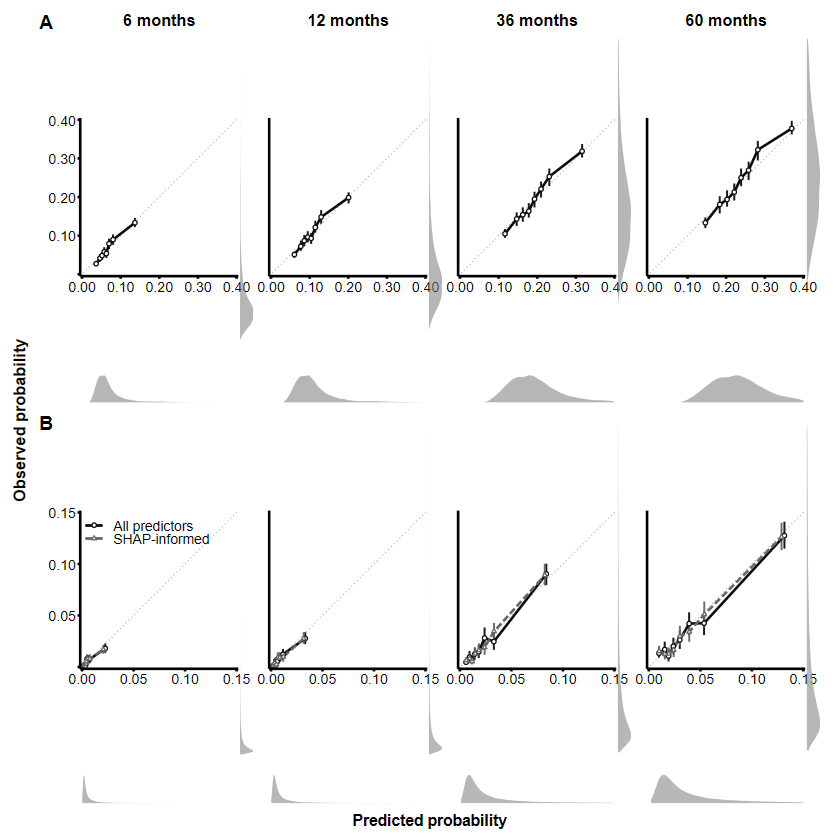

Readmission uses b + e first-event CIF; mortality uses all-cause d and e risks. Panel A shows first readmission, with observed cumulative incidence from the Aalen-Johansen estimator treating death as a competing risk. Panel B overlays the two all-cause mortality models, with observed risk from the Kaplan-Meier estimator; the two are distinguished by marker shape and line type. Points are observed against mean predicted risk within quantile groups of predicted risk (up to 8 groups; groups with fewer than 20 individuals suppressed). Error bars are pointwise 95% confidence intervals: bootstrap percentile (B = 1000, validation rows resampled). Predicted risks are the frozen held-out predictions averaged across the five imputations. The dotted line marks perfect calibration; x and y share the same range and the panels are square, so it is a true 45 degree diagonal. Shaded marginal strips show the distribution of individual predicted risks; the strip on the right projects that distribution o

Model,Variable,HR,95% CI,p-value
b,Cocaine paste (primary at admission),1.52,1.41-1.63,<0.001
b,Cocaine hydrochloride (primary at admission),1.40,1.29-1.52,<0.001
b,Alcohol (primary at admission),1.18,1.09-1.28,<0.001
b,Other substance (primary at admission),0.99,0.86-1.15,0.928
b,"Age at admission, yr",0.99,0.99-1.00,<0.001
b,Communal poverty rate,1.79,1.44-2.22,<0.001
b,Women,1.28,1.22-1.34,<0.001
b,Recorded Indigenous ethnicity,1.66,1.57-1.76,<0.001
b,"Treatment episode length, mo",1.01,1.01-1.01,<0.001
b,"Discharge evaluation, substance use: intermediate achievement",1.16,1.09-1.23,<0.001


Model,stratum,n,events,H0_6m,S0_6m,H0_12m,S0_12m,H0_36m,S0_36m,H0_60m,S0_60m
b,"m-pai, tr_outcome_adm_discharge_rule_violation_undet=0",3956,895,0.0336,0.9670,0.0577,0.9439,0.1057,0.8997,0.1282,0.8797
b,"m-pai, tr_outcome_adm_discharge_rule_violation_undet=1",246,79,0.0535,0.9479,0.0779,0.9251,0.1246,0.8829,0.1536,0.8576
b,"m-pr, tr_outcome_adm_discharge_rule_violation_undet=0",2510,1038,0.0766,0.9263,0.1142,0.8920,0.1844,0.8316,0.2148,0.8067
b,"m-pr, tr_outcome_adm_discharge_rule_violation_undet=1",319,145,0.1233,0.8840,0.1555,0.8560,0.2103,0.8104,0.2393,0.7872
b,"pg-pab, tr_outcome_adm_discharge_rule_violation_undet=0",24242,4409,0.0273,0.9731,0.0460,0.9551,0.0939,0.9104,0.1211,0.8860
b,"pg-pab, tr_outcome_adm_discharge_rule_violation_undet=1",1572,411,0.0496,0.9516,0.0715,0.9310,0.1239,0.8835,0.1554,0.8561
b,"pg-pai, tr_outcome_adm_discharge_rule_violation_undet=0",27904,5342,0.0287,0.9717,0.0491,0.9521,0.0968,0.9077,0.1246,0.8829
b,"pg-pai, tr_outcome_adm_discharge_rule_violation_undet=1",2033,575,0.0429,0.9580,0.0709,0.9315,0.1288,0.8791,0.1583,0.8536
b,"pg-pr, tr_outcome_adm_discharge_rule_violation_undet=0",6708,1957,0.0545,0.9469,0.0840,0.9195,0.1443,0.8656,0.1770,0.8377
b,"pg-pr, tr_outcome_adm_discharge_rule_violation_undet=1",1031,396,0.1024,0.9027,0.1414,0.8681,0.1980,0.8203,0.2348,0.7908


Elapsed: 0.412 minutes


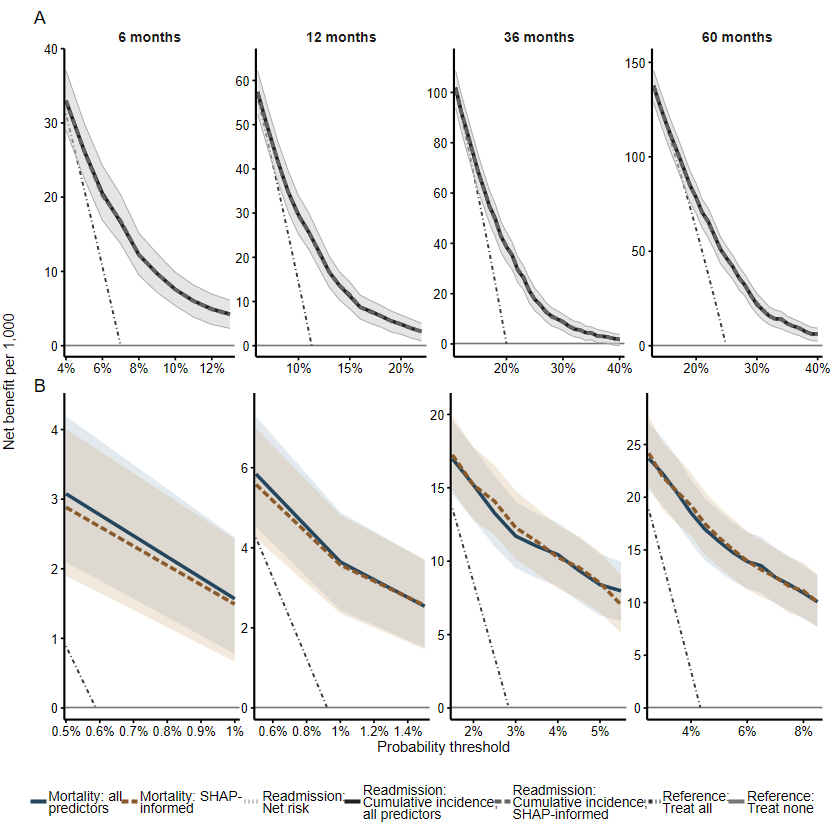

In [23]:
#| label: eval-publication-tables-and-figures
#| message: false
.t0 <- proc.time()
publication_stems<-c(etable13_csv="eTable13_Cox_coefficients.csv",etable14_csv="eTable14_stratum_baselines.csv",figure3_bins_csv="Figure3_calibration_bins.csv",figure4_curves_csv="Figure4_DCA_curves.csv",figure3_png="Figure3_holdout_calibration.png",figure3_pdf="Figure3_holdout_calibration.pdf",figure3_tiff="Figure3_holdout_calibration.tiff",figure4_png="Figure4_holdout_DCA.png",figure4_pdf="Figure4_holdout_DCA.pdf",figure4_tiff="Figure4_holdout_DCA.tiff")
publication_paths<-lapply(publication_stems,function(s) {
  group<-if(grepl("[.]csv$",s))"tables" else "figures"
  output_file(group,sub("([.][^.]+)$",paste0("_",Sys.Date(),"_",analysis_signature,"\\1"),s))
})
# Required: frozen_models, formulas, train_list, cal_results, dca_results and configured publication_paths.
stopifnot(all(c("b", "d", "e") %in% names(frozen_models$net)), all(c("b", "d", "e") %in% names(formulas)))
hr_tables <- lapply(frozen_models$net[c("b", "d", "e")], p23_pool_cached_hr)
baseline_tables <- stats::setNames(lapply(c("b", "d", "e"), function(model) p23_cached_baseline(formulas[[model]], train_list, frozen_models$net[[model]])), c("b", "d", "e"))
etable13_numeric <- do.call(rbind, lapply(names(hr_tables), function(model) cbind(Model = model, hr_tables[[model]]$numeric)))
etable13_display <- do.call(rbind, lapply(names(hr_tables), function(model) cbind(Model = model, hr_tables[[model]]$display)))
etable14 <- do.call(rbind, lapply(names(baseline_tables), function(model) cbind(Model = model, baseline_tables[[model]])))
figure3 <- p23_figure3(cal_results)
figure4 <- p23_figure4(dca_results)
print(figure3$plot)
print(figure4$plot)
# Use the notebook's browsable scrollbox table helper for etable13_display and etable14.
# Every path below must come from the shared configuration, including the dated output names.
required_paths <- c("etable13_csv", "etable14_csv", "figure3_bins_csv", "figure4_curves_csv", "figure3_png", "figure3_pdf", "figure3_tiff", "figure4_png", "figure4_pdf", "figure4_tiff")
stopifnot(all(required_paths %in% names(publication_paths)))
utils::write.csv(etable13_numeric, publication_paths$etable13_csv, row.names = FALSE, na = "")
utils::write.csv(etable14, publication_paths$etable14_csv, row.names = FALSE, na = "")
utils::write.csv(figure3$bins, publication_paths$figure3_bins_csv, row.names = FALSE, na = "")
utils::write.csv(figure4$table, publication_paths$figure4_curves_csv, row.names = FALSE, na = "")
ggplot2::ggsave(publication_paths$figure3_png, figure3$plot, width = 17.4, height = 9.8, units = "cm", dpi = 300, device = ragg::agg_png)
ggplot2::ggsave(publication_paths$figure3_pdf, figure3$plot, width = 17.4, height = 9.8, units = "cm", device = grDevices::cairo_pdf)
ggplot2::ggsave(publication_paths$figure3_tiff, figure3$plot, width = 17.4, height = 9.8, units = "cm", dpi = 600, device = ragg::agg_tiff, compression = "lzw")
ggplot2::ggsave(publication_paths$figure4_png, figure4$plot, width = 7.2, height = 7.6, units = "in", dpi = 300, device = ragg::agg_png)
ggplot2::ggsave(publication_paths$figure4_pdf, figure4$plot, width = 7.2, height = 7.6, units = "in", device = grDevices::cairo_pdf)
ggplot2::ggsave(publication_paths$figure4_tiff, figure4$plot, width = 7.2, height = 7.6, units = "in", dpi = 600, device = ragg::agg_tiff, compression = "lzw")
cat(figure3$caption, "\n", figure4$caption, "\n")
labels<-utils::read.csv(resolve_path(config$sources$variable_labels),stringsAsFactors=FALSE)
etable13_display$Variable<-ifelse(etable13_display$Variable %in% labels$technical_name,labels$display_label[match(etable13_display$Variable,labels$technical_name)],etable13_display$Variable)
show_table(etable13_display,"eTable 13: development coefficients, pooled across five imputations")
show_table(etable14,"eTable 14: development stratum baselines and mean-imputation counts")
written_files<-unique(c(written_files,unlist(publication_paths)))
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))

In [24]:
#| label: eval-etable13-14-comparison-functions
#| message: false
.t0 <- proc.time()
# Compare saved publication tables; coefficients are not refitted and baselines are not recomputed.
p23_compare_etable13_14 <- function(etable13_numeric, etable14, history) {
  old13 <- history$eTable13
  old14 <- history$eTable14
  stopifnot(all(c("Model","term","estimate","2.5 %","97.5 %") %in% names(etable13_numeric)),all(c("Model","stratum","n","events","S0_6m","S0_60m") %in% names(etable14)))
  stopifnot(!anyDuplicated(paste(etable13_numeric$Model,etable13_numeric$term)),!anyDuplicated(paste(etable14$Model,etable14$stratum)))
  stopifnot(all(etable13_numeric$Model %in% c("b","d","e")),all(etable14$Model %in% c("b","d","e")))
  hr_rows <- term_rows <- baseline_rows <- list()
  for(model in c("b","d","e")) {
    before <- old13[old13$Model==model & old13$present,,drop=FALSE]
    after <- etable13_numeric[etable13_numeric$Model==model,,drop=FALSE]
    for(term in union(before$term,after$term)) {
      a <- before[before$term==term,,drop=FALSE]
      z <- after[after$term==term,,drop=FALSE]
      status <- if(!nrow(a)) "added" else if(!nrow(z)) "removed" else "retained"
      old <- if(nrow(a)) as.numeric(a[1,c("estimate","lower","upper")]) else rep(NA_real_,3L)
      new <- if(nrow(z)) as.numeric(z[1,c("estimate","2.5 %","97.5 %")]) else rep(NA_real_,3L)
      label_row <- old13[old13$Model==model & old13$term==term,,drop=FALSE]
      label <- if(nrow(label_row)) label_row$Word_label[1L] else term
      word_cell <- if(nrow(label_row)) label_row$word_cell[1L] else NA_character_
      classification <- if(status=="retained") ifelse(round(new,2)==round(old,2),"trivial","substantial") else rep("substantial",3L)
      hr_rows[[length(hr_rows)+1L]] <- data.frame(target="eTable13",Model=model,term=term,Word_label=label,status=status,component=c("estimate","lower","upper"),manuscript=old,new_pipeline=new,difference=new-old,digits=2L,classification=classification,word_cell=word_cell,stringsAsFactors=FALSE)
      term_rows[[length(term_rows)+1L]] <- data.frame(Model=model,term=term,Word_label=label,status=status,any_published_value_changed=any(classification=="substantial"),stringsAsFactors=FALSE)
    }
    before <- old14[old14$Model==model,,drop=FALSE]
    after <- etable14[etable14$Model==model,,drop=FALSE]
    for(stratum in union(before$stratum,after$stratum)) {
      a <- before[before$stratum==stratum,,drop=FALSE]
      z <- after[after$stratum==stratum,,drop=FALSE]
      status <- if(!nrow(a)) "added" else if(!nrow(z)) "removed" else "retained"
      metrics <- c("n","events","Risk_6m_percent","Risk_60m_percent")
      digits <- c(0L,0L,2L,2L)
      if(nrow(a)) {stopifnot(nrow(a)==4L,setequal(a$metric,metrics));a<-a[match(metrics,a$metric),,drop=FALSE]}
      old <- if(nrow(a)) a$manuscript else rep(NA_real_,4L)
      new <- if(nrow(z)) c(z$n,z$events,100*(1-z$S0_6m),100*(1-z$S0_60m)) else rep(NA_real_,4L)
      classification <- if(status=="retained") ifelse(round(new,digits)==round(old,digits),"trivial","substantial") else rep("substantial",4L)
      baseline_rows[[length(baseline_rows)+1L]] <- data.frame(target="eTable14",Model=model,stratum=stratum,Word_label=if(nrow(a))a$Word_label else stratum,status=status,component=metrics,manuscript=old,new_pipeline=new,difference=new-old,digits=digits,classification=classification,word_cell=if(nrow(a))a$word_cell else NA_character_,stringsAsFactors=FALSE)
    }
  }
  list(eTable13=do.call(rbind,hr_rows),eTable13_terms=do.call(rbind,term_rows),eTable14=do.call(rbind,baseline_rows))
}
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))

Elapsed: 0.000 minutes


In [25]:
#| label: eval-etable13-14-previous-versus-current
#| message: false
.t0 <- proc.time()
# Place after eval-publication-tables-and-figures; add the history JSON path to shared config.
etable_history <- jsonlite::read_json(resolve_path(config$sources$holdout_etable13_14_history),simplifyVector=TRUE)
stopifnot(identical(digest::digest(file=resolve_path(config$sources$manuscript),algo="sha256"),etable_history$manuscript_sha256),identical(digest::digest(file=resolve_path(config$sources$holdout_original_notebook),algo="sha256"),etable_history$original_sha256))
etable_comparison <- p23_compare_etable13_14(etable13_numeric,etable14,etable_history)
eTable13_comparison <- etable_comparison$eTable13
eTable13_term_changes <- etable_comparison$eTable13_terms
eTable14_comparison <- etable_comparison$eTable14
show_table(eTable13_term_changes,"eTable 13: retained, added and removed coefficient terms in models b, d and e")
show_table(eTable13_comparison,"eTable 13: current pooled hazard ratios and intervals versus the manuscript")
show_table(eTable14_comparison,"eTable 14: n/events and baseline net-risk percentages versus the manuscript")
invisible(write_table(eTable13_term_changes,"eTable13_term_inventory"))
invisible(write_table(eTable13_comparison,"eTable13_previous_vs_clean"))
invisible(write_table(eTable14_comparison,"eTable14_previous_vs_clean"))
eTable13_substantial_values <- sum(eTable13_comparison$classification=="substantial")
eTable14_substantial_model_values <- sum(eTable14_comparison$classification=="substantial")
eTable14_substantial_word_cells <- length(unique(stats::na.omit(eTable14_comparison$word_cell[eTable14_comparison$classification=="substantial"])))
cat("Added/removed coefficients are specification changes, not zeros or missing patient data. Historical HR values are available at the published precision only.\n")
cat("Baseline risks use 100*(1-S0) from the original four-decimal S0 table. The shared first-block n cells are linked to both b and d; unique Word-cell counts avoid double counting.\n")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))

Model,term,Word_label,status,any_published_value_changed
b,adm_age_rec3,Age at admission (years),retained,FALSE
b,sex_rec_woman,Sex (woman),retained,FALSE
b,occupation_condition_corr24_unemployed,Occupational status: Unemployed,retained,FALSE
b,occupation_condition_corr24_inactive,Occupational status: Inactive,retained,FALSE
b,porc_pobr,Communal poverty index,retained,FALSE
b,ed_attainment_corr_3_completed_primary_school_or_less,Educational attainment: Up to primary complete,retained,FALSE
b,ed_attainment_corr_2_completed_high_school_or_less,Educational attainment: Up to secondary complete,retained,FALSE
b,ethnicity,Ethnicity,retained,FALSE
b,dg_psiq_cie_10_dgTRUE,Psychiatric comorbidity (ICD-10),retained,FALSE
b,sub_dep_icd10_status_drug_dependence,SUD severity (drug dependence),retained,FALSE


target,Model,term,Word_label,status,component,manuscript,new_pipeline,difference,digits,classification,word_cell
eTable13,b,adm_age_rec3,Age at admission (years),retained,estimate,0.99,0.9941,0.0041,2,trivial,eTable13:r1:c1
eTable13,b,adm_age_rec3,Age at admission (years),retained,lower,0.99,0.9923,0.0023,2,trivial,eTable13:r1:c1
eTable13,b,adm_age_rec3,Age at admission (years),retained,upper,1.00,0.9959,-0.0041,2,trivial,eTable13:r1:c1
eTable13,b,sex_rec_woman,Sex (woman),retained,estimate,1.28,1.2793,-0.0007,2,trivial,eTable13:r2:c1
eTable13,b,sex_rec_woman,Sex (woman),retained,lower,1.22,1.2213,0.0013,2,trivial,eTable13:r2:c1
eTable13,b,sex_rec_woman,Sex (woman),retained,upper,1.34,1.3401,0.0001,2,trivial,eTable13:r2:c1
eTable13,b,occupation_condition_corr24_unemployed,Occupational status: Unemployed,retained,estimate,1.07,1.0665,-0.0035,2,trivial,eTable13:r10:c1
eTable13,b,occupation_condition_corr24_unemployed,Occupational status: Unemployed,retained,lower,1.03,1.0261,-0.0039,2,trivial,eTable13:r10:c1
eTable13,b,occupation_condition_corr24_unemployed,Occupational status: Unemployed,retained,upper,1.11,1.1084,-0.0016,2,trivial,eTable13:r10:c1
eTable13,b,occupation_condition_corr24_inactive,Occupational status: Inactive,retained,estimate,1.01,1.0140,0.0040,2,trivial,eTable13:r11:c1


target,Model,stratum,Word_label,status,component,manuscript,new_pipeline,difference,digits,classification,word_cell
eTable14,b,"m-pai, tr_outcome_adm_discharge_rule_violation_undet=0","m-pai, rule violation = no",retained,n,3956.00,3956.00,0.00,0,trivial,eTable14:r2:c1
eTable14,b,"m-pai, tr_outcome_adm_discharge_rule_violation_undet=0","m-pai, rule violation = no",retained,events,895.00,895.00,0.00,0,trivial,eTable14:r2:c2
eTable14,b,"m-pai, tr_outcome_adm_discharge_rule_violation_undet=0","m-pai, rule violation = no",retained,Risk_6m_percent,3.30,3.30,0.00,2,trivial,eTable14:r2:c3
eTable14,b,"m-pai, tr_outcome_adm_discharge_rule_violation_undet=0","m-pai, rule violation = no",retained,Risk_60m_percent,12.03,12.03,0.00,2,trivial,eTable14:r2:c4
eTable14,b,"m-pai, tr_outcome_adm_discharge_rule_violation_undet=1","m-pai, rule violation = yes",retained,n,246.00,246.00,0.00,0,trivial,eTable14:r3:c1
eTable14,b,"m-pai, tr_outcome_adm_discharge_rule_violation_undet=1","m-pai, rule violation = yes",retained,events,79.00,79.00,0.00,0,trivial,eTable14:r3:c2
eTable14,b,"m-pai, tr_outcome_adm_discharge_rule_violation_undet=1","m-pai, rule violation = yes",retained,Risk_6m_percent,5.21,5.21,0.00,2,trivial,eTable14:r3:c3
eTable14,b,"m-pai, tr_outcome_adm_discharge_rule_violation_undet=1","m-pai, rule violation = yes",retained,Risk_60m_percent,14.24,14.24,0.00,2,trivial,eTable14:r3:c4
eTable14,b,"m-pr, tr_outcome_adm_discharge_rule_violation_undet=0","m-pr, rule violation = no",retained,n,2510.00,2510.00,0.00,0,trivial,eTable14:r4:c1
eTable14,b,"m-pr, tr_outcome_adm_discharge_rule_violation_undet=0","m-pr, rule violation = no",retained,events,1038.00,1038.00,0.00,0,trivial,eTable14:r4:c2


Added/removed coefficients are specification changes, not zeros or missing patient data. Historical HR values are available at the published precision only.


Baseline risks use 100*(1-S0) from the original four-decimal S0 table. The shared first-block n cells are linked to both b and d; unique Word-cell counts avoid double counting.


Elapsed: 0.010 minutes


In [26]:
#| label: eval-previous-versus-current
#| message: false
.t0 <- proc.time()
# Compare with the read-only Word extraction and separately retain pre-existing export discrepancies.
audit<-jsonlite::read_json(resolve_path(config$sources$holdout_source_audit),simplifyVector=FALSE)
word_rows<-lapply(audit$Table3_word_export_checks,function(row) {
  arm<-switch(row$source_arm,readmit_shared="readmit::netrisk",death_best_perf1="death::best_perf1",death_best_perf2="death::best_perf2",row$source_arm)
  current<-Table3_all_arms[Table3_all_arms$arm==arm & Table3_all_arms$horizon==row$horizon & Table3_all_arms$metric==row$metric,]
  stopifnot(nrow(current)==1L)
  old<-unlist(row$Word_numbers);new<-as.numeric(unlist(current[c("estimate","lower","upper")],use.names=FALSE))
  if(row$metric=="IPA") new<-100*new
  out<-data.frame(target="Table3",group=row$group,arm=arm,horizon=row$horizon,metric=row$metric,component=c("estimate","lower","upper"),manuscript=old,historical_export=unlist(row$source_values),new_pipeline=new,difference=new-old,digits=row$digits)
  out$historical_matches_word<-unlist(row$rounded_matches)
  out$classification<-ifelse(round(out$new_pipeline,out$digits)==round(out$manuscript,out$digits),"trivial","substantial")
  out
})
Table3_comparison<-do.call(rbind,word_rows)
compare_pairs<-list("Net risk vs CIF, all predictors"=c("readmit::netrisk","readmit::bp1_cif"),"Net risk vs CIF, SHAP-informed"=c("readmit::netrisk","readmit::bp2_cif"),"CIF, all predictors vs CIF, SHAP-informed"=c("readmit::bp1_cif","readmit::bp2_cif"),"All predictors vs SHAP-informed"=c("death::best_perf1","death::best_perf2"))
eTable15_comparison<-do.call(rbind,lapply(audit$eTable15_word_export_checks,function(row) {
  pair<-compare_pairs[[row$comparison]]
  z<-eTable15_focus[eTable15_focus$arm_A==pair[1] & eTable15_focus$arm_B==pair[2] & eTable15_focus$horizon==row$horizon & round(eTable15_focus$threshold,6)==round(row$threshold,6),]
  stopifnot(nrow(z)==1L)
  old<-unlist(row$Word_numbers);new<-as.numeric(unlist(z[c("A_per1000","B_per1000","delta_per1000","lower","upper")],use.names=FALSE));digits<-c(2L,2L,3L,3L,3L)
  out<-data.frame(target="eTable15",comparison=row$comparison,horizon=row$horizon,threshold=row$threshold,component=c("A","B","delta","lower","upper"),manuscript=old,historical_export=unlist(row$source_values),new_pipeline=new,difference=new-old,digits=digits,historical_matches_word=unlist(row$rounded_matches))
  out$classification<-ifelse(round(new,digits)==round(old,digits),"trivial","substantial")
  out
}))
show_table(Table3_comparison,"Table 3: manuscript, historical export and clean pipeline; no Word edits")
show_table(eTable15_comparison,"eTable 15: separate old export discrepancies from new changes")
invisible(write_table(Table3_comparison,"Table3_previous_vs_clean"))
invisible(write_table(eTable15_comparison,"eTable15_previous_vs_clean"))
# Link every reported numeric component to its producer and saved comparison row.
trace_tables<-list(Table3=Table3_comparison,eTable13=eTable13_comparison,eTable14=eTable14_comparison,eTable15=eTable15_comparison)
trace_keys<-c("group","arm","Model","term","stratum","comparison","horizon","threshold","metric","component")
value_traceability<-do.call(rbind,lapply(names(trace_tables),function(target) {
  z<-trace_tables[[target]]
  source_file<-output_file("tables",paste0(target,"_previous_vs_clean_",Sys.Date(),"_",analysis_signature,".csv"))
  source_relative<-substring(normalizePath(source_file,winslash="/",mustWork=TRUE),nchar(normalizePath(project_root,winslash="/",mustWork=TRUE))+2L)
  keys<-vapply(seq_len(nrow(z)),function(i)as.character(jsonlite::toJSON(as.list(z[i,intersect(trace_keys,names(z)),drop=FALSE]),auto_unbox=TRUE,na="null")),character(1))
  data.frame(item=target,notebook=config$sources$holdout_notebook,cell=if(target %in% c("eTable13","eTable14"))"eval-etable13-14-previous-versus-current" else "eval-previous-versus-current",key=keys,output_file=source_relative,output_column="new_pipeline",output_data_row=seq_len(nrow(z)),value=z$new_pipeline,classification=z$classification)
}))
stopifnot(nrow(value_traceability)==sum(vapply(trace_tables,nrow,integer(1))),!anyDuplicated(paste(value_traceability$item,value_traceability$key)))
invisible(write_table(value_traceability,"Table3_eTables13_15_value_traceability"))
stopifnot(identical(digest::digest(file=resolve_path(config$sources$manuscript),algo="sha256"),audit$manuscript_sha256))
cat("The investigator authorized one final review of 09-11. Flags above do not select a different model or modify the manuscript.\n")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))

target,group,arm,horizon,metric,component,manuscript,historical_export,new_pipeline,difference,digits,historical_matches_word,classification
Table3,"Readmission, primary cumulative incidence",readmit::netrisk,6,C,estimate,0.660,0.6598,0.6598,-0.0002,3,TRUE,trivial
Table3,"Readmission, primary cumulative incidence",readmit::netrisk,6,C,lower,0.644,0.6440,0.6439,-0.0001,3,TRUE,trivial
Table3,"Readmission, primary cumulative incidence",readmit::netrisk,6,C,upper,0.675,0.6751,0.6754,0.0004,3,TRUE,trivial
Table3,"Readmission, primary cumulative incidence",readmit::bp1_cif,6,IBS,estimate,0.038,0.0376,0.0376,-0.0004,3,TRUE,trivial
Table3,"Readmission, primary cumulative incidence",readmit::bp1_cif,6,IBS,lower,0.035,0.0354,0.0354,0.0004,3,TRUE,trivial
Table3,"Readmission, primary cumulative incidence",readmit::bp1_cif,6,IBS,upper,0.040,0.0399,0.0399,-0.0001,3,TRUE,trivial
Table3,"Readmission, primary cumulative incidence",readmit::bp1_cif,6,IPA,estimate,2.400,2.3817,2.3817,-0.0183,1,TRUE,trivial
Table3,"Readmission, primary cumulative incidence",readmit::bp1_cif,6,IPA,lower,1.700,1.6645,1.6645,-0.0355,1,TRUE,trivial
Table3,"Readmission, primary cumulative incidence",readmit::bp1_cif,6,IPA,upper,3.000,3.0390,3.0390,0.0390,1,TRUE,trivial
Table3,"Readmission, primary cumulative incidence",readmit::bp1_cif,6,ICI,estimate,0.010,0.0102,0.0102,0.0002,3,TRUE,trivial


target,comparison,horizon,threshold,component,manuscript,historical_export,new_pipeline,difference,digits,historical_matches_word,classification
eTable15,"Net risk vs CIF, all predictors",6,0.05,A,26.070,26.0605,26.0605,-0.0095,2,FALSE,substantial
eTable15,"Net risk vs CIF, all predictors",6,0.05,B,26.280,26.2645,26.2645,-0.0155,2,FALSE,substantial
eTable15,"Net risk vs CIF, all predictors",6,0.05,delta,-0.212,-0.2040,-0.2040,0.0080,3,FALSE,substantial
eTable15,"Net risk vs CIF, all predictors",6,0.05,lower,-0.267,-0.2575,-0.2575,0.0095,3,FALSE,substantial
eTable15,"Net risk vs CIF, all predictors",6,0.05,upper,-0.159,-0.1530,-0.1530,0.0060,3,FALSE,substantial
eTable15,"Net risk vs CIF, all predictors",12,0.05,A,66.590,66.5909,66.5909,0.0009,2,TRUE,trivial
eTable15,"Net risk vs CIF, all predictors",12,0.05,B,66.650,66.6596,66.6596,0.0096,2,FALSE,substantial
eTable15,"Net risk vs CIF, all predictors",12,0.05,delta,-0.061,-0.0688,-0.0688,-0.0078,3,FALSE,substantial
eTable15,"Net risk vs CIF, all predictors",12,0.05,lower,-0.098,-0.1056,-0.1056,-0.0076,3,FALSE,substantial
eTable15,"Net risk vs CIF, all predictors",12,0.05,upper,-0.023,-0.0368,-0.0368,-0.0138,3,FALSE,substantial


The investigator authorized one final review of 09-11. Flags above do not select a different model or modify the manuscript.


Elapsed: 0.008 minutes


## Review checkpoint
```{mermaid}
flowchart TD
  A[Frozen b, e and Full mortality d] --> B[All held-out predictions checked]
  B --> C[1,000 patient resamples per estimator]
  C --> D[Table 3 and eTables 13-15; Figures 3-4]
  D --> E[Previous versus new values; rounding flags]
  E --> F[Investigator reviews the combined 09-11 delivery]
  A --> G[10-11 reuse the saved fits and development imputers]
```
No holdout result automatically changes the retained models. Original joint-G, frailty and holdout-refitted descriptive branches are outside the manuscript's primary outputs and are logged in the simplification record. Neither the Word file nor the original notebooks is edited.

## Session info

In [27]:
#| label: eval-session-info
#| message: false
.t0 <- proc.time()
# Save the actual package and session versions used in this execution.
session<-utils::sessionInfo()
print(session)
session_path<-output_file("objects",paste0("SessionInfo_09_",Sys.Date(),"_",analysis_signature,".txt"))
writeLines(capture.output(session),session_path)
written_files<-unique(c(written_files,session_path))
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))

R version 4.4.1 (2024-06-14 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26200)

Matrix products: default


locale:
[1] LC_COLLATE=C                        LC_CTYPE=English_United States.utf8
[3] LC_MONETARY=C                       LC_NUMERIC=C                       
[5] LC_TIME=C                          

time zone: America/Santiago
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

loaded via a namespace (and not attached):
 [1] gtable_0.3.6        shape_1.4.6.1       ggplot2_3.5.1      
 [4] xfun_0.57           lattice_0.22-6      Cairo_1.6-2        
 [7] vctrs_0.7.3         tools_4.4.1         Rdpack_2.6.3       
[10] ps_1.9.3            generics_0.1.3      parallel_4.4.1     
[13] tibble_3.2.1        pan_1.9             pkgconfig_2.0.3    
[16] jomo_2.7-6          Matrix_1.7-0        data.table_1.17.0  
[19] RColorBrewer_1.1-3  uuid_1.2-1          lifecycle_1.0.5    
[22] farve

Elapsed: 0.005 minutes


## Written files

In [28]:
#| label: eval-written-files-and-final-checkpoint
#| message: false
.t0 <- proc.time()
# The final cell lists actual files and their sizes; no completion is inferred from an idle kernel.
stopifnot(all(file.exists(written_files)),length(bootstrap_results)==length(jobs),all(vapply(bootstrap_results,function(x)x$B==B,logical(1))))
relative<-function(p)substring(normalizePath(p,winslash="/",mustWork=TRUE),nchar(normalizePath(project_root,winslash="/",mustWork=TRUE))+2L)
manifest<-data.frame(path=vapply(written_files,relative,character(1)),bytes=as.numeric(file.info(written_files)$size))
show_table(manifest,"Files written or reused by this notebook")
manifest_path<-output_file("tables",paste0("Table3_output_manifest_",Sys.Date(),"_",analysis_signature,".csv"))
utils::write.csv(manifest,manifest_path,row.names=FALSE)
checkpoint<-list(status="complete_pending_investigator_review",fit_signature=fit_signature,analysis_signature=analysis_signature,imputations=length(val_list),holdout_rows=nrow(val_list[[1]]),omitted=0L,bootstrap_replicates=B,bootstrap_jobs=length(bootstrap_results),Table3_substantial_values=sum(Table3_comparison$classification=="substantial"),eTable15_substantial_values=sum(eTable15_comparison$classification=="substantial"),eTable13_substantial_values=eTable13_substantial_values,eTable14_substantial_model_values=eTable14_substantial_model_values,eTable14_substantial_word_cells=eTable14_substantial_word_cells,word_unchanged=TRUE,value_traceability_rows=nrow(value_traceability),artifacts=c(manifest$path,relative(manifest_path)))
jsonlite::write_json(checkpoint,output_file("docs","09_checkpoint.json"),auto_unbox=TRUE,pretty=TRUE)
cat(jsonlite::toJSON(checkpoint,auto_unbox=TRUE),"\n")
cat(sprintf("Elapsed: %.3f minutes\n",unname((proc.time()-.t0)["elapsed"])/60))

path,bytes
outputs/objects/holdout09_fit_imp1_2026-10-10_b4602a135b5f.rds,576954892
outputs/objects/holdout09_fit_imp2_2026-10-10_b4602a135b5f.rds,576954892
outputs/objects/holdout09_fit_imp3_2026-10-10_b4602a135b5f.rds,576954892
outputs/objects/holdout09_fit_imp4_2026-10-10_b4602a135b5f.rds,576954892
outputs/objects/holdout09_fit_imp5_2026-10-10_b4602a135b5f.rds,576954892
outputs/objects/Table3_frozen_models_2026-10-10_b4602a135b5f.rds,2024018773
outputs/objects/Table3_frozen_predictions_2026-10-10_b4602a135b5f.rds,308732124
outputs/objects/Table3_historical_control_2026-10-10_02229713d19a.rds,4812
outputs/objects/Table3_resource_pilot_2026-10-10_665c51863d90.rds,628
outputs/objects/holdout09_boot_C_readmit__netrisk_1_risk_FALSE_2026-10-10_665c51863d90.rds,235837


{"status":"complete_pending_investigator_review","fit_signature":"b4602a135b5f","analysis_signature":"665c51863d90","imputations":5,"holdout_rows":17631,"omitted":0,"bootstrap_replicates":1000,"bootstrap_jobs":105,"Table3_substantial_values":45,"eTable15_substantial_values":121,"eTable13_substantial_values":71,"eTable14_substantial_model_values":10,"eTable14_substantial_word_cells":10,"word_unchanged":true,"value_traceability_rows":802,"artifacts":["outputs/objects/holdout09_fit_imp1_2026-10-10_b4602a135b5f.rds","outputs/objects/holdout09_fit_imp2_2026-10-10_b4602a135b5f.rds","outputs/objects/holdout09_fit_imp3_2026-10-10_b4602a135b5f.rds","outputs/objects/holdout09_fit_imp4_2026-10-10_b4602a135b5f.rds","outputs/objects/holdout09_fit_imp5_2026-10-10_b4602a135b5f.rds","outputs/objects/Table3_frozen_models_2026-10-10_b4602a135b5f.rds","outputs/objects/Table3_frozen_predictions_2026-10-10_b4602a135b5f.rds","outputs/objects/Table3_historical_control_2026-10-10_02229713d19a.rds","outputs/ob

Elapsed: 0.005 minutes
